# Open-Source Full-Chain Transformer-Feedback SiGe Wireline TIA with AI-Assisted Passive–Active Co-Design and a Generalized Multi-Port EM Surrogate


SPDX-License-Identifier: Apache-2.0

| Name | Affiliation | IEEE Member | SSCS Member | Email |
|-----|-----|-----|-----|-----|
| Shouqing Fu (Leader) | EPFL Lausanne & CSEM SA| Yes | Yes | shouqing.fu@csem.ch |
| Chenhao Chu | ETH Zürich | Yes | Yes | chenhao.chu@iis.ee.ethz.ch |
| Yizhou Xu | ETH Zürich | Yes | Yes | yizhxu@iis.ee.ethz.ch |
| Paulo Augusto Dal Fabbro | CSEM SA | Yes | Yes | paulo.dalfabbro@csem.ch |
| Hua Wang | ETH Zürich | Yes | Yes | hua.wang@iis.ee.ethz.ch |
| Konstantinos Manetakis (Advisor)| CSEM SA | Yes | Yes | konstantinos.manetakis@csem.ch |
| Andreas Burg (Advisor)| EPFL Lausanne | Yes | Yes | andreas.burg@epfl.ch |

## Introduction

This work presents an open-source, AI-assisted passive–active co-design workflow for a three-stage, transformer-feedback silicon-germanium (SiGe) transimpedance amplifier (TIA) in IHP SG13G2 technology [1, 2]. The workflow links parameterized layout generation, full-wave electromagnetic (EM) simulation in openEMS [3], residual neural network (ANN) surrogate modeling in PyTorch [5], and circuit-level sizing and co-optimization in ngspice [4].

A wideband optical TIA converts photodiode current into a conditioned voltage swing across heavy input parasitic capacitances [1]. While prior open-source co-design studies typically target a single passive structure, realizing a complete multi-stage TIA requires the simultaneous design of multiple heterogeneous passives alongside active transistor sizing and DC biasing. 

In the three-stage full-chain TIA (transformer-feedback input stage, shunt-feedback gain stage, and differential $50\,\Omega$ output buffer), active and passive design variables are tightly coupled:

1. **Generalized Multi-Port EM Surrogate for multi passives:** Unlike a single coil, this TIA requires three distinct passives with different port definitions and DC/RF operating conditions. The input transformer requires multi-port modeling to capture primary/secondary inductance, inter-winding capacitance, multilayer edge- and broadside-coupled windings, coupling effect, and passive loss. Simultaneously, two-port spiral inductors are required at the input ($L_1$) for photodiode capacitance peaking and at the differential output buffer ($L_b$) for $50\,\Omega$ load bandwidth extension. Therefore, a generalized multi-port EM surrogate is required for all passives to replace time-expensive full-wave EM simulator and accelerate the design loop.
2. **Coupled transistor sizing and bias selection:** Increasing SiGe HBT size or collector bias current boosts transconductance ($g_m$) to extend bandwidth, but alters base-emitter/collector capacitances, input-referred noise current, and DC voltage drops across the resistive passive windings and load resistors. Active sizing, DC bias points, and $R/C$ values must therefore be selected jointly with the physical passive geometries.
3. **End-to-end physical and time-domain closure:** Optimizing S-parameter bandwidth alone does not guarantee signal integrity under multilevel modulation. The workflow closes the loop by re-verifying the inverse-designed transformer and spiral geometries in independent full-wave EM simulations, assembling the final GDSII layouts, and evaluating transient PAM4 eye diagrams alongside transimpedance gain, bandwidth, noise, and power consumption.

To make full-chain optimization computationally tractable without running hundreds of full-wave EM solves inside the SPICE loop, we train residual ANN surrogates that map physical layout and port-placement parameters directly to broadband S-parameters. Derived electrical metrics—inductance ($L$), quality factor ($Q$), coupling coefficient ($k$), and self-resonant frequency ($f_{SR}$)—are extracted from the EM datasets to cross-check physical intuition against surrogate predictions.


## Notebook overview

1. **Full-chain TIA architecture and design targets:** Three-stage SG13G2 schematic, transformer-feedback mechanism, and testbench scope.
2. **Multi-passive parameterization:** Geometric, layer, and RF/DC port configurations for the feedback transformer and spiral inductors ($L_1$, $L_b$).
3. **Automated GDS generation, openEMS labeling, and dataset construction:** Full-wave EM extraction across multi-port and two-port structures.
4. **Physical interpretation of EM responses:** Extraction of $L$, $Q$, coupling factor $k$, and self-resonance across geometric sweeps.
5. **Residual ANN surrogate for multi passives:** Geometry-to-S-parameter surrogates and learning curves for multi passives.
6. **Active device sizing, biasing selection, and ngspice co-simulation:** HBT operating-point trade-offs, DC drops, and input-referred noise estimation.
7. **Joint passive–active inverse design:** Co-optimizing HBT bias/sizing, $R/C$ networks, transformer topology, and spiral geometries ($L_1$, $L_b$).
8. **End-to-end verification, comparison of TIA w/wo transformer, two final GDSII layouts, and PAM4 eye diagrams:** The BW comparison of TIA with and without transformer, independent full-wave EM re-simulation, AC/noise verification, and transient PAM4 signal-integrity evaluation. Two cases are studied for different applications of wide bandwidth and better eyediagram.

The script listings document layout generation, surrogate training, and circuit verification.
Command cells are opt-in; all saved figures, tables, and GDS records can be inspected directly without rerunning the simulations.

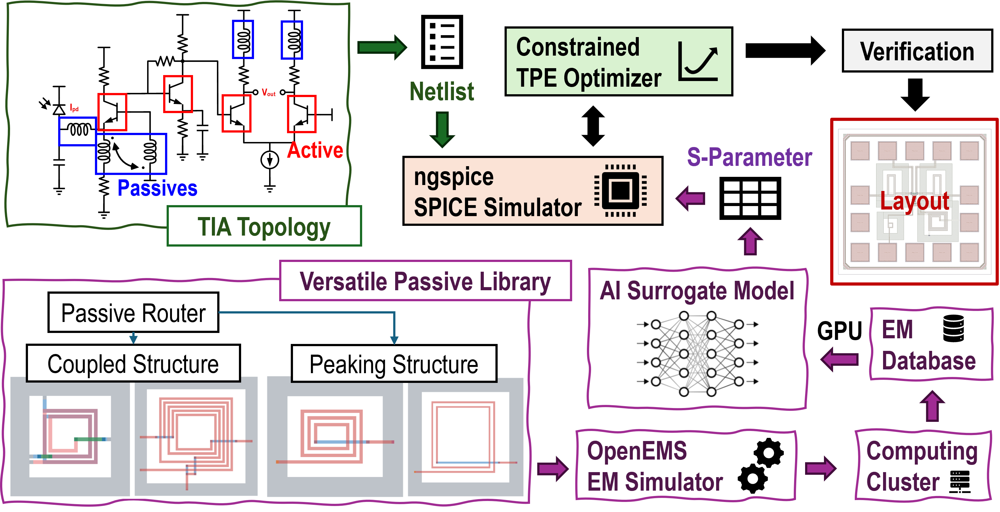

## Requirements and environment

The workflow uses Linux, Python 3.12, openEMS/CSXCAD, ngspice 47 with XSPICE/OSDI, and the IHP SG13G2 PDK. Python packages are pinned in `requirements.txt`; `tools/setup_environment.sh` builds the native dependencies and compiles the separately installed PDK models. An existing compatible toolchain can be selected with `TIA_NGSPICE_BIN` and `TIA_PDK_ROOT`.

## Environment Setup

Here, `.` denotes the current working directory of the Jupyter kernel. Run the following commands from the directory containing this notebook, where `code/`, `data/`, `tools/` and `requirements.txt` are located.

### IHP SG13G2 PDK Installation Guide

Install the IHP SG13G2 PDK separately and set `TIA_PDK_ROOT` to its checkout; PDK model sources are not included in this submission. The EM interface uses the reviewed helpers in `code/modules/` and the process stack in `code/SG13G2.xml`. Keep these copies when reproducing the workflow, as they include its port-metadata handling.

The native build requires Linux x86-64, Python 3.12 with development headers and virtual-environment support, a C/C++ compiler, CMake, Make, Git, curl, pkg-config, zlib and GMP development packages, and a Cairo runtime library. After installing the PDK, build the native tools and compile its models with:

```bash
export TIA_PDK_ROOT="/path/to/IHP-Open-PDK"
bash tools/setup_environment.sh
source tools/activate.sh
```

The script creates `.venv/`, installs the Python requirements, builds ngspice with XSPICE/OSDI and openEMS/CSXCAD under `tools/opt/`, and compiles the Verilog-A models with OpenVAF. For an existing OpenVAF installation, the model-compilation step can also be run separately:

```bash
bash tools/compile_models.sh
```

A complete upstream PDK checkout can be obtained separately from <https://github.com/IHP-GmbH/IHP-Open-PDK>. The following commands use the PDK revision recorded for this work and install the external checkout:

```bash
git clone --recursive https://github.com/IHP-GmbH/IHP-Open-PDK.git IHP-Open-PDK
git -C IHP-Open-PDK checkout 5e6d592e4002946a4616f798c357f0f3c06cf3b6
git -C IHP-Open-PDK submodule update --init --recursive
```

The upstream EM examples are under `ihp-sg13g2/libs.tech/openems/openems_ihp_sg13g2/workflow/`. This notebook already supplies the required modules and XML file in `code/`. Its `code/modules/util_simulation_setup.py` also disables the setup GUI for batch simulation:

```python
if False and 1 in excite_portnumbers:  # only for first port excitation
```

When preparing a separate upstream copy, replace `if 1 in excite_portnumbers:` with this condition to suppress the AppCSXCAD preview. Locate the condition by its text, since its line number depends on the source revision.

Choose a parent directory for generated layouts and EM data. For example:

```bash
data_path="$PWD/runs"
mkdir -p "$data_path"
```

Replace this path with a writable directory on your machine. The dataset and EM commands in Section 3 accept output paths through `--output`; layout generation creates a fresh output directory and parameter records. Create the parent directory first and let the generator create its output subdirectories. EM logs and port metadata are written beside the Touchstone files; temporary simulation directories are created automatically.

### Python Package Requirement

The main Python packages include PyTorch, NumPy, SciPy, Matplotlib, gdspy, gdstk, CairoSVG, Ray, Optuna, cmaes, scikit-rf and h5py. With an existing native toolchain, install the pinned Python dependencies and register the notebook kernel with:

```bash
python3.12 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
python -m ipykernel install --user --name tia-codesign --display-name "TIA co-design (Python 3.12)"
```

Select this kernel in Jupyter. When using an existing native installation, install the openEMS and CSXCAD Python bindings into the same virtual environment. If the native setup script has already completed, use its existing `.venv/` through `source tools/activate.sh`.

The table records the packages installed in the Python 3.12.15 environment used for this workflow, including transitive dependencies and installed utilities. Use it when checking version differences; `requirements.txt` specifies the main installation requirements. The openEMS and CSXCAD bindings are built from source by the native setup script.

| Package=Version | Package=Version | Package=Version | Package=Version | Package=Version |
|:--|:--|:--|:--|:--|
| aiohappyeyeballs=2.7.1 | aiohttp=3.14.5 | aiohttp-cors=0.8.1 | aiosignal=1.4.0 | alembic=1.20.0 |
| annotated-types=0.8.0 | asttokens=3.0.2 | attrs=26.1.0 | beautifulsoup4=4.15.0 | bleach=6.4.0 |
| cairocffi=1.7.1 | CairoSVG=2.9.1 | certifi=2026.7.22 | cffi=2.1.1 | charset-normalizer=3.5.2 |
| click=8.5.0 | clipin=1.0.0 | cmaes=0.13.1 | colorful=0.5.8 | colorlog=6.12.0 |
| comm=0.2.3 | contourpy=1.3.3 | cryptography=50.0.2 | cssselect2=0.10.1 | CSXCAD=0.7.0 |
| cycler=0.12.1 | Cython=3.3.0 | debugpy=1.8.22 | defusedxml=0.7.1 | distlib=0.4.4 |
| executing=2.3.0 | fastjsonschema=2.22.2 | filelock=3.32.3 | fonttools=4.67.0 | frozenlist=1.8.0 |
| fsspec=2026.7.0 | gdspy=1.6.13 | gdstk=1.0.2 | google-api-core=2.42.0 | google-auth=2.62.0 |
| googleapis-common-protos=1.75.5 | grpcio=1.84.0 | h5py=3.16.0 | idna=3.20 | ipykernel=7.4.0 |
| ipython=9.17.1 | ipython_pygments_lexers=1.1.1 | ipywidgets=8.1.9 | jedi=0.20.1 | Jinja2=3.1.6 |
| jsonschema=4.26.0 | jsonschema-specifications=2025.9.1 | jupyter_client=8.10.0 | jupyter_core=5.9.1 | jupyterlab_pygments=0.3.0 |
| jupyterlab_widgets=3.0.17 | kiwisolver=1.5.1 | klayout=0.30.12 | Mako=1.4.3 | MarkupSafe=3.0.3 |
| matplotlib=3.11.2 | matplotlib-inline=0.2.2 | mistune=3.3.4 | mpmath=1.3.0 | msgpack=1.2.3 |
| multidict=7.1.0 | nbclient=0.11.0 | nbconvert=7.17.2 | nbformat=5.11.1 | nest-asyncio2=1.7.4 |
| networkx=3.6.1 | ninja=1.13.2 | numpy=1.26.4 | nvidia-cublas-cu12=12.8.4.1 | nvidia-cuda-cupti-cu12=12.8.90 |
| nvidia-cuda-nvrtc-cu12=12.8.93 | nvidia-cuda-runtime-cu12=12.8.90 | nvidia-cudnn-cu12=9.10.2.21 | nvidia-cufft-cu12=11.3.3.83 | nvidia-cufile-cu12=1.13.1.3 |
| nvidia-curand-cu12=10.3.9.90 | nvidia-cusolver-cu12=11.7.3.90 | nvidia-cusparse-cu12=12.5.8.93 | nvidia-cusparselt-cu12=0.7.1 | nvidia-nccl-cu12=2.27.3 |
| nvidia-nvjitlink-cu12=12.8.93 | nvidia-nvtx-cu12=12.8.90 | opencensus=0.11.4 | opencensus-context=0.1.3 | openEMS=0.37.0.post1.dev1+g305df56aa |
| opentelemetry-api=1.45.1 | opentelemetry-exporter-prometheus=0.66b1 | opentelemetry-proto=1.45.1 | opentelemetry-sdk=1.45.1 | opentelemetry-semantic-conventions=0.66b1 |
| optuna=5.0.0 | packaging=26.3 | pandas=3.0.6 | pandocfilters=1.5.1 | parso=0.8.7 |
| pexpect=4.9.0 | pillow=12.3.0 | pip=26.2.1 | platformdirs=4.13.3 | prometheus_client=0.26.0 |
| prompt_toolkit=3.0.53 | propcache=0.5.4 | proto-plus=1.29.0 | protobuf=7.36.2 | psutil=7.2.2 |
| ptyprocess=0.7.0 | pure_eval=0.2.4 | py-spy=0.4.2 | pyasn1=0.6.4 | pyasn1_modules=0.4.2 |
| pycparser=3.11 | pydantic=2.14.1 | pydantic_core=2.50.1 | Pygments=2.21.0 | pyparsing=3.3.3 |
| python-dateutil=2.9.0.post0 | python-discovery=1.6.3 | PyYAML=6.0.3 | pyzmq=27.2.0 | ray=2.59.0 |
| referencing=0.37.0 | requests=2.34.2 | rpds-py=2026.9.1 | schemdraw=0.23 | scikit-rf=2.1.0 |
| scipy=1.17.1 | setuptools=84.0.0 | setuptools-scm=10.3.4 | six=1.17.0 | smart_open=8.0.3 |
| soupsieve=3.0.3 | spicelib=1.6.4 | SQLAlchemy=2.1.4 | stack-data=0.6.3 | sympy=1.14.0 |
| tinycss2=1.5.1 | torch=2.8.0+cu128 | torchvision=0.23.0+cu128 | tornado=6.5.10 | tqdm=4.70.1 |
| traitlets=5.16.1 | triton=3.4.0 | typing-inspection=0.4.4 | typing_extensions=4.16.0 | urllib3=2.8.0 |
| vcs-versioning=2.6.0 | virtualenv=21.14.8 | wcwidth=0.9.2 | webencodings=0.6.1 | wheel=0.48.0 |
| widgetsnbextension=4.0.16 | wrapt=2.5.1 | yarl=1.25.1 |  |  |


In [1]:
from pathlib import Path
import os
import json
import subprocess
import sys

candidates = (Path.cwd().resolve(), Path.cwd().resolve() / 'notebooks')
ROOT = next((path for path in candidates if (path / 'code/workflow.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run this notebook from the submission folder.')
sys.path.insert(0, str(ROOT / 'code'))
from environment import configure
CPU_BUDGET = configure()
RUN_GDS = False
RUN_EM = False
RUN_TRAINING = False
RUN_VERIFICATION = False
RUN_OPTIMIZATION = False


## 1. Full-chain TIA architecture and design targets

### 1.1 Full-chain TIA architecture

The implemented SG13G2 TIA comprises three stages: a transformer-feedback common-base/emitter-driven input stage, a broadband shunt-feedback voltage gain stage, and a $50\,\Omega$ back-terminated differential output buffer.

The three stages and their coupled active/passive design variables are organized as follows:

* **Input stage ($Q_1$, spiral $L_1$, feedback transformer, $R_1$, $R_2$):** The photodiode model ($I_{in} \parallel C_{pd}$) drives $Q_1$'s emitter through series peaking spiral inductor $L_1$. The transformer feedback boosts the effective high-frequency transconductance ($g_{m,\text{eff}}$) and lowers input impedance without requiring excessive DC collector current.
* **Shunt-feedback gain stage ($Q_2$, $R_F$, $R_4$, $R_3 \parallel C_1$):** $Q_2$ provides broadband amplification and impedance transformation between the high-impedance collector of $Q_1$ and the output driver.
* **Differential output buffer ($Q_3/Q_4$, spiral inductors $L_b$):** $Q_3$ and $Q_4$ convert the single-ended signal into a differential output driving external AC-coupled $50\,\Omega$ loads. Each output branch incorporates a $50\,\Omega$ on-chip back-termination resistor in series with peaking spiral inductor $L_b$ to absorb output device capacitance and maintain return loss and eye opening at high baud rates.

**Scope of the circuit testbench:** All RF signal-path transistors ($Q_1$–$Q_4$), resistive/capacitive networks, and EM-modeled passives ($L_1$, transformer, and dual $L_b$ coils) are simulated at the device/layout level in SG13G2. To keep the optimization space focused on the high-speed signal path, the saved `final_design.json` testbench uses an ideal tail current source for the output pair and an ideal low-pass replica network to bias $Q_4$'s base at the DC operating point of $Q_3$.

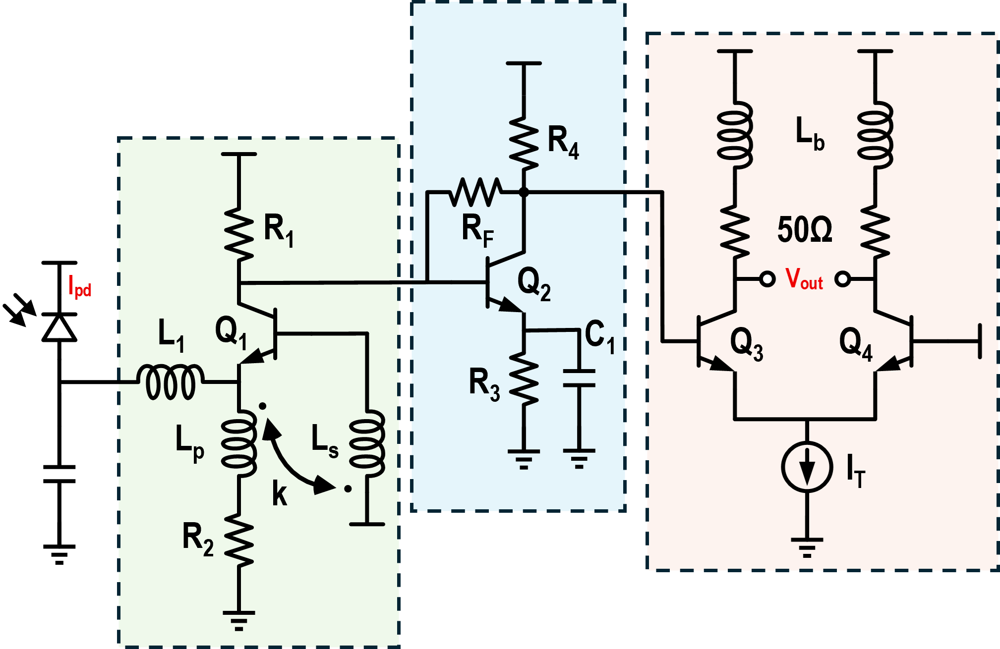

### 1.2 Transformer feedback and inductive peaking theory

High data rates in wireline links require wide bandwidth. Transformer feedback and inductive peaking aim to improve TIA bandwidth.

For a feedback connection that induces opposite-polarity base and emitter voltage variations, the effective transconductance is

$$g_m'(\omega)=g_m\left[1+n k\frac{j\omega L_p}{R_2+j\omega L_p}\right],\qquad
n=\sqrt{L_s/L_p},\qquad g_m'\longrightarrow(1+n k)g_m.$$

The feedback transition frequency is $f_x=R_2/(2\pi L_p)$. Increasing the primary inductance lowers this
frequency, but may also reduce the self-resonant frequency and increase loss. Coupling, inductance and
bias resistance must therefore be selected jointly.
The first-order input pole is $f_{in}\approx g_m'/(2\pi C_{pd})$.
L1 provides series peaking, Lb provides output shunt peaking, and $R_3\parallel C_1$ introduces another gain-stage zero.
These elements jointly determine bandwidth, gain peaking and group delay. The analytical expressions
guide the selection of design variables; the reported circuit performance is obtained from simulation.

### 1.3 Design targets

The reference metric is the differential transimpedance at 1 GHz,
$Z_T=20\log_{10}(|v_{out,p}-v_{out,n}|/|I_{in}|)$.
Bandwidth is the frequency of the first downward crossing above 1 GHz of $|Z_T(1\,\mathrm{GHz})|/\sqrt{2}$.
This defines the conventional −3 dB bandwidth.
The testbench evaluates group-delay variation over 1 GHz to $\min(BW,26\,\mathrm{GHz})$.
The input-noise estimate is the square root of the band average of the squared spectral density.
Throughout this work, all passives are iterated using EM-verified surrogate models. The active devices are represented by SPICE models.

| Quantity | Project target |
|:--|:--|
| Photodiode + pad | 220.00 fF |
| Differential transimpedance at 1 GHz | ≥ 59.00 dBΩ |
| −3 dB bandwidth | Surrogate ≥ 34.00 GHz; independent EM > 32.00 GHz; maximize |
| Gain peaking | ≤ 1.00 dB |
| Delay variation in the stated band | ≤ 10.00 ps |
| Band-averaged input-noise estimate | ≤ 21.30 pA/√Hz |
| Power at 2.50 V | ≤ 28.20 mW |



## 2. Multi-passive parameterization and port conditions

Realizing the complete TIA requires modeling passives with distinct electromagnetic and circuit boundary conditions rather than relying on a single fixed inductor template. The passive generators parameterize two structural families: **multi-port feedback transformer** and **two-port peaking spirals ($L_1$ and $L_b$)**


This Figure shows an overview of multi-passive parameterization.
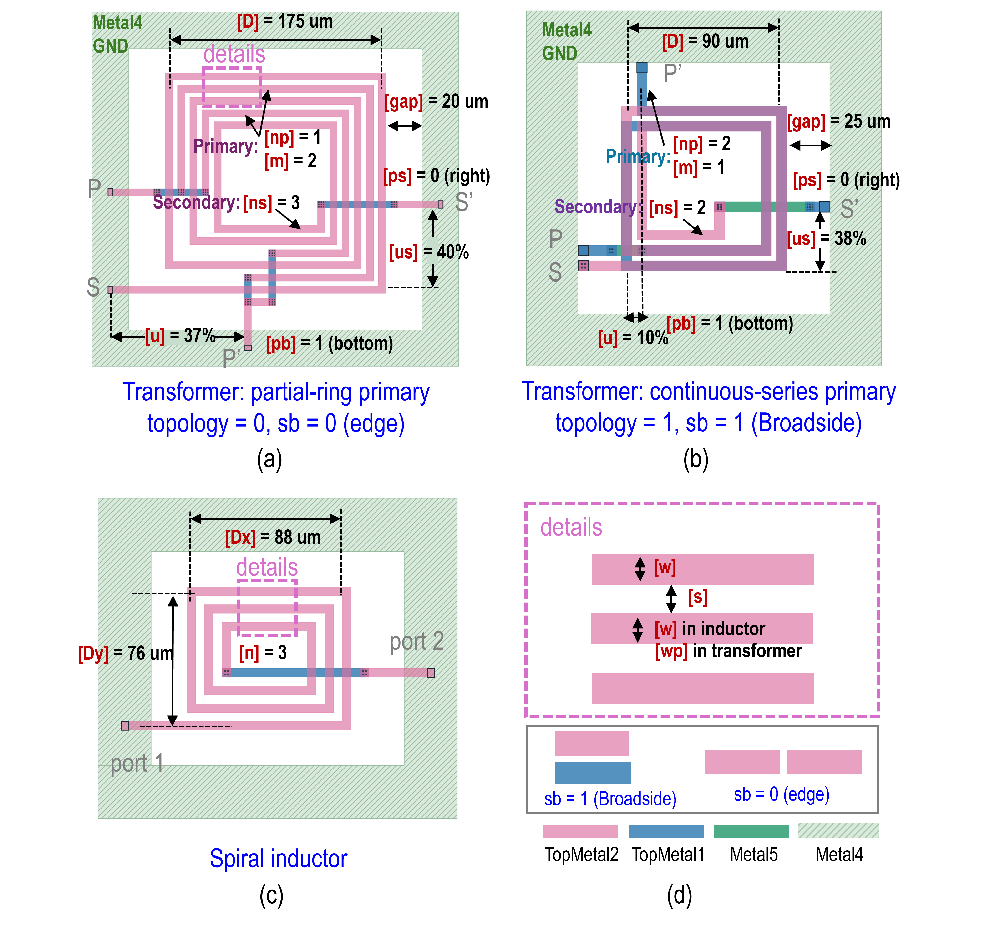

### 2.1 Multi-port transformer with selectable edge/broadside coupling and multilayer windings

Fourteen physical inputs describe the transformer winding arrangement, conductor dimensions,
parallel primary branches and terminal routing. 5 parameters are related to structures, and geometric parameters are 9. Edge-coupled windings are interleaved on the same
upper metal layer; broadside-coupled windings overlap on adjacent upper metal layers.

<table>
  <thead><tr><th>Device</th><th>Role</th><th>Parameter</th><th>Meaning</th><th>Input range or discrete values</th></tr></thead>
  <tbody>
    <tr>
      <td rowspan="14" style="vertical-align: middle;">Transformer</td>
      <td rowspan="5" style="vertical-align: middle;"><strong>structure</strong></td>
      <td>Winding and routing class <code>topology</code></td>
      <td>Primary winding construction and inner-terminal escape rule</td>
      <td>0: partial-ring primary; 1: series primary with jumped port</td>
    </tr>
    <tr>
      <td>Coupling mode <code>sb</code></td>
      <td>Physical magnetic coupling arrangement</td>
      <td>0: edge/interleaved; 1: broadside</td>
    </tr>
    <tr>
      <td>Primary return edge <code>pb</code></td>
      <td>Edge containing P′</td>
      <td>0: right; 1: bottom; 3: top</td>
    </tr>
    <tr>
      <td>Secondary return edge <code>ps</code></td>
      <td>Edge containing S′</td>
      <td>0: right; 1: bottom; 3: top</td>
    </tr>
    <tr>
      <td>Parallel primary branches <code>m</code></td>
      <td>Number of electrically parallel primary winding branches</td>
      <td>1 or 2; the direct-series class uses m = 1</td>
    </tr>
    <tr>
      <td rowspan="9" style="vertical-align: middle;">Geometry</td>
      <td>Primary return position <code>u</code></td>
      <td>P′ coordinate along its exit edge, normalized to D</td>
      <td>Integer percentage of D for new layouts, subject to lead-out geometry</td>
    </tr>
    <tr>
      <td>Secondary return position <code>us</code></td>
      <td>S′ coordinate along its exit edge, normalized to D</td>
      <td>Integer percentage of D for new layouts, subject to lead-out geometry</td>
    </tr>
    <tr>
      <td>Secondary width <code>w</code></td>
      <td>Secondary conductor width</td>
      <td>3.00–20.00 µm</td>
    </tr>
    <tr>
      <td>Primary width <code>wp</code></td>
      <td>Primary conductor width</td>
      <td>3.00–20.00 µm; direct-series via landings require at least 5.00 µm</td>
    </tr>
    <tr>
      <td>Spacing <code>s</code></td>
      <td>Clear spacing between winding tracks</td>
      <td>2.00–6.00 µm</td>
    </tr>
    <tr>
      <td>Secondary winding passes <code>ns</code></td>
      <td>Nominal secondary winding count</td>
      <td>1–4; terminal fraction follows the winding rule</td>
    </tr>
    <tr>
      <td>Primary winding passes <code>np</code></td>
      <td>Nominal primary winding count per parallel branch</td>
      <td>1–4; partial-ring and parallel-primary layouts use np = 1; direct series requires np ≥ 2</td>
    </tr>
    <tr>
      <td>Outer dimension <code>D</code></td>
      <td>Outer square center-line side</td>
      <td>30.00–200.00 µm</td>
    </tr>
    <tr>
      <td>Ground clearance <code>gap</code></td>
      <td>Nominal winding/escape-envelope clearance to the ground window</td>
      <td>20.00–35.00 µm</td>
    </tr>
  </tbody>
</table>

The transformer surrogate uses fourteen inputs in the order
`topology, sb, pb, ps, m, u, us, w, wp, s, ns, np, D, gap`.
Conductor widths (`w`, `wp`), spacing (`s`), outer dimension (`D`) and clearance (`gap`) are expressed in µm; `u` and `us` are terminal positions
specified as integer percentages of `D` for newly generated layouts. The remaining inputs specify topology, coupling and return-edge
codes or winding and branch counts.

The canonical port order is `P, P′, S, S′`. `P` and `S` are placed on the left side of the layout and close to each other,
with `P` above `S`, to provide adjacent access for transistor connections. `P′` and `S′` have flexible locations. The pairs `(pb, u)` and `(ps, us)` describe the
return-terminal edge and position of `P′` and `S′`, respectively. Return routing uses the right,
bottom or top edge, keeping the left side available for `P` and `S`.

For a right-edge return, the normalized position is `100*y/D`; for a bottom- or top-edge return, it is
`100*x/D`. Coordinates are measured at the center of the GDS terminal marker relative to the
winding square `[0,D] × [0,D]`. External leads may extend beyond this square, so a normalized
coordinate need not lie between 0% and 100%.

For `topology=0`, the primary comprises one or two electrically parallel partial-ring branches
(`m=1` or `m=2`), each assigned one nominal winding pass (`np=1`). A partial-ring pass need not
complete a 360° turn. For `topology=1`, the continuous-series primary has one branch (`m=1`)
and at least two nominal passes (`np≥2`); the jumped-port implementation uses broadside coupling and a M5 line needs to be used to bring out the ports.


The generator listings show geometry and parameter-record creation. The executable files in `code/` also contain preview exports.

**`xfmr_gen.py`**

<details>
<summary>Reference source listing</summary>

```python
# xfmr_gen.py: SG13G2 edge/broadside transformer with m parallel partial-ring primary branches.
# Primary: clockwise TM2 (edge) or TM1 (broadside); secondary: ns counter-clockwise TM2 turns plus a partial turn.
# P/Pbar/S/Sbar connect to e1/R2/Q1 base/Vb; broadside returns exit at the bottom.
import json
import gdspy
import os
import random
import sys

TM1, TV2, TM2, M4 = 126, 133, 134, 50
PORT_LAYERS = (201, 202, 203, 204)
GND_MARGIN = 20   # Coil-to-ground clearance (um).
GND_WIDTH = 30
PORT_LEN = 4
D_MIN, D_MAX = 30, 200
U_MIN, U_MAX = 10, 70
W_MIN, W_MAX = 3, 20
KEYS = ('w', 's', 'ns', 'm', 'D', 'pb', 'sb', 'u', 'wp')

data_path = os.path.dirname(os.path.abspath(__file__)) + '/'
gdspy.library.use_current_library = False
lib = gdspy.GdsLibrary(name='BatchGen_Xfmr')
lib.precision = 5e-9


def via_array(cx, cy, sx, sy, size=0.9, space=1.06, enc=0.5, layer=TV2):
	nx = int((sx - 2 * enc + space) // (size + space))
	ny = int((sy - 2 * enc + space) // (size + space))
	x0 = cx - (nx * (size + space) - space) / 2
	y0 = cy - (ny * (size + space) - space) / 2
	return [gdspy.Rectangle((x0 + i * (size + space), y0 + j * (size + space)),
							(x0 + i * (size + space) + size, y0 + j * (size + space) + size), layer=layer)
			for i in range(nx) for j in range(ny)]


def via_stack(cx, cy, w):
	return [gdspy.Rectangle((cx - w / 2, cy - w / 2), (cx + w / 2, cy + w / 2), layer=l) for l in (TM1, TM2)] \
		+ via_array(cx, cy, w, w)


def offsets(w, s, ns, m, stack=0, wp=None):
	"""Pitch and winding offsets; broadside TM1 primaries share the outer TM2 secondary center lines."""
	p = max(w, w if wp is None else wp) + s
	if stack:
		return p, [t * p for t in range(int(ns))], [k * p for k in range(int(m))]
	kinds = []
	for t in range(int(ns)):
		kinds.append('S')
		if t < m:
			kinds.append('P')
	o = [i * p for i, c in enumerate(kinds) if c == 'S']
	q = [i * p for i, c in enumerate(kinds) if c == 'P']
	return p, o, q


def is_valid(w, s, ns, m, D, pb=0, sb=0, u=50, wp=None):
	wp = w if wp is None else wp
	p, o, q = offsets(w, s, ns, m, sb, wp)
	if not (W_MIN <= w <= W_MAX and W_MIN <= wp <= W_MAX and s >= 2 and 1 <= ns <= 3 and 1 <= m <= min(2, ns)
			and D_MIN <= D <= D_MAX and pb in (0, 1) and sb in (0, 1) and U_MIN <= u <= U_MAX):
		return False
	if sb and not pb:      # Broadside returns both exit down (pb=1).
		return False
	fr = frame(w, s, ns, m, D, pb, sb, u, wp)
	if D - 2 * fr['oe'] < max(3 * p, 10):         # Inner secondary opening.
		return False
	if sb:          # Keep Sbar left of Pbar and clear of the inner turn.
		return fr['x_se'] >= fr['oe'] + 2 * p and min(fr['x_pe']) >= q[-1] + 2 * p and max(fr['x_pe']) <= D - q[-1] - 2 * p
	if pb == 0:     # Keep Pbar three pitches from Sbar and below the ring top.
		return fr['y_pe'][-1] >= fr['y_e'] + 3 * p and fr['y_pe'][0] <= D - q[-1] - 2 * p
	# Bound Pbar between the primary start and right edge.
	return fr['x_pe'][0] >= q[-1] + 2 * p and fr['x_pe'][-1] <= D - q[-1] - 2 * p


def frame(w, s, ns, m, D, pb=0, sb=0, u=50, wp=None):
	"""Winding offsets, terminals and coil bounds; pb selects right or bottom primary returns."""
	wm = max(w, w if wp is None else wp)
	p, o, q = offsets(w, s, ns, m, sb, wp)
	oe = o[-1] + p                                  # Final partial-turn offset.
	bx0, bx1, by0, by1 = -p - wm / 2, D + p + wm / 2, (-p - wm / 2 if pb else -wm / 2), D + wm / 2
	g = GND_MARGIN + GND_WIDTH / 2
	sg = -1 if sb else 1                            # Offset the inner TM1 return to avoid the outer ring.
	x_pe = [u / 100 * D + sg * 2 * p * j for j in range(m)]
	return dict(p=p, o=o, q=q, oe=oe, bbox=(bx0, by0, bx1, by1), xpl=bx0 - g, xpr=bx1 + g, ypb=by0 - g,
				y_u=oe + 3 * p, y_e=oe + 2 * p, y_pe=[u / 100 * D - 2 * p * j for j in range(m)], x_pe=x_pe,
				x_se=min(x_pe) - 3 * p)


def xfmr_area(geo):
	"""Bounding box of the transformer (without ground ring), um^2."""
	bx0, by0, bx1, by1 = frame(*geo)['bbox']
	return (bx1 - bx0) * (by1 - by0)


def lead(layer, a, b, w):
	"""TopMetal2 lead from a to port centre b (axis-parallel) plus the port rectangle on `layer`."""
	h = PORT_LEN / 2
	(x0, y0), (x1, y1) = a, b
	if y0 == y1:
		sg = 1 if x1 > x0 else -1
		xa, xb = sorted((x0, x1 + sg * h))
		return [gdspy.Rectangle((xa, y0 - w / 2), (xb, y0 + w / 2), layer=TM2),
				gdspy.Rectangle((x1 - h, y0 - w / 2), (x1 + h, y0 + w / 2), layer=layer)]
	sg = 1 if y1 > y0 else -1
	ya, yb = sorted((y0, y1 + sg * h))
	return [gdspy.Rectangle((x0 - w / 2, ya), (x0 + w / 2, yb), layer=TM2),
			gdspy.Rectangle((x0 - w / 2, y1 - h), (x0 + w / 2, y1 + h), layer=layer)]


def create_xfmr(w, s, ns, m, D, pb=0, sb=0, u=50, wp=None):
	wp = w if wp is None else wp
	fr = frame(w, s, ns, m, D, pb, sb, u, wp)
	p, o, q, oe, y_u, y_e = fr['p'], fr['o'], fr['q'], fr['oe'], fr['y_u'], fr['y_e']
	shapes = []
	bar = lambda x0, y0, x1, y1: gdspy.Rectangle((x0, y0), (x1, y1), layer=TM1)

	# TM2 secondary: full turns followed by a partial turn to Sbar.
	pts = [(0.0, 0.0)]
	for t, ot in enumerate(o):
		nxt = o[t + 1] if t + 1 < len(o) else oe
		pts += [(D - ot, ot), (D - ot, D - ot), (ot, D - ot), (ot, nxt)]
	pts += [(fr['x_se'], oe)] if sb else [(D - oe, oe), (D - oe, y_e)]
	shapes.append(gdspy.FlexPath(pts, w, gdsii_path=True, layer=TM2).to_polygonset())

	# Primary rings and their TM1 return underpasses.
	x_pe, y_pe = fr['x_pe'], fr['y_pe']
	ring_layer = TM1 if sb else TM2
	for k, qk in enumerate(q):
		if pb == 0:
			end = (D - qk, y_pe[k])
			route = [(D - qk, D - qk), end]
		else:
			end = (x_pe[k], qk)
			route = [(D - qk, D - qk), (D - qk, qk), end]
		shapes.append(gdspy.FlexPath([(qk, y_u), (qk, D - qk)] + route, wp, gdsii_path=True, layer=ring_layer).to_polygonset())
		if not sb:
			shapes += via_stack(qk, y_u, wp) + via_stack(*end, wp)
		if pb == 0:
			shapes.append(bar(end[0] - wp / 2, end[1] - wp / 2, D + p + wp / 2, end[1] + wp / 2))
			shapes += via_stack(D + p, end[1], wp)
		else:
			shapes.append(bar(end[0] - wp / 2, -p - wp / 2, end[0] + wp / 2, end[1] + wp / 2))
			shapes += via_stack(end[0], -p, wp)
	if m > 1 and pb == 0:
		shapes.append(gdspy.Rectangle((D + p - wp / 2, y_pe[-1] - wp / 2), (D + p + wp / 2, y_pe[0] + wp / 2), layer=TM2))
	if m > 1 and pb == 1:
		shapes.append(gdspy.Rectangle((min(x_pe) - wp / 2, -p - wp / 2), (max(x_pe) + wp / 2, -p + wp / 2), layer=TM2))
	lead_pb = lead(PORT_LAYERS[1], (D + p, y_pe[0]), (fr['xpr'], y_pe[0]), wp) if pb == 0 \
		else lead(PORT_LAYERS[1], (x_pe[0], -p), (x_pe[0], fr['ypb']), wp)

	# TM1 bar joins the primary starts below the secondary.
	shapes += via_stack(-p, y_u, wp)
	shapes.append(bar(-p, y_u - wp / 2, max(q) + wp / 2, y_u + wp / 2))
	lead_p = lead(PORT_LAYERS[0], (-p, y_u), (fr['xpl'], y_u), wp)
	# Secondary outer lead and inner TM1 return.
	lead_s = lead(PORT_LAYERS[2], (0.0, 0.0), (fr['xpl'], 0.0), w)
	if sb:       # Broadside Sbar exits down beside Pbar.
		x_se = fr['x_se']
		shapes += via_stack(x_se, oe, w) + via_stack(x_se, -p, w)
		shapes.append(bar(x_se - w / 2, -p - w / 2, x_se + w / 2, oe + w / 2))
		lead_sb = lead(PORT_LAYERS[3], (x_se, -p), (x_se, fr['ypb']), w)
	else:
		shapes += via_stack(D - oe, y_e, w)
		shapes.append(bar(D - oe - w / 2, y_e - w / 2, D + p + w / 2, y_e + w / 2))
		shapes += via_stack(D + p, y_e, w)
		lead_sb = lead(PORT_LAYERS[3], (D + p, y_e), (fr['xpr'], y_e), w)
	shapes += lead_p + lead_pb + lead_s + lead_sb

	# M4 ground ring.
	bx0, by0, bx1, by1 = fr['bbox']
	opening = gdspy.Rectangle((bx0 - GND_MARGIN, by0 - GND_MARGIN), (bx1 + GND_MARGIN, by1 + GND_MARGIN))
	outer = gdspy.Rectangle((bx0 - GND_MARGIN - GND_WIDTH, by0 - GND_MARGIN - GND_WIDTH),
							(bx1 + GND_MARGIN + GND_WIDTH, by1 + GND_MARGIN + GND_WIDTH))
	shapes.append(gdspy.boolean(outer, opening, 'not', layer=M4))
	return shapes


def repair(geo):
	"""Nearest valid layout for an optimiser proposal: fix m/pb, then enlarge D until the design rules hold."""
	geo = [int(round(v)) for v in geo]
	w, s, ns, m, D, pb, sb, u = geo[:8]
	wp = geo[8] if len(geo) > 8 else w
	m = min(m, ns, 2)
	pb = 1 if sb else pb
	for d in range(max(D, D_MIN), D_MAX + 1, 2):
		if is_valid(w, s, ns, m, d, pb, sb, u, wp):
			return [w, s, ns, m, d, pb, sb, u, wp]
	return [w, s, ns, m, D, pb, sb, u, wp]


def integer_return_positions(geo):
    """Require both return positions to lie on integer percentage points."""
    w, s, ns, m, D, pb, sb, u, *rest = geo
    if isinstance(u, bool) or u != int(u):
        return False
    fr = frame(w, s, ns, m, D, pb, sb, u, rest[0] if rest else w)
    us = 100 * (fr['x_se'] if sb else fr['y_e']) / D
    return abs(us - round(us)) <= 1e-9


def sample_params(stack_ok=True, max_attempts=100000):
	for _ in range(max_attempts):
		# w=2 leaves a single 0.9 um via that the 1 um EM mesh drops (open circuit)
		w = random.randint(W_MIN, W_MAX)
		wp = random.randint(W_MIN, W_MAX)
		s = random.randint(2, 6)
		ns = random.randint(1, 3)
		m = random.randint(1, min(2, ns))
		sb = random.randint(0, 1) if stack_ok else 0
		p, o, q = offsets(w, s, ns, m, sb, wp)
		oe = o[-1] + p
		lo = max(2 * oe + max(3 * p, 10), (oe + 5 * p + 2 * p * (m - 1)) / U_MAX * 100 + 1, D_MIN)
		if lo > D_MAX:
			continue
		D = random.randint(int(lo), D_MAX)
		pb = 1 if sb else random.randint(0, 1)
		u = random.randint(U_MIN, U_MAX)
		if is_valid(w, s, ns, m, D, pb, sb, u, wp) and integer_return_positions([w, s, ns, m, D, pb, sb, u, wp]):
			return [w, s, ns, m, D, pb, sb, u, wp]

	raise RuntimeError('No valid integer-position sample within the requested attempt budget')


def focus_params(centres, max_attempts=100000):
	"""Active-learning sample: random perturbation of one of the co-design optimum geometries."""
	for _ in range(max_attempts):
		w, s, ns, m, D, pb, sb, u, *rest = random.choice(centres)
		wp = rest[0] if rest else w
		w = min(max(w + random.randint(-2, 2), W_MIN), W_MAX)
		wp = min(max(wp + random.randint(-2, 2), W_MIN), W_MAX)
		s = min(max(s + random.randint(-1, 1), 2), 6)
		ns = min(max(ns + random.choice([0, 0, 0, -1, 1]), 1), 3)
		m = min(max(m + random.choice([0, 0, 0, -1, 1]), 1), min(2, ns))
		D = int(round(D * random.uniform(0.8, 1.2)))
		pb = pb if random.random() > 0.15 else 1 - pb
		sb = sb if random.random() > 0.1 else random.randint(0, 1)
		pb = 1 if sb else pb
		u = min(max(int(round(u)) + random.randint(-10, 10), U_MIN), U_MAX)
		if is_valid(w, s, ns, m, D, pb, sb, u, wp) and integer_return_positions([w, s, ns, m, D, pb, sb, u, wp]):
			return [w, s, ns, m, D, pb, sb, u, wp]
	raise RuntimeError('No valid integer-position focus sample within the requested attempt budget')


def merge_layer(cell, layer):
	polys = cell.get_polygons((layer, 0))
	if not polys:
		return
	cell.remove_polygons(lambda pts, l, d: l == layer)
	cell.add(gdspy.boolean([gdspy.Polygon(p) for p in polys], None, 'or', layer=layer))


def one_sample(index, geo, *, integer_positions=False):
	if integer_positions and not integer_return_positions(geo):
		raise ValueError('New samples require integer u and us percentages')
	cell = lib.new_cell(str(index))
	cell.add(create_xfmr(*geo))
	for layer in (TM1, TM2):
		merge_layer(cell, layer)

	svg_name = data_path + f'SVG_TEMP/xfmr_{os.getpid()}.svg'
	cell.write_svg(svg_name)
	cairosvg.svg2png(bytestring=open(svg_name).read().encode('utf-8'), write_to=data_path + f'PNG/{index}.png', scale=0.1)
	lib.write_gds(data_path + f'GDS/{index}.gds', [cell])
	if integer_positions:
		from generate_gds import integer_layout_inputs
		import xfmr_schema as schema
		metadata = schema.record(geo, generator='xfmr_gen.py', gds_file=f'{index}.gds')
		metadata['physical_inputs'] = integer_layout_inputs(data_path + f'GDS/{index}.gds', geo)
		metadata['parameters']['u'] = metadata['physical_inputs']['u']
		with open(data_path + f'INFO/{index}.json', 'w') as stream:
			json.dump(metadata, stream, indent=2)
	with open(data_path + f'INFO/{index}.log', 'w') as f:
		f.write(str(list(geo)) + '\nxfmr\n')
	lib.remove(cell)


if __name__ == '__main__':
	start_num = int(sys.argv[1]) if len(sys.argv) > 1 else 0
	end_num = int(sys.argv[2]) if len(sys.argv) > 2 else 1500
	random.seed(int(sys.argv[3]) if len(sys.argv) > 3 else 42)
	# Bias half the samples toward the supplied co-design geometries.
	centres = None
	if len(sys.argv) > 4 and not sys.argv[4].startswith('--'):
		import json
		best = json.load(open(sys.argv[4]))
		centres = [[r['params']['x_' + k] for k in KEYS] for r in best['top5']]
	all_focus = '--all-focus' in sys.argv
	os.chdir(data_path)
	if '--geos' in sys.argv:      # xfmr_select.py geometries; output indices start at start_num.
		import json
		geos = json.load(open(sys.argv[sys.argv.index('--geos') + 1]))
		for j, geo in enumerate(geos):
			if (start_num + j) % 100 == 0:
				print('Generating sample:', start_num + j)
			one_sample(start_num + j, geo)
		sys.exit()
	for index in range(start_num, end_num):
		if index % 100 == 0:
			print('Generating sample:', index)
		one_sample(index, focus_params(centres) if centres and (all_focus or index % 2) else sample_params(), integer_positions=True)
```

</details>


**`xfmr_series_gen.py`**

<details>
<summary>Reference source listing</summary>

```python
# xfmr_series_gen.py
"""Stacked transformer with a continuous series spiral primary on TopMetal1."""
import argparse
import json
import os

import gdspy
import numpy as np

import xfmr_gen as X
import xfmr_model as M

HERE = os.path.dirname(os.path.abspath(__file__))
M5, TV1 = 67, 125
gdspy.library.use_current_library = False
lib = gdspy.GdsLibrary(name='SeriesPrimary')
lib.precision = 5e-9


def valid(w, s, np_, ns, D):
	p = w + s
	return (5 <= w <= 10 and s >= 3 and 1 <= np_ <= 3 and 1 <= ns <= 3 and 30 <= D <= 200
			and D >= max(2 * ns + 3, 2 * np_ + 1) * p)


def via_m5_stack(cx, cy, w):
	return [gdspy.Rectangle((cx - w / 2, cy - w / 2), (cx + w / 2, cy + w / 2), layer=layer)
			for layer in (X.TM1, X.TM2, M5)] + X.via_array(cx, cy, w, w) + X.via_array(cx, cy, w, w, layer=TV1)


def paths(w, s, np_, ns, D):
	"""Return primary and secondary conductor segments for the partial-inductance screen."""
	p = w + s
	left = -2 * p - w / 2 - X.GND_MARGIN - X.GND_WIDTH / 2
	right = D + 2 * p + w / 2 + X.GND_MARGIN + X.GND_WIDTH / 2
	primary = [(left, D, -2 * p, D, 0.0, 1.0, w), (-2 * p, D, 0, D, -M.DZ, 1.0, w)]
	points = [(0, D)]
	for turn in range(np_):
		o = turn * p
		points.extend([(o, D - o), (D - o, D - o), (D - o, o), (o + p, o)])
	primary.extend([(*a, *b, -M.DZ, 1.0, w) for a, b in zip(points[:-1], points[1:])])
	primary.extend([(np_ * p, (np_ - 1) * p, np_ * p, -p, -M.DZ, 1.0, w),
						(np_ * p, -p, -2 * p, -p, -M.DZ, 1.0, w),
						(-2 * p, -p, left, -p, 0.0, 1.0, w)])

	oe = ns * p
	cx, cy, jump_x = D / 2, D / 2, D + 2 * p
	points = [(left, 0), (0, 0)]
	for turn in range(ns):
		o = turn * p
		nxt = (turn + 1) * p
		points.extend([(D - o, o), (D - o, D - o), (o, D - o), (o, nxt)])
	points.extend([(D - oe, oe), (cx, cy)])
	secondary = [(*a, *b, 0.0, 1.0, w) for a, b in zip(points[:-1], points[1:])]
	secondary.extend([(cx, cy, jump_x, cy, -M.DZ - 2.095, 1.0, w), (jump_x, cy, right, cy, 0.0, 1.0, w)])
	return primary, secondary


def estimate(geo):
	p, s = paths(*geo)
	def inductance(a, b):
		return sum(M.selfl(x) for x in a) + sum(M.mutual(a[i], a[j]) for i in range(len(a)) for j in range(len(a)) if i != j) if a is b \
			else sum(M.mutual(x, y) for x in a for y in b)
	lp, ls, mutual = inductance(p, p), inductance(s, s), inductance(p, s)
	return dict(Lp_nH=lp * 1e9, Ls_nH=ls * 1e9, k=abs(mutual) / np.sqrt(abs(lp * ls)))


def create_xfmr(w, s, np_, ns, D):
	p = w + s
	primary, secondary = paths(w, s, np_, ns, D)
	primary_points = [(-2 * p, D), (0, D)]
	for turn in range(np_):
		o = turn * p
		primary_points.extend([(o, D - o), (D - o, D - o), (D - o, o), (o + p, o)])
	primary_points.extend([(np_ * p, -p), (-2 * p, -p)])
	oe = ns * p
	cx, cy, jump_x = D / 2, D / 2, D + 2 * p
	left = -2 * p - w / 2 - X.GND_MARGIN - X.GND_WIDTH / 2
	right = D + 2 * p + w / 2 + X.GND_MARGIN + X.GND_WIDTH / 2
	secondary_points = [(left, 0), (0, 0)]
	for turn in range(ns):
		o = turn * p
		secondary_points.extend([(D - o, o), (D - o, D - o), (o, D - o), (o, o + p)])
	secondary_points.extend([(D - oe, oe), (cx, cy)])
	shapes = [gdspy.FlexPath(primary_points, w, gdsii_path=True, layer=X.TM1).to_polygonset(),
		  gdspy.FlexPath(secondary_points, w, gdsii_path=True, layer=X.TM2).to_polygonset(),
		  gdspy.FlexPath([(cx, cy), (jump_x, cy)], w, gdsii_path=True, layer=M5).to_polygonset()]
	shapes.extend(X.via_stack(-2 * p, D, w) + X.via_stack(-2 * p, -p, w))
	shapes.extend(via_m5_stack(cx, cy, w) + via_m5_stack(jump_x, cy, w))
	shapes.extend(X.lead(X.PORT_LAYERS[0], (-2 * p, D), (left, D), w))
	shapes.extend(X.lead(X.PORT_LAYERS[1], (-2 * p, -p), (left, -p), w))
	shapes.extend(X.lead(X.PORT_LAYERS[2], (0, 0), (left, 0), w))
	shapes.extend(X.lead(X.PORT_LAYERS[3], (jump_x, cy), (right, cy), w))
	bx0, by0, bx1, by1 = -2 * p - w / 2, -p - w / 2, D + 2 * p + w / 2, D + w / 2
	opening = gdspy.Rectangle((bx0 - X.GND_MARGIN, by0 - X.GND_MARGIN), (bx1 + X.GND_MARGIN, by1 + X.GND_MARGIN))
	outer = gdspy.Rectangle((bx0 - X.GND_MARGIN - X.GND_WIDTH, by0 - X.GND_MARGIN - X.GND_WIDTH),
							(bx1 + X.GND_MARGIN + X.GND_WIDTH, by1 + X.GND_MARGIN + X.GND_WIDTH))
	shapes.append(gdspy.boolean(outer, opening, 'not', layer=X.M4))
	return shapes


def write_sample(index, geo):
	cell = lib.new_cell(str(index))
	cell.add(create_xfmr(*geo))
	for layer in (X.TM1, X.TM2, M5):
		X.merge_layer(cell, layer)
	lib.write_gds(f'{HERE}/GDS/{index}.gds', [cell])
	with open(f'{HERE}/INFO/{index}.log', 'w') as f:
		f.write(str(list(geo)) + '\nxfmr\nseries_primary\n')
	lib.remove(cell)


def scan():
	candidates = []
	for w in (5, 7, 10):
		for s in (3, 5, 8):
			for np_ in (2, 3):
				for ns in (2, 3):
					for D in range(50, 151, 2):
						geo = [w, s, np_, ns, D]
						if not valid(*geo):
							continue
						m = estimate(geo)
						m['geo'] = geo
						p = w + s
						m['area_um2'] = (D + 4 * p + w) * (D + p + w)
						m['score'] = ((m['Lp_nH'] - 0.442) / 0.12) ** 2 + ((m['Ls_nH'] - 0.511) / 0.15) ** 2 + ((m['k'] - 0.433) / 0.10) ** 2 + 0.15 * m['area_um2'] / 23556
						candidates.append(m)
	candidates.sort(key=lambda r: r['score'])
	with open(f'{HERE}/results/series_candidates.json', 'w') as f:
		json.dump(candidates, f, indent=1)
	for row in candidates[:20]:
		print(row)
	for w in (5, 7, 10):
		for np_ in (2, 3):
			for ns in (2, 3):
				group = [r for r in candidates if r['geo'][:4] == [w, r['geo'][1], np_, ns]]
				if group:
					print('representative', group[0])


if __name__ == '__main__':
	parser = argparse.ArgumentParser()
	parser.add_argument('--scan', action='store_true')
	parser.add_argument('--generate', type=int, default=0)
	parser.add_argument('--start', type=int, default=93000)
	args = parser.parse_args()
	os.chdir(HERE)
	if args.scan:
		scan()
	if args.generate:
		candidates = json.load(open(f'{HERE}/results/series_candidates.json'))
		rows = []
		for w in (5, 7, 10):
			for np_ in (2, 3):
				for ns in (2, 3):
					group = [r for r in candidates if r['geo'][0] == w and r['geo'][2:4] == [np_, ns]]
					if group:
						rows.append(group[0])
		rows = rows[:args.generate]
		for i, row in enumerate(rows):
			index = args.start + i
			write_sample(index, row['geo'])
			print(index, row)
```

</details>


**`generate_gds.py`**

<details>
<summary>Reference source listing</summary>

```python
# generate_gds.py
"""SG13G2 clockwise TM1 primary, counter-clockwise TM2 secondary and M5 exits; center lines span [0,D]^2.
series_direct uses a bottom-edge exit; series_v3 uses a dogleg, subject to export policy."""
from section21_parameters import ast
import normalize as normalize_physical
import argparse
import json
from collections import defaultdict
from math import hypot
from pathlib import Path

import gdstk
import numpy as np
import xfmr_schema as XG


M4, M5, TM1, TM2, TV1, TV2 = 50, 67, 126, 134, 125, 133
PORT_LAYERS = {'P': 201, 'P-': 202, 'S': 203, 'S-': 204}
LINKS = [{M5, TV1}, {TV1, TM1}, {TM1, TV2}, {TV2, TM2}]
V1 = dict(lower=M5, upper=TM1, cut=TV1, size=.42, pitch=.84, n=4)
V2 = dict(lower=TM1, upper=TM2, cut=TV2, size=.9, pitch=1.96, n=2)
VIA_PAD = 5.  # Via pad size is independent of trace width.


def build(w=5., s=3., turns_p=3, turns_s=3, D=72., gap=20., ring_w=30.,
          name='COUPLED_RECT', wp=None, port_backing=False, primary_exit='dogleg'):
    """Build v3; w/wp are secondary/primary widths (wp defaults to w). Enable port_backing for EM."""
    if turns_p != int(turns_p) or turns_s != int(turns_s):
        raise ValueError('turn counts must be integers')
    turns_p, turns_s = int(turns_p), int(turns_s)
    wp = w if wp is None else wp
    if primary_exit not in ('dogleg', 'direct'):
        raise ValueError('primary_exit must be dogleg or direct')
    if primary_exit == 'direct' and (turns_p < 2 or wp < VIA_PAD):
        raise ValueError('Direct primary exit requires np >= 2 and wp >= 5 um for the via landing')
    wm = max(w, wp)
    p, L, c0 = wm + s, VIA_PAD, D / 2
    if min(w, wp, s, D, gap, ring_w) <= 0 or min(turns_p, turns_s) < 1:
        raise ValueError('w, s, D, gap, ring_w must be > 0 and turns >= 1')
    if c0 - p - max(L, wm) / 2 - (max(turns_p, turns_s) - 1) * p - wm / 2 < s:
        raise ValueError('D too small for this many turns / this pitch')
    if gap < wm + 2 * s + L:
        raise ValueError('gap too small for the Metal5 jumper vias')

    xa, ya = c0 - p, c0 + p / 2          # Primary inner end.
    xb, yb = c0 + p, c0 - p / 2          # Secondary inner end with M5 via stack.
    yp = 1.5 * p                         # P pad and M5 return row.
    if primary_exit == 'direct':
        xa = ya = yp = (turns_p - 1) * p
    lo, hi = -gap - wm / 2, D + gap + wm / 2
    xpl, xsl, ypt, xsr = lo + wp / 2, lo + w / 2, hi - wp / 2, hi - w / 2
    xvl = -(wp / 2 + s + L / 2)
    xvr = xsr - (w / 2 + s + L / 2)
    ports = {'P': (xpl, yp, 'A'), 'P-': (0, ypt, 'A'), 'S': (xsl, 0, 'B'), 'S-': (xsr, yb, 'B')}

    A = [(0, ypt), (0, D)]
    for k in range(turns_p):
        A += [(D - k * p, D - k * p), (D - k * p, k * p), (k * p, k * p)]
        if primary_exit != 'direct' or k != turns_p - 1:
            A.append((k * p, D - (k + 1) * p))
    if primary_exit == 'dogleg':
        A += [(xa, D - turns_p * p), (xa, ya)]
    B = [(xsl, 0)]
    for k in range(turns_s):
        B += [(D - k * p, k * p), (D - k * p, D - k * p), (k * p, D - k * p), (k * p, (k + 1) * p)]
    B += [(xb, turns_s * p), (xb, yb)]

    lib = gdstk.Library(unit=1e-6, precision=5e-9)
    cell = lib.new_cell(name)
    nets = defaultdict(list)

    def add(poly, net):
        cell.add(poly)
        if net:
            nets[net].append(poly)

    def rect(a, b, layer, net=None, dt=0):
        add(gdstk.rectangle(a, b, layer=layer, datatype=dt), net)

    def route(pts, layer, net):
        width = wp if net == 'A' else w
        # Extend traces across each via landing.
        ends = (max(width, L) / 2, max(width, L) / 2) if primary_exit == 'direct' else 'flush'
        for q in gdstk.FlexPath(pts, width, joins='miter', ends=ends, layer=layer).to_polygons():
            add(q, net)

    def via(x, y, v, net):
        width = wp if net == 'A' else w
        pad = max(L, width) if primary_exit == 'direct' else L
        for layer in (v['lower'], v['upper']):
            rect((x - pad / 2, y - pad / 2), (x + pad / 2, y + pad / 2), layer, net)
        n = v['n']
        for i in range(n):
            for j in range(n):
                xx, yy = x + (i - (n - 1) / 2) * v['pitch'], y + (j - (n - 1) / 2) * v['pitch']
                rect((xx - v['size'] / 2, yy - v['size'] / 2), (xx + v['size'] / 2, yy + v['size'] / 2), v['cut'], net)

    route(A, TM1, 'A')
    route(B, TM2, 'B')
    # Use M5 only across the windings.
    via(xa, ya, V1, 'A')
    primary_return = [(xa, ya), (xvl, yp)] if primary_exit == 'direct' else [(xa, ya), (xa, yp), (xvl, yp)]
    route(primary_return, M5, 'A')
    via(xvl, yp, V1, 'A')
    route([(xvl, yp), (xpl, yp)], TM1, 'A')
    via(xb, yb, V2, 'B')
    via(xb, yb, V1, 'B')
    route([(xb, yb), (xvr, yb)], M5, 'B')
    via(xvr, yb, V1, 'B')
    route([(xvr, yb), (xsr, yb)], TM1, 'B')
    via(xsl, 0, V2, 'B')
    for pn, (x, y, net) in ports.items():
        width = wp if net == 'A' else w
        a, b = (x - width / 2, y - width / 2), (x + width / 2, y + width / 2)
        rect(a, b, TM1, net)
        rect(a, b, TM1, dt=2)
        rect(a, b, PORT_LAYERS[pn])
        if port_backing:
            # M4 port landing meets the ground ring without a signal via.
            rect(a, b, M4)
        cell.add(gdstk.Label(pn, (x, y), layer=TM1, texttype=25), gdstk.Label(pn, (x, y), layer=PORT_LAYERS[pn], texttype=0))
    for q in gdstk.boolean(gdstk.rectangle((lo - ring_w, lo - ring_w), (hi + ring_w, hi + ring_w)),
                           gdstk.rectangle((lo, lo), (hi, hi)), 'not', layer=M4, precision=.005):
        cell.add(q)
    return lib, cell, nets, ports, dict(w=w, wp=wp, s=s, p=p, L=L, D=D, gap=gap,
                                      port_backing=bool(port_backing), primary_exit=primary_exit,
                                      lo=lo, hi=hi, paths={'A': A, 'B': B})


def _seg_dist(a, b):
    (ax0, ax1), (ay0, ay1) = sorted((a[0][0], a[1][0])), sorted((a[0][1], a[1][1]))
    (bx0, bx1), (by0, by1) = sorted((b[0][0], b[1][0])), sorted((b[0][1], b[1][1]))
    return hypot(max(bx0 - ax1, ax0 - bx1, 0), max(by0 - ay1, ay0 - by1, 0))


def _components(polys):
    box = [q.bounding_box() for q in polys]
    parent = list(range(len(polys)))

    def root(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    for i, a in enumerate(polys):
        for j in range(i):
            b = polys[j]
            if not (a.layer == b.layer or {a.layer, b.layer} in LINKS):
                continue
            (ax0, ay0), (ax1, ay1) = box[i]
            (bx0, by0), (bx1, by1) = box[j]
            if ax0 > bx1 or bx0 > ax1 or ay0 > by1 or by0 > ay1:
                continue
            if gdstk.boolean([a], [b], 'and', precision=.005):
                parent[root(i)] = root(j)
    return [root(i) for i in range(len(polys))]


def check(gds_path, nets, ports, g):
    w, s, p, L = g['w'], g['s'], g['p'], g['L']
    # Enforce pitch clearance between nonadjacent tracks and end landings.
    for net, pts in g['paths'].items():
        width = g.get('wp', w) if net == 'A' else w
        seg = list(zip(pts[:-1], pts[1:]))
        for i, a in enumerate(seg):
            for j in range(i + 2, len(seg)):
                assert _seg_dist(a, seg[j]) >= width + s - 1e-6, f'{net}: segments {i},{j} closer than the pitch'
        for a in seg[:-2]:
            assert _seg_dist(a, (pts[-1], pts[-1])) >= width / 2 + s + L / 2 - 1e-6, f'{net}: end landing too close to its winding'
    # Check stored polygons for Manhattan geometry.
    cell = gdstk.read_gds(str(gds_path)).top_level()[0]
    bad = []
    for q in cell.polygons:
        d = np.roll(q.points, -1, axis=0) - q.points
        if np.any((abs(d[:, 0]) > 1e-8) & (abs(d[:, 1]) > 1e-8)):
            bad.append(q.layer)
    assert not bad, f'non-Manhattan polygons on layers {sorted(set(bad))}'
    # Require 0.5 um via enclosure on both metals.
    for via_type in (V1, V2):
        cuts = [q for q in cell.polygons if q.layer == via_type['cut'] and q.datatype == 0]
        for metal in (via_type['lower'], via_type['upper']):
            conductor = [q for q in cell.polygons if q.layer == metal and q.datatype == 0]
            for cut in cuts:
                enclosure = gdstk.offset([cut], .5, join='miter', precision=.005)
                assert not gdstk.boolean(enclosure, conductor, 'not', precision=.005), f'via {via_type["cut"]} lacks full enclosure on metal {metal}'
    # Require two connected nets, including vias, with shared-layer clearance >= s.
    polys = nets['A'] + nets['B']
    labels = ['A'] * len(nets['A']) + ['B'] * len(nets['B'])
    groups = defaultdict(set)
    for r, n in zip(_components(polys), labels):
        groups[r].add(n)
    assert len(groups) == 2 and all(len(v) == 1 for v in groups.values()), 'windings shorted or broken'
    for lay in (M5, TM1, TM2):
        a = [q for q in nets['A'] if q.layer == lay]
        b = [q for q in nets['B'] if q.layer == lay]
        if a and b:
            near = gdstk.offset(a, s - .01, join='round', use_union=True)
            assert not gdstk.boolean(near, b, 'and', precision=.005), f'layer {lay}: A/B closer than s'
    # EM layouts need M4 port landings; visual layouts may touch the ring.
    ring = [q for q in cell.polygons if q.layer == M4]
    for pn, (x, y, net) in ports.items():
        width = g.get('wp', w) if net == 'A' else w
        pad = gdstk.rectangle((x - width / 2, y - width / 2), (x + width / 2, y + width / 2))
        if g.get('port_backing'):
            assert not gdstk.boolean([pad], ring, 'not', precision=.005), f'{pn} lacks Metal4 ground backing'
        else:
            assert not gdstk.boolean([pad], ring, 'and', precision=.005), f'{pn} overlaps the ring'
            assert gdstk.boolean(gdstk.offset([pad], .01, join='miter'), ring, 'and', precision=.001), f'{pn} does not touch the ring'
    if g.get('port_backing'):
        assert len(gdstk.boolean(ring, [], 'or', precision=.005)) == 1, 'M4 ground landings are disconnected'
    return cell


def build_from_geometry(geo, name='COUPLED_RECT'):
    """Use the shared schema; legacy shapes are delegated to their original code."""
    params = XG.normalize(geo)
    if params['topology'] in (2, 3):
        return build(w=params['w'], wp=params['wp'], s=params['s'],
                     turns_p=params['np'], turns_s=params['ns'], D=params['D'],
                     gap=params['gap'], ring_w=params['ring_w'],
                     port_backing=params['port_backing'], name=name,
                     primary_exit='direct' if params['topology'] == 3 else 'dogleg')
    if params['topology'] == 0:
        import xfmr_gen as old
        values = XG.legacy_vector(params)
        if params['sb'] == 2:
            raise ValueError('Historical sb=2 data can be trained, but its generator is not available here')
        if not old.is_valid(*values):
            raise ValueError('Invalid legacy transformer geometry')
        shapes = old.create_xfmr(*values)
    else:
        import xfmr_series_gen as old
        values = [params[k] for k in ('w', 's', 'np', 'ns', 'D')]
        if not old.valid(*values):
            raise ValueError('Invalid historical series_primary geometry')
        shapes = old.create_xfmr(*values)
    lib = gdstk.Library(unit=1e-6, precision=5e-9)
    cell = lib.new_cell(name)
    for shape in shapes:
        if shape is not None:
            cell.add(*(gdstk.Polygon(points, layer=layer, datatype=datatype)
                       for points, layer, datatype in zip(shape.polygons, shape.layers, shape.datatypes)))
    return lib, cell, None, None, None


def terminal_parameters(path,side):
    cell=gdstk.read_gds(str(path)).top_level()[0]
    result={}
    for layer,edge_key,position_key in ((202,'pb','u'),(204,'ps','us')):
        polygons=[p for p in cell.get_polygons() if p.layer==layer and p.datatype==0]
        if len(polygons)!=1:raise ValueError('Expected one return-terminal marker per winding')
        x,y=np.mean(polygons[0].points,axis=0)
        if y>side and 0<=x<=side:edge,position=3,100*x/side
        elif x>side and 0<=y<=side:edge,position=0,100*y/side
        elif y<0 and 0<=x<=side:edge,position=1,100*x/side
        elif x<0 and 0<=y<=side:edge,position=2,100*y/side
        else:raise ValueError('Terminal does not lie on an unambiguous external edge')
        result.update({edge_key:edge,position_key:float(position)})
    return result


def integer_layout_inputs(path,source):
    """Measure generated return terminals and export integer physical inputs."""
    source=XG.normalize(source)
    if source['topology'] not in (0,3):
        raise ValueError('Integer-position generation supports partial-ring and direct-exit layouts')
    physical={key:source[key] for key in ('w','wp','s','ns','m','D','gap')}
    physical.update(topology=0 if source['topology']==0 else 1,
                    sb=source['sb'],np=1 if source['topology']==0 else source['np'])
    physical.update(terminal_parameters(path,source['D']))
    for key in ('u','us'):
        value=physical[key];nearest=round(value)
        if not np.isclose(value,nearest,rtol=0,atol=1e-7):
            raise ValueError(f'{key} is not an integer percentage in the generated GDS')
        physical[key]=int(nearest)
    return normalize_physical(physical,integer_positions=True)


def save_geometry(geo, out, info=None, *, integer_positions=False):
    """Write one GDS, authoritative parameter sidecar, and optional INFO record."""
    out = Path(out)
    if integer_positions:
        payload=geo
        while isinstance(payload,dict) and 'parameters' in payload:payload=payload['parameters']
        requested=([payload['u']] if 'u' in payload else []) if isinstance(payload,dict) else list(payload)[7:8]
        if any(isinstance(value,(bool,np.bool_)) or not float(value).is_integer() for value in requested):
            raise ValueError('u must be an integer percentage, not a boolean or fraction')
    params = XG.normalize(geo)
    targets = [out, out.with_suffix('.json')]
    if info is not None:
        targets.extend([Path(info), Path(info).with_suffix('.json')])
    if any(path.exists() for path in targets):
        raise FileExistsError('Output already exists; choose another path/index to preserve existing geometry and EM data')
    lib, cell, nets, ports, geometry = build_from_geometry(params, name=out.stem)
    out.parent.mkdir(parents=True, exist_ok=True)
    lib.write_gds(str(out))
    physical=None
    if integer_positions:
        try:
            physical=integer_layout_inputs(out,params)
        except ValueError:
            out.unlink()  # This call created the file; no metadata or EM label exists yet.
            raise
    if geometry is not None:
        cell = check(out, nets, ports, geometry)
        preview(cell, ports, geometry, out.with_name(out.stem + '_preview.png'))
    metadata = XG.record(params, generator='generate_gds.py', gds_file=out.name)
    if physical is not None:
        metadata['physical_inputs']=physical
        metadata['parameters']['u']=int(params['u'])
    out.with_suffix('.json').write_text(json.dumps(metadata, indent=2) + '\n', encoding='utf-8')
    if info is not None:
        XG.write_info(info, params, generator='generate_gds.py', gds_file=out.name)
        if physical is not None:
            info_path=Path(info);lines=info_path.read_text().splitlines(keepends=True)
            values=ast.literal_eval(lines[0]);values[7]=int(params['u'])
            info_path.write_text(str(values)+'\n'+''.join(lines[1:]))
            info_path.with_suffix('.json').write_text(json.dumps(metadata,indent=2)+'\n')
    return metadata


def main():
    ap = argparse.ArgumentParser(description=__doc__.split('\n')[0])
    ap.add_argument('--w', type=float, default=5, help='line width (um)')
    ap.add_argument('--wp', type=float, help='primary width (um); defaults to secondary width --w')
    ap.add_argument('--s', type=float, default=3, help='line spacing between turns (um)')
    ap.add_argument('--np', '--turns-p', dest='np', type=int, default=3, help='series primary turns; never the legacy parallel count m')
    ap.add_argument('--ns', '--turns-s', dest='ns', type=int, default=3, help='secondary turns (legacy ns retains its original full-plus-partial convention)')
    ap.add_argument('--D', type=float, default=80, help='outer side of the centre-line square (um)')
    ap.add_argument('--gap', type=float, default=20, help='coil bbox to Metal4 ground window (um)')
    ap.add_argument('--ring-w', type=float, default=30, help='Metal4 ground ring width (um)')
    ap.add_argument('--topology', choices=list(XG.TOPOLOGIES), default='series_direct')
    ap.add_argument('--m', type=int, default=1, help='legacy parallel primary rings')
    ap.add_argument('--pb', type=int, default=0, help='legacy primary exit mode')
    ap.add_argument('--sb', type=int, default=0, help='legacy stacking mode')
    ap.add_argument('--u', type=int, default=50, help='legacy primary endpoint position (percent)')
    ap.add_argument('--port-backing', action='store_true', help='add Metal4 ground landings under v3 ports for EM simulation')
    ap.add_argument('--params', help='JSON geometry/sidecar or historical INFO log; preserves exact family semantics')
    ap.add_argument('--index', type=int, help='dataset index: write GDS/index.gds and INFO/index.log/.json; v3 ports are EM-backed')
    ap.add_argument('--root', default=str(Path(__file__).parent), help='dataset root (GDS, INFO, SPData)')
    ap.add_argument('--out', help='standalone GDS path; paired with a JSON sidecar')
    a = ap.parse_args()
    if a.index is not None and (a.index < 0 or a.out):
        ap.error('--index must be non-negative and cannot be combined with --out')
    if a.params:
        params = XG.read_info(a.params)
    else:
        params = dict(w=a.w, wp=a.wp if a.wp is not None else a.w, s=a.s,
                      ns=a.ns, D=a.D, gap=a.gap, ring_w=a.ring_w, topology=a.topology)
        if a.topology == 'legacy':
            params.update(m=a.m, pb=a.pb, sb=a.sb, u=a.u)
        else:
            params['np'] = a.np
        params = XG.normalize(params)
    if params['topology'] in (2, 3) and (a.port_backing or a.index is not None):
        params['port_backing'] = 1
    root = Path(a.root)
    if a.index is not None:
        if (root / 'SPData' / f'{a.index}.s4p').exists():
            raise FileExistsError('An EM result already uses this index; choose a new index')
        out, info = root / 'GDS' / f'{a.index}.gds', root / 'INFO' / f'{a.index}.log'
    else:
        out, info = Path(a.out or root / 'xfmr_series.gds'), None
    metadata = save_geometry(params, out, info, integer_positions=not a.params and params['topology'] in (0,3))
    print('Generated:', out)
    print('Unified parameters:', metadata['parameters'])
    print('Port order:', metadata['port_order'], 'signal layers:', metadata['port_layers'])


if __name__ == '__main__':
    main()
```

</details>


**`section21_parameters.py`**

<details>
<summary>Reference source listing</summary>

```python
# section21_parameters.py
"""Fourteen scalar inputs for partial-ring and direct-exit transformers.
Model/source topology codes are mapped separately; source records and canonical port order stay unchanged."""
import copy
import math
from numbers import Real

import numpy as np

SCHEMA = 'xfmr-physical14-two-topologies-v3'
INPUT_KEYS = ('topology', 'sb', 'pb', 'ps', 'm', 'u', 'us', 'w', 'wp', 's', 'ns', 'np', 'D', 'gap')
PHYSICAL_KEYS = tuple(key for key in INPUT_KEYS if key != 'topology')
SOURCE_KEYS = {key: key for key in PHYSICAL_KEYS}
SOURCE_KEYS.update(ps='secondary_return_edge', us='secondary_return_position_pct')
TOPOLOGY_CODES = {'legacy-partial-ring-v2': 0,
                  'series-direct-v2': 1}
TOPOLOGY_NAMES = ('parallel partial-ring primary',
                  'series primary, direct exit')
ENCODED_KEYS = INPUT_KEYS
EDGE_NAMES = ('right', 'bottom', 'left', 'top')


def normalize(parameters, *, integer_positions=False):
    """Validate model descriptors without interpreting an old generator vector."""
    if set(parameters) != set(INPUT_KEYS):
        raise ValueError('Expected exactly the fourteen physical input keys')
    values = dict(parameters)
    for key, value in values.items():
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, Real) or not math.isfinite(float(value)):
            raise ValueError(f'{key} must be a finite number')
        values[key] = float(value)
    for key in ('sb', 'pb', 'ps', 'm', 'ns', 'np', 'topology'):
        if values[key] != int(values[key]):
            raise ValueError(f'{key} must be an integer')
        values[key] = int(values[key])
    if integer_positions:
        for key in ('u', 'us'):
            if values[key] != int(values[key]):
                raise ValueError(f'{key} must be an integer percentage for new layouts')
            values[key] = int(values[key])
    if values['topology'] not in (0, 1):
        raise ValueError('Model topology must be 0=partial ring or 1=direct')
    if values['sb'] not in (0, 1):
        raise ValueError('Coupling must be edge (0) or broadside (1)')
    if any(values[key] not in range(4) for key in ('pb', 'ps')):
        raise ValueError('Return edges use right=0, bottom=1, left=2, top=3')
    if values['m'] not in (1, 2) or any(not 1 <= values[key] <= 4 for key in ('ns', 'np')):
        raise ValueError('Require m in {1,2} and nominal winding counts in 1..4')
    if any(values[key] <= 0 for key in ('w', 'wp', 's', 'D', 'gap')):
        raise ValueError('Dimensions must be positive')
    # np counts nominal passes in each branch; m counts electrically parallel
    # branches. The supported parallel-primary design uses one pass per branch.
    if (values['m'] > 1 or values['topology'] == 0) and values['np'] != 1:
        raise ValueError('Partial-ring and parallel-primary layouts require nominal np=1')
    if values['topology'] == 1 and values['m'] != 1:
        raise ValueError('The supported direct-series class has one primary branch')
    if values['topology'] == 1 and (values['np'] < 2 or values['wp'] < 5):
        raise ValueError('Direct-series via landings require np >= 2 and wp >= 5 um')
    return {key: values[key] for key in INPUT_KEYS}


def from_source_row(row):
    """Translate one validated GDS/S4P catalog row; retain its source interface."""
    if row.get('kind') != 'xfmr' or row.get('geometry_layout_type') not in TOPOLOGY_CODES:
        raise ValueError('Record is outside the two approved transformer classes')
    if not all(row.get(key) is True for key in
               ('geometry_mask', 'gds_available', 'response_available', 'dataset_active')):
        raise ValueError('Expected validated physical inputs with an active GDS/S4P pair')
    parameters = {key: row['geometry_features'][source_key] for key, source_key in SOURCE_KEYS.items()}
    parameters['topology'] = TOPOLOGY_CODES[row['geometry_layout_type']]
    parameters = normalize(parameters)
    return dict(schema=SCHEMA, sample_id=row['sample_id'], parameters=parameters,
                source_layout_type=row['geometry_layout_type'],
                source_parameters=copy.deepcopy(row['parameters']),
                source_topology=row['parameters'].get('topology'),
                source_paths=copy.deepcopy(row['paths']),
                source_metadata_sha256=copy.deepcopy(row['source_sha256']),
                source_gds_sha256=row.get('source_gds_sha256'),
                roles=list(row.get('roles', [])),
                geometry_roles=list(row.get('geometry_roles', [])),
                training_candidate=bool(row.get('geometry_training_candidate', row.get('training_candidate', False))))


def encode(parameter_records, *, integer_positions=False):
    """Return exactly fourteen scalar physical features, including binary topology."""
    records = [normalize(record, integer_positions=integer_positions) for record in parameter_records]
    return np.asarray([[record[key] for key in INPUT_KEYS] for record in records], dtype=float).reshape(-1, len(INPUT_KEYS))
```

</details>


In [2]:
from section21_parameters import INPUT_KEYS, encode

# topology, sb, pb, ps, m, u, us, w, wp, s, ns, np, D, gap
fig3_parameters = (
    (0, 0, 1, 0, 2, 37, 40, 6.0, 6.0, 4.0, 3, 1, 175.0, 20.0),  # (a)
    (0, 1, 1, 1, 1, 53, 38, 5.0, 5.0, 4.0, 1, 1, 180.0, 20.0),  # (b)
    (0, 0, 1, 0, 1, 32, 30, 7.0, 7.0, 3.0, 3, 1, 200.0, 20.0),  # (c)
    (1, 1, 3, 0, 1, 10, 38, 6.0, 6.0, 3.0, 2, 2, 90.0, 25.0),  # (d)
    (1, 1, 3, 0, 1, 15, 52, 8.0, 8.0, 4.0, 2, 3, 120.0, 30.0),  # (e)
    (1, 1, 3, 0, 1, 0, 46, 10.0, 10.0, 4.0, 4, 4, 160.0, 35.0),  # (f)
)
physical_inputs = [dict(zip(INPUT_KEYS, row, strict=True)) for row in fig3_parameters]
encoded_inputs = encode(physical_inputs, integer_positions=True)
assert encoded_inputs.shape == (6, 14)

if RUN_GDS:
    from example_layouts import build

    build(ROOT / "runs/transformer_examples", physical_inputs)


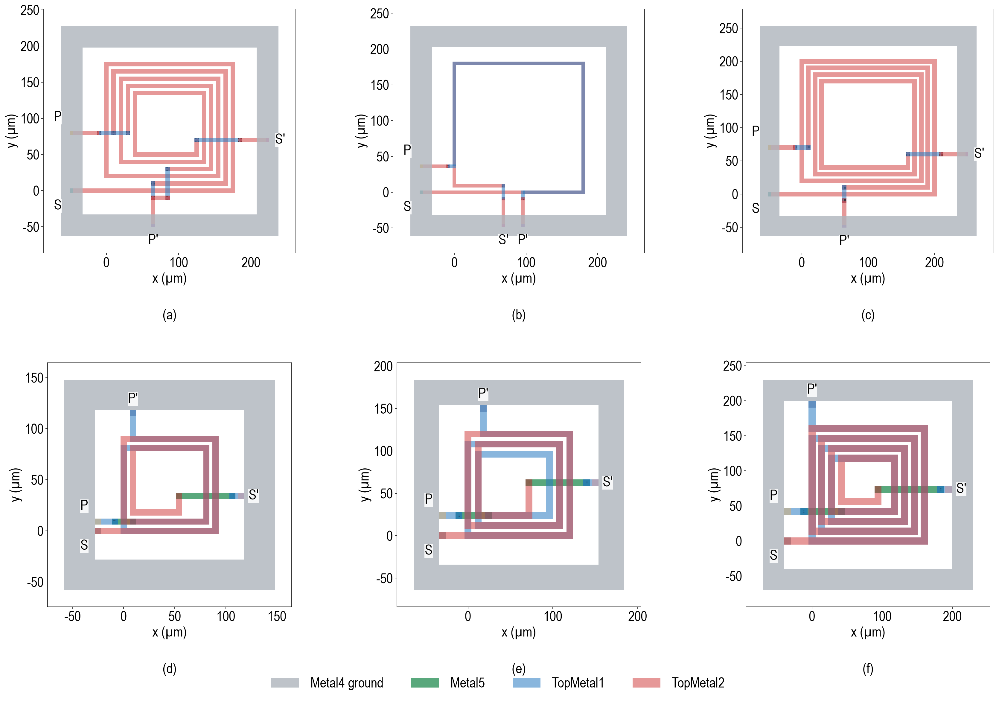


| Panel | topology | sb | pb | ps | m | u | us | w | wp | s | ns | np | D | gap |
|:--|:--|:--|:--|:--|:--|:--|:--|:--|:--|:--|:--|:--|:--|:--|
| (a) | 0 | 0 | 1 | 0 | 2 | 37 | 40 | 6.00 | 6.00 | 4.00 | 3 | 1 | 175.00 | 20.00 |
| (b) | 0 | 1 | 1 | 1 | 1 | 53 | 38 | 5.00 | 5.00 | 4.00 | 1 | 1 | 180.00 | 20.00 |
| (c) | 0 | 0 | 1 | 0 | 1 | 32 | 30 | 7.00 | 7.00 | 3.00 | 3 | 1 | 200.00 | 20.00 |
| (d) | 1 | 1 | 3 | 0 | 1 | 10 | 38 | 6.00 | 6.00 | 3.00 | 2 | 2 | 90.00 | 25.00 |
| (e) | 1 | 1 | 3 | 0 | 1 | 15 | 52 | 8.00 | 8.00 | 4.00 | 2 | 3 | 120.00 | 30.00 |
| (f) | 1 | 1 | 3 | 0 | 1 | 0 | 46 | 10.00 | 10.00 | 4.00 | 4 | 4 | 160.00 | 35.00 |



### 2.2 Individual spiral inductors

L1 and Lb use two-port spiral inductors described by `[w, s, n, Dx, Dy]`. The winding is implemented in TopMetal2, and its inner terminal is routed through a TopMetal1
underpass. The same five variables describe the inductor geometry in both circuit roles.

| Device | Parameter / key | Role | Meaning | Study range |
|:--|:--|:--|:--|:--|
| Spiral: L1 or Lb | Width `w` | Winding geometry | Conductor width | 3.00–10.00 µm |
| Spiral: L1 or Lb | Spacing `s` | Winding geometry | Clear turn-to-turn spacing | 2.00–8.00 µm |
| Spiral: L1 or Lb | Turns `n` | Winding geometry | Number of turns | 1, 2 or 3 |
| Spiral: L1 or Lb | Horizontal size `Dx` | Winding geometry | Outer horizontal center-line dimension | 20.00–150.00 µm |
| Spiral: L1 or Lb | Vertical size `Dy` | Winding geometry | Outer vertical center-line dimension | 20.00–150.00 µm |


**`spiral_gen.py`**

<details>
<summary>Reference source listing</summary>

```python
# spiral_gen.py
# SG13G2 spiral: TM2 winding, TM1 underpass, M4 ground ring and M4-to-TM2 via ports.
# Usage: python spiral_gen.py start end seed
import gdspy
import os
import random
import sys

TM1, TV2, TM2, M4 = 126, 133, 134, 50
PORT1, PORT2 = 201, 202
GND_MARGIN = 20   # Coil-to-ground clearance (um).
GND_WIDTH = 30
PORT_LEN = 4
D_MAX = 150

data_path = os.path.dirname(os.path.abspath(__file__)) + '/'
gdspy.library.use_current_library = False
lib = gdspy.GdsLibrary(name='BatchGen_SpiralL')
lib.precision = 5e-9


def via_array(cx, cy, sx, sy, size=0.9, space=1.06, enc=0.5, layer=TV2):
	nx = int((sx - 2 * enc + space) // (size + space))
	ny = int((sy - 2 * enc + space) // (size + space))
	x0 = cx - (nx * (size + space) - space) / 2
	y0 = cy - (ny * (size + space) - space) / 2
	return [gdspy.Rectangle((x0 + i * (size + space), y0 + j * (size + space)),
							(x0 + i * (size + space) + size, y0 + j * (size + space) + size), layer=layer)
			for i in range(nx) for j in range(ny)]


def via_stack(cx, cy, w):
	return [gdspy.Rectangle((cx - w / 2, cy - w / 2), (cx + w / 2, cy + w / 2), layer=l) for l in (TM1, TM2)] \
		+ via_array(cx, cy, w, w)


def spiral_points(Dx, Dy, p, n):
	pts = [(0.0, 0.0)]
	for t in range(n):
		pts += [(Dx - t * p, t * p), (Dx - t * p, Dy - t * p), (t * p, Dy - t * p), (t * p, (t + 1) * p)]
	return pts


def is_valid(w, s, n, Dx, Dy):
	p = w + s
	return w >= 3 and s >= 2 and n >= 1 and Dx >= (2 * n + 1) * p and Dy >= (2 * n + 1) * p


def create_spiral(w, s, n, Dx, Dy):
	"""Outer terminal (port 1) exits left at y=0; inner terminal (port 2) exits right via TM1 underpass."""
	p = w + s
	shapes = [gdspy.FlexPath(spiral_points(Dx, Dy, p, n), w, gdsii_path=True, layer=TM2).to_polygonset()]

	ex, ey = (n - 1) * p, n * p   # inner end
	xo = Dx + p                   # Underpass exit, one pitch beyond the outer turn.
	shapes += via_stack(ex, ey, w) + via_stack(xo, ey, w)
	shapes.append(gdspy.Rectangle((ex, ey - w / 2), (xo, ey + w / 2), layer=TM1))

	bx0, by0, bx1, by1 = -w / 2, -w / 2, xo + w / 2, Dy + w / 2
	opening = gdspy.Rectangle((bx0 - GND_MARGIN, by0 - GND_MARGIN), (bx1 + GND_MARGIN, by1 + GND_MARGIN))
	outer = gdspy.Rectangle((bx0 - GND_MARGIN - GND_WIDTH, by0 - GND_MARGIN - GND_WIDTH),
							(bx1 + GND_MARGIN + GND_WIDTH, by1 + GND_MARGIN + GND_WIDTH))
	shapes.append(gdspy.boolean(outer, opening, 'not', layer=M4))

	xp1 = bx0 - GND_MARGIN - GND_WIDTH / 2
	xp2 = bx1 + GND_MARGIN + GND_WIDTH / 2
	shapes.append(gdspy.Rectangle((xp1 - PORT_LEN / 2, -w / 2), (0, w / 2), layer=TM2))
	shapes.append(gdspy.Rectangle((xo, ey - w / 2), (xp2 + PORT_LEN / 2, ey + w / 2), layer=TM2))
	shapes.append(gdspy.Rectangle((xp1 - PORT_LEN / 2, -w / 2), (xp1 + PORT_LEN / 2, w / 2), layer=PORT1))
	shapes.append(gdspy.Rectangle((xp2 - PORT_LEN / 2, ey - w / 2), (xp2 + PORT_LEN / 2, ey + w / 2), layer=PORT2))
	return shapes


def sample_params():
	while True:
		# At w=2, the 1 um EM mesh can miss the 0.9 um via and leave an open port.
		w = random.randint(3, 10)
		s = random.randint(2, 8)
		n = random.randint(1, 3)
		lo = (2 * n + 1) * (w + s)
		if lo > D_MAX:
			continue
		Dx = random.randint(max(lo, 20), D_MAX)
		Dy = random.randint(max(lo, 20), D_MAX)
		if is_valid(w, s, n, Dx, Dy):
			return [w, s, n, Dx, Dy]


def merge_layer(cell, layer):
	polys = cell.get_polygons((layer, 0))
	if not polys:
		return
	cell.remove_polygons(lambda pts, l, d: l == layer)
	cell.add(gdspy.boolean([gdspy.Polygon(p) for p in polys], None, 'or', layer=layer))


def one_sample(index, geo):
	cell = lib.new_cell(str(index))
	cell.add(create_spiral(*geo))
	for layer in (TM1, TM2):
		merge_layer(cell, layer)

	lib.write_gds(data_path + f'GDS/{index}.gds', [cell])
	with open(data_path + f'INFO/{index}.log', 'w') as f:
		f.write(str(list(geo)) + '\nspiral\n')
	lib.remove(cell)


def focus_params(centres):
	"""Active-learning sample: random perturbation of one of the co-design optimum geometries."""
	while True:
		w, s, n, Dx, Dy = random.choice(centres)
		w = min(max(w + random.randint(-2, 2), 3), 10)
		s = min(max(s + random.randint(-2, 2), 2), 8)
		n = min(max(n + random.choice([0, 0, 0, -1, 1]), 1), 3)
		Dx = int(round(Dx * random.uniform(0.75, 1.25)))
		Dy = int(round(Dy * random.uniform(0.75, 1.25)))
		if max(Dx, Dy) <= D_MAX and is_valid(w, s, n, Dx, Dy):
			return [w, s, n, Dx, Dy]


if __name__ == '__main__':
	start_num = int(sys.argv[1]) if len(sys.argv) > 1 else 0
	end_num = int(sys.argv[2]) if len(sys.argv) > 2 else 2000
	random.seed(int(sys.argv[3]) if len(sys.argv) > 3 else 42)
	# Bias half the samples toward the supplied co-design geometries.
	centres = None
	if len(sys.argv) > 4:
		import json
		best = json.load(open(sys.argv[4]))
		centres = [[r['params'][k] for k in ('w', 's', 'n', 'Dx', 'Dy')] for r in best['top5']]
	os.chdir(data_path)
	for index in range(start_num, end_num):
		if index % 100 == 0:
			print('Generating sample:', index)
		one_sample(index, focus_params(centres) if centres and index % 2 else sample_params())
```

</details>


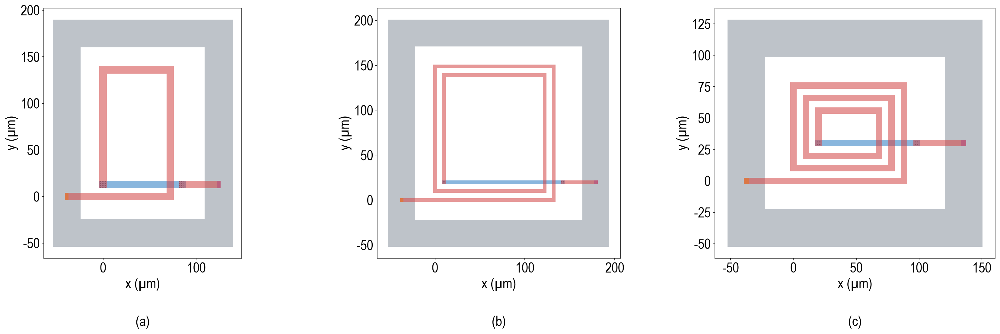

| Panel | w (µm) | s (µm) | n | Dx (µm) | Dy (µm) |
|:--|--:|--:|--:|--:|--:|
| (a) | 8.00 | 5.00 | 1.00 | 72.00 | 136.00 |
| (b) | 4.00 | 6.00 | 2.00 | 132.00 | 149.00 |
| (c) | 5.00 | 5.00 | 3.00 | 88.00 | 76.00 |


## 3. EM data generation

The layout generators export GDS files and geometry records for transformers and spiral inductors. `simulator_openems.py` combines each layout with the SG13G2 process stack and computes S-parameters at 1,001 frequencies from 0 to 100 GHz. Transformer responses are stored as four-port S4P files; spiral responses are stored as two-port S2P files.

The transformer dataset contains 1,839 records and the spiral dataset contains 1,000 records.

**`simulator_openems.py`**

<details>
<summary>Reference source listing</summary>

```python
# simulator_openems.py: transformer/spiral Touchstone extraction; all ports excited by default.
# Env: EM_MARGIN (um), EM_ENERGY (dB), EM_SKIP_PORT (optional four-port approximation).
# Usage: python simulator_openems.py -g x.gds -s x.s4p -x SG13G2.xml -m name -r workdir [--nports 4] [--preview]
import os
import sys
import argparse

from em_port_metadata import resolve_port_metadata,resolve_port_metal,validate_port_coverage



parser = argparse.ArgumentParser("parser")
parser.add_argument('-g', '--gds')
parser.add_argument('-s', '--snp')
parser.add_argument('-x', '--xml')
parser.add_argument('-m', '--model')
parser.add_argument('-r', '--script')
parser.add_argument('--nports', type=int, default=4)
parser.add_argument('--port-metal', choices=('TopMetal1', 'TopMetal2'), help='port landing metal; inferred from INFO or the GDS JSON sidecar by default')
parser.add_argument('--preview', action='store_true')
args = parser.parse_args()
try:
	PORT_DEFINITION = resolve_port_metadata(args.gds,args.script,args.port_metal,args.nports)
	validate_port_coverage(args.gds,PORT_DEFINITION)
	PORT_METAL = PORT_DEFINITION['port_layers'][0]
except (ValueError, KeyError, TypeError, OSError) as e:
	parser.error(str(e))

sys.path.insert(0, os.path.abspath(os.path.join(args.script, 'modules')))

import modules.util_stackup_reader as stackup_reader
import modules.util_gds_reader as gds_reader
import modules.util_utilities as utilities
import modules.util_simulation_setup as simulation_setup
import modules.util_meshlines as util_meshlines

from openEMS import openEMS
import numpy as np
import skrf as rf

preview_only = args.preview
postprocess_only = False

gds_filename = args.gds
XML_filename = args.xml
preprocess_gds = True
merge_polygon_size = 1.5
script_path = args.script
model_basename = args.model

sim_path = os.path.join('/tmp/ray_cache', 'TIADN_' + model_basename + '_sim')
print('Simulation data directory: ', sim_path)
os.chdir(script_path)

unit = 1e-6
margin = float(os.environ.get('EM_MARGIN', 200))

fstart = 0
fstop = 100e9
numfreq = 1001

refined_cellsize = 1.0
Boundaries = ['PEC', 'PEC', 'PEC', 'PEC', 'PEC', 'PEC']
cells_per_wavelength = 20
energy_limit = float(os.environ.get('EM_ENERGY', -50))
SKIP = int(os.environ.get('EM_SKIP_PORT', 0))   # Estimate the skipped four-port column.

NPORTS = args.nports
simulation_ports = simulation_setup.all_simulation_ports()
for pn in range(1, NPORTS + 1):
	simulation_ports.add_port(simulation_setup.simulation_port(portnumber=pn, voltage=1, port_Z0=50, source_layernum=200 + pn, from_layername='Metal4', to_layername=PORT_METAL, direction='z'))

materials_list, dielectrics_list, metals_list = stackup_reader.read_substrate(XML_filename)
layernumbers = metals_list.getlayernumbers()
layernumbers.extend(simulation_ports.portlayers)

allpolygons = gds_reader.read_gds(gds_filename, layernumbers, purposelist=[0], metals_list=metals_list, preprocess=preprocess_gds, merge_polygon_size=merge_polygon_size)

wavelength_air = 3e8 / fstop / unit
max_cellsize = (wavelength_air) / (np.sqrt(materials_list.eps_max) * cells_per_wavelength)

FDTD = openEMS(EndCriteria=np.exp(energy_limit / 10 * np.log(10)))
FDTD.SetGaussExcite((fstart + fstop) / 2, (fstop - fstart) / 2)
FDTD.SetBoundaryCond(Boundaries)

EXC = [pn for pn in range(1, NPORTS + 1) if pn != SKIP]
for pn in EXC:
	FDTD = simulation_setup.setupSimulation([pn],
											simulation_ports,
											FDTD,
											materials_list,
											dielectrics_list,
											metals_list,
											allpolygons,
											max_cellsize,
											refined_cellsize,
											margin,
											unit,
											xy_mesh_function=util_meshlines.create_xy_mesh_from_polygons)
	simulation_setup.runSimulation([pn], FDTD, sim_path, model_basename, preview_only, postprocess_only)

if not preview_only:
	print('Begin data evaluation')
	f = np.linspace(fstart, fstop, numfreq)
	s = np.zeros((numfreq, NPORTS, NPORTS), dtype=complex)
	for j in EXC:
		for i in range(1, NPORTS + 1):
			s[:, i - 1, j - 1] = utilities.calculate_Sij(i, j, f, sim_path, simulation_ports)
	if SKIP:
		k, p = SKIP - 1, {0: 1, 1: 0, 2: 3, 3: 2}[SKIP - 1]   # p indexes the other terminal of the same winding.
		for i in range(NPORTS):
			if i != k:
				s[:, i, k] = s[:, k, i]   # reciprocity
		# Diagonal: energy balance with partner loss; phase from partner S_pp.
		off = sum(np.abs(s[:, i, k]) ** 2 for i in range(NPORTS) if i != k)
		loss_p = 1 - (np.abs(s[:, :, p]) ** 2).sum(axis=1)
		s[:, k, k] = np.sqrt(np.clip(1 - off - loss_p, 0, 1)) * np.exp(1j * np.angle(s[:, p, p]))
	ext = f'.s{NPORTS}p'
	rf.Network(frequency=rf.Frequency.from_f(f, unit='hz'), s=s, z0=50).write_touchstone(
		args.snp[:-len(ext)] if args.snp.endswith(ext) else args.snp, form='ri')
```

</details>


**`emx_sim.py`**

<details>
<summary>Reference source listing</summary>

```python
# emx_sim.py: Ray dispatch; INFO/{i}.log line 2 identifies device type.
# Usage: python emx_sim.py start end | --list i1,i2,... | --list @file
# EXCLUDE_IPS blocks nodes; failed tasks are reported and the batch continues.
import ray
import os
import socket
import sys
import shlex

from xfmr_schema import read_info, port_layers

DATA_PATH = os.path.dirname(os.path.abspath(__file__))
NTHREADS = os.environ.get("OPENEMS_THREADS", "4")
EM_ENV = {k: os.environ[k] for k in ('EM_MARGIN', 'EM_ENERGY', 'EM_SKIP_PORT') if k in os.environ}
OUTDIR = os.environ.get('EM_OUTDIR', f'{DATA_PATH}/SPData')
TAG = os.environ.get('EM_TAG', '')
ray.init(address=os.environ.get("RAY_ADDRESS"), runtime_env={"env_vars": {"OPENEMS_THREADS": NTHREADS, **EM_ENV}})

excl = {socket.gethostbyname(h.strip()) for h in os.environ.get("EXCLUDE_IPS", "").split(',') if h.strip()}
bad = [n['NodeID'] for n in ray.nodes() if n['Alive'] and n['NodeManagerAddress'] in excl]
opts = dict(num_cpus=int(NTHREADS), max_retries=3)
if bad:
	opts['label_selector'] = {'ray.io/node-id': f"!in({','.join(bad)})"}
	print('excluding nodes', sorted(excl))


def simulation_metadata(index):
	"""Read the device family and actual port landing metal without changing port polarity."""
	info = f'{DATA_PATH}/INFO/{index}.log'
	if not os.path.exists(info):
		info = f'{DATA_PATH}/INFO/{index}.json'
	with open(info) as f:
		lines = f.read().splitlines()
	if any(line.strip() == 'spiral' for line in lines[1:]):
		return 2, 'TopMetal2'
	params = read_info(info)
	if params['topology'] == 2 and not params['port_backing']:
		raise ValueError(f'{info}: v3 ports have no Metal4 backing; regenerate the layout with --port-backing before EM simulation')
	metals = port_layers(params)
	if len(set(metals)) != 1:
		raise ValueError(f'{info}: mixed port landing metals are not supported by this EM front end')
	return 4, metals[0]


def nports(index):
	return simulation_metadata(index)[0]


def out_name(index):
	return f"{OUTDIR}/{index}.s{nports(index)}p"


@ray.remote
def emx_task(index):
	d = DATA_PATH
	out = out_name(index)
	if os.path.exists(out):
		return True
	m = f"{index}{TAG}"
	os.makedirs(os.path.dirname(out), exist_ok=True)
	count, metal = simulation_metadata(index)
	command = [sys.executable, f'{d}/simulator_openems.py', '-g', f'{d}/GDS/{index}.gds', '-s', out,
			   '-x', f'{d}/SG13G2.xml', '-m', m, '-r', d, '--nports', str(count), '--port-metal', metal]
	os.system(' '.join(shlex.quote(arg) for arg in command) + f' > {shlex.quote(f"{d}/EMLOG/{m}.log")} 2>&1')
	os.system(f"rm -rf /tmp/ray_cache/TIADN_{m}_sim")
	return os.path.exists(out)


if '--list' in sys.argv:
	arg = sys.argv[sys.argv.index('--list') + 1]
	indices = [int(i) for i in (open(arg[1:]).read() if arg.startswith('@') else arg).split(',')]
else:
	indices = list(range(int(sys.argv[1]) if len(sys.argv) > 1 else 0, int(sys.argv[2]) if len(sys.argv) > 2 else 1500))
# Bound in-flight tasks to prevent Ray worker startup timeouts.
WINDOW = int(os.environ.get("EMX_WINDOW", "30"))
todo = [i for i in indices if not os.path.exists(out_name(i))]
total = len(indices)
refs, result, pending = {}, {i: True for i in indices if i not in todo}, []
tries = {}
while todo or pending:
	while todo and len(pending) < WINDOW:
		i = todo.pop(0)
		r = emx_task.options(**opts).remote(i)
		refs[r] = i
		pending.append(r)
	done, pending = ray.wait(pending, num_returns=1)
	idx = refs[done[0]]
	try:
		result[idx] = ray.get(done[0])
	except Exception as e:
		tries[idx] = tries.get(idx, 0) + 1
		print(f'task {idx} failed (try {tries[idx]}): {type(e).__name__}: {str(e)[:300]}', flush=True)
		if tries[idx] < 3:
			todo.append(idx)
			continue
		result[idx] = False
	if len(result) % 50 == 0:
		print(f'{len(result)}/{total} finished, {sum(result.values())} ok', flush=True)

with open(os.path.join(DATA_PATH, 'Failed_List.txt'), 'a') as fi:
	for i in sorted(result):
		if not result[i]:
			fi.write(str(i) + '\n')
print("Done", sum(result.values()), "/", len(result))
```

</details>


| Model dataset | Sample records | Training / validation / test |
|:--|:--|:--|
| Transformer | 1,839 | 1,050 / 512 / 277 |
| Spiral | 1,000 | 700 / 200 / 100 |

Each transformer record contains fourteen physical inputs and a canonical four-port response. Each spiral record contains the five geometry parameters `[w, s, n, Dx, Dy]` and a two-port response. The model records retain the source files and partition membership. The final TIA uses independently EM-extracted networks for L1 and Lb.


In [3]:
# Regenerate both training datasets and prepare their protected partitions.
if RUN_EM:
    datasets = (('transformer', 4, 'training_manifest.json'),
                ('spiral', 2, 'spiral_geometry.json'))
    for kind, _, _ in datasets:
        for suffix in ('gds', 'labels', 'data.npz'):
            if (ROOT / 'runs' / f'{kind}_{suffix}').exists():
                raise FileExistsError(f'Preserve runs/{kind}_{suffix}; choose fresh output paths.')
    for kind, nports, catalog in datasets:
        layouts = ROOT / 'runs' / f'{kind}_gds'
        labels = ROOT / 'runs' / f'{kind}_labels'
        subprocess.run([sys.executable, 'code/workflow.py', 'dataset',
                        '--kind', kind, '--output', str(layouts)], cwd=ROOT, check=True)
        records = json.loads((ROOT / 'data' / catalog).read_text())['samples']
        for record in records:
            if kind == 'transformer' and record['split'] not in ('train', 'val', 'test'):
                continue
            index = record['index']
            extension = '.s4p' if nports == 4 else '.s2p'
            subprocess.run([
                sys.executable, 'code/workflow.py', 'em',
                '--gds', str(layouts / f'{index}.gds'),
                '--output', str(labels / f'{index}{extension}'),
                '--nports', str(nports), '--threads', str(CPU_BUDGET),
            ], cwd=ROOT, check=True)
        subprocess.run([
            sys.executable, 'code/prepare_data.py', '--kind', kind,
            '--responses', str(labels), '--output', str(ROOT / 'runs' / f'{kind}_data.npz'),
        ], cwd=ROOT, check=True)


## 4. EM data and extracted passive parameters

For equal port reference impedances of 50 Ω, $Y=Z_0^{-1}(I-S)(I+S)^{-1}$.
Inverting the corresponding admittance submatrix gives

$$L_p=\frac{\operatorname{Im}(Z_{11})}{\omega},\quad
L_s=\frac{\operatorname{Im}(Z_{22})}{\omega},\quad
k=\frac{\operatorname{Im}(Z_{12})}{\omega\sqrt{|L_pL_s|}},\quad
Q=\frac{\operatorname{Im}(Z)}{\operatorname{Re}(Z)}.$$

Here $\omega=2\pi f$, and $\operatorname{Im}$ and $\operatorname{Re}$ denote the imaginary and real parts, respectively.

The sign of the coupling coefficient depends on this port convention. For a spiral, the π-model series branch is $Z_s=-1/Y_{21}$.
The transformer self-resonant frequency (SRF) is identified by the first sign change in primary inductance.
The spiral SRF is identified by the first zero crossing of
$\operatorname{Im}(1/Y_{11})$. A response that reaches 100 GHz without crossing provides an SRF lower bound.
The inductance, coupling coefficient and quality factor in the following figures are evaluated at 10 GHz.

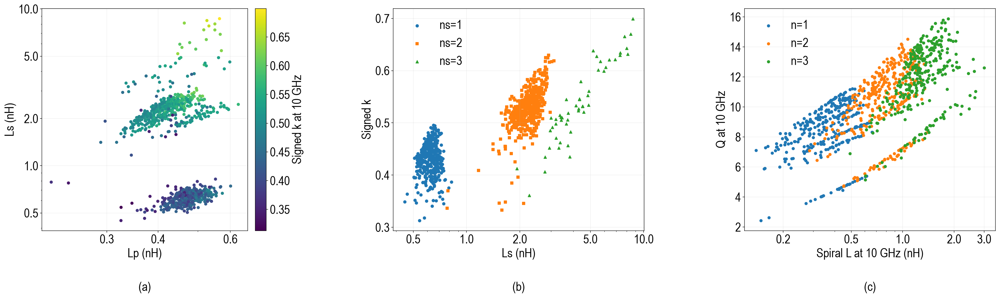

Figure 5. EM-extracted inductances and signed coupling at 10 GHz for transformers with SRF > 26 GHz (left, center), and spiral inductance and quality factor (right). Center and right panels group results by turn count.



The AI-assisted flow learns the geometry–EM response relationships underlying conventional
transformer design intuition; $L$, $Q$, $k$ and $\mathrm{SRF}$ provide a physical interpretation of
its predictions within the sampled design domain. In the dataset analysis, higher secondary turn
counts are associated with greater $L_s$, and wider secondary traces increase $Q_s$ while lowering
SRF. Increasing the number of parallel primary branches strengthens coupling while reducing $Q_s$.
Broadside-coupled samples generally have a higher median $k$ than edge-coupled samples.


## 5. Generalized Multi-Port EM Surrogate for transformer and spiral inductors

### 5.1 Model, data representation and training

Each device model averages the predictions of five residual multilayer perceptrons trained with different random seeds. The transformer uses the fourteen physical inputs defined in Section 2.1. The spiral uses the five independent geometry parameters $w,s,n,D_x,D_y$ defined in Section 2.2 and four derived features: the TopMetal2 winding centerline length $\ell$, the conductor aspect ratio $\ell/w$, the outer-area feature $D_xD_y$, and the nominal inner-area feature $[D_x-2n(w+s)][D_y-2n(w+s)]$. Here, $\ell$ is the sum of the spiral path segment lengths, excluding the terminal leads and underpass. The five geometry parameters and four derived features form a nine-dimensional input vector.

The reciprocal transformer and spiral responses contain ten and three independent complex S-parameter entries, respectively. Their real and imaginary components at 100 frequencies from 1 to 100 GHz form output vectors of 2,000 and 600 scalars.

The networks use pre-layer normalization, a hidden-layer width of 256, four residual blocks, SiLU activation and dropout of 0.05. Training-set minima and maxima define input and output normalization. AdamW [6] minimizes L1 loss with a one-cycle learning-rate schedule; validation loss determines the saved weights. The transformer surrogates were trained for 2,000 epochs. The datasets and learning curves for both device types are reported below.

The transformer and spiral surrogates supply candidate S-parameters to the joint circuit optimizer described in Section 7. Their test-set metrics and examples use the EM responses for the corresponding layouts.


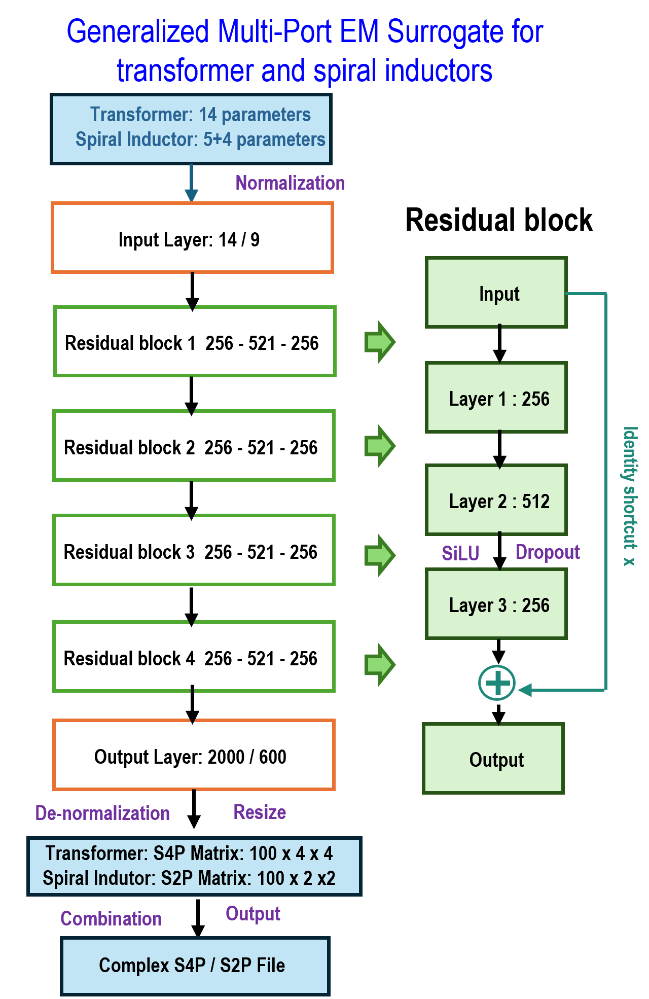

**`surrogate.py`**

<details>
<summary>Reference source listing</summary>

```python
# surrogate.py: reciprocal transformer/spiral MLP ensembles with 10/3 independent S-parameter entries.
# Geometry features follow checkpoint schema; transformer splits use the frozen manifest.
# Training: min-max [-1,1] scaling, L1 loss, AdamW and OneCycle; code/train_models.py records epoch R².
import argparse
import ast
import copy
import glob
import hashlib
import json
import os
import time
import numpy as np
import skrf as rf
import torch
import torch.nn as nn
import xfmr_schema as XG

HERE = os.path.dirname(os.path.abspath(__file__))
F_IDX = np.arange(10, 1001, 10)          # 1..100 GHz (1 GHz step) of the 1001-point EM sweep
FREQ = F_IDX * 1e8
N_F = len(F_IDX)
K10 = int(np.argmin(np.abs(FREQ - 10e9)))


# Geometry features
def track_offsets(w, s, ns, m, stack=0, wp=None):
	"""Same track order as xfmr_gen.offsets: S0, P0, S1, P1, ..., remaining S turns (stack = 1: P rings under S0, S1)."""
	p = max(w, w if wp is None else wp) + s
	if stack:
		return p, [t * p for t in range(int(ns))], [k * p for k in range(int(m))]
	kinds = []
	for t in range(int(ns)):
		kinds.append('S')
		if t < m:
			kinds.append('P')
	return p, [i * p for i, c in enumerate(kinds) if c == 'S'], [i * p for i, c in enumerate(kinds) if c == 'P']


def xfmr_features(geo):
	"""Geometry, winding/return lengths, area and inner opening using xfmr_gen conventions."""
	rows = []
	for row in np.atleast_2d(np.asarray(geo, float)):
		w, s, ns, m, D, pb, sb, u = row[:8]
		wp = row[8] if len(row) > 8 else w
		if sb == 2:        # Full-overlap loops: one 4*D turn per winding; terminal leads are about 40 um each.
			rows.append([w, s, 1, 1, D, 1, 2, u, wp, 4 * D, 4 * D, 4 * D / w, 4 * D / wp, wp / w, D * D, (D - max(w, wp)) ** 2, 1, 0, 0, 0])
			continue
		p, o, q = track_offsets(w, s, ns, m, sb, wp)
		oe = o[-1] + p
		y_u, y_e = oe + 3 * p, oe + 2 * p
		xe = u / 100 * D
		ls = sum(4 * (D - 2 * ot) for ot in o) + ((xe - 3 * p - oe) if sb else (D - 2 * oe) + (y_e - oe))   # Full turns and final partial turn.
		lp = float(np.mean([(D - qk - y_u) + (D - 2 * qk)                              # left edge up, top edge
							+ ((D - qk - xe) if not pb else (D - 2 * qk) + (D - qk - xe))   # right edge (+ bottom edge back to x_pe)
							for qk in q]))
		hole = D - 2 * oe
		rows.append([w, s, ns, m, D, pb, sb, u, wp, ls, lp, ls / w, lp / (m * wp), wp / w, D * D, hole * hole, ns / m, oe, y_u, y_e])
	return np.array(rows)


def geometry_rows(geo):
	"""Accept one geometry or a batch, including dictionaries and mixed vector lengths."""
	if isinstance(geo, dict):
		return [geo]
	rows = list(geo)
	if not rows:
		return []
	return [rows] if np.isscalar(rows[0]) else rows


def unified_xfmr_features(geo, feature_version=2):
	"""Canonical parameters plus a versioned topology one-hot."""
	rows = [XG.vector(g) for g in geometry_rows(geo)]
	if not rows:
		return np.empty((0, len(XG.KEYS) + (3 if feature_version == 1 else 4)), dtype=float)
	g = np.asarray(rows, dtype=float)
	topology = g[:, XG.KEYS.index('topology')].astype(int)
	classes = 3 if feature_version == 1 else 4
	if np.any(topology >= classes):
		raise ValueError('This unified checkpoint predates direct-exit geometry; retrain with feature version 2')
	return np.column_stack([g, np.eye(classes)[topology]])



def spiral_length(w, s, n, Dx, Dy):
	"""TopMetal2 centre-line length of the spiral (same path as spiral_gen.spiral_points)."""
	p = w + s
	pts = [(0.0, 0.0)]
	for t in range(int(n)):
		pts += [(Dx - t * p, t * p), (Dx - t * p, Dy - t * p), (t * p, Dy - t * p), (t * p, (t + 1) * p)]
	return float(np.abs(np.diff(np.array(pts), axis=0)).sum())


def spiral_features(geo):
	g = np.atleast_2d(np.asarray(geo, float))
	w, s, n, Dx, Dy = g.T
	p = w + s
	length = np.array([spiral_length(*row) for row in g])
	return np.column_stack([w, s, n, Dx, Dy, length, length / w, Dx * Dy, (Dx - 2 * n * p) * (Dy - 2 * n * p)])


# Device figures
def spiral_figures(f, s):
	"""Series-branch L/Q of the pi-equivalent (Zs = -1/Y21) and SRF of port 1 with port 2 grounded."""
	y = rf.network.s2y(s, 50)
	zs = -1 / y[:, 1, 0]
	k10 = np.argmin(np.abs(f - 10e9))
	L10 = zs[k10].imag / (2 * np.pi * f[k10])
	q = np.where(zs.real > 0.05, zs.imag / np.maximum(zs.real, 0.05), 0.0)
	x11 = (1 / y[:, 0, 0]).imag
	cross = np.where((x11[:-1] > 0) & (x11[1:] <= 0))[0]
	srf = f[cross[0]] if len(cross) else f[-1]
	ok = f < srf
	return dict(L10=L10, Q10=q[k10], Qmax=q[ok].max() if ok.any() else 0.0, SRF=srf)


def xfmr_z2(s):
	"""(F,4,4) -> Z (F,2,2) of the 2-port (P, Sbar) = dotted ends (P->Pbar and S->Sbar circulate oppositely), Pbar and S grounded."""
	y = rf.network.s2y(s, 50)[:, [0, 3]][:, :, [0, 3]]
	return np.linalg.inv(y)


def xfmr_curves(f, s):
	"""Lp, Ls [H], k, Qp, Qs versus frequency (k > 0 for the dot convention of xfmr_gen)."""
	z = xfmr_z2(s)
	w = 2 * np.pi * f
	Lp, Ls, M = z[:, 0, 0].imag / w, z[:, 1, 1].imag / w, z[:, 0, 1].imag / w
	k = M / np.sqrt(np.abs(Lp * Ls))
	qp = z[:, 0, 0].imag / np.maximum(z[:, 0, 0].real, 1e-3)
	qs = z[:, 1, 1].imag / np.maximum(z[:, 1, 1].real, 1e-3)
	return Lp, Ls, k, qp, qs


def xfmr_figures(f, s):
	Lp, Ls, k, qp, qs = xfmr_curves(f, s)
	k10 = np.argmin(np.abs(f - 10e9))
	cross = np.where((Lp[:-1] > 0) & (Lp[1:] <= 0))[0]
	srf = f[cross[0]] if len(cross) else f[-1]
	return dict(Lp10=Lp[k10], Ls10=Ls[k10], k10=k[k10], n=np.sqrt(abs(Ls[k10] / Lp[k10])), Qp10=qp[k10], Qs10=qs[k10],
				SRF=srf)


# Device interfaces
class Kind:
	def __init__(self, name, nport, ext, data_dir, features, figures, keys, geometry_schema=None):
		self.name, self.nport, self.ext, self.data_dir = name, nport, ext, data_dir
		self.features, self.figures, self.keys = features, figures, keys
		self.geometry_schema = geometry_schema
		self.sel = [(i, j) for i in range(nport) for j in range(i + 1)]    # lower triangle, reciprocity
		self.ns = len(self.sel)

	def geometry(self, geo, family=None):
		"""Adapt public inputs to this checkpoint's geometry schema before feature extraction."""
		if self.name != 'xfmr':
			return np.atleast_2d(np.asarray(geo, dtype=float))
		convert = XG.vector if self.geometry_schema == 'unified' else XG.legacy_vector
		return np.asarray([convert(XG.normalize(g, family=family)) for g in geometry_rows(geo)], dtype=float).reshape(-1, len(self.keys))

	def s_to_vec(self, s):
		v = np.stack([s[:, :, i, j] for i, j in self.sel], axis=-1)
		return np.concatenate([v.real, v.imag], axis=-1).reshape(len(s), -1)

	def vec_to_s(self, v):
		v = v.reshape(len(v), N_F, 2 * self.ns)
		c = v[..., :self.ns] + 1j * v[..., self.ns:]
		s = np.zeros((len(v), N_F, self.nport, self.nport), complex)
		for k, (i, j) in enumerate(self.sel):
			s[..., i, j] = c[..., k]
			s[..., j, i] = c[..., k]
		return s

	def broken(self, s):
		"""Open circuit at 1 GHz in one of the windings (e.g. a via dropped by the EM mesh)."""
		if self.nport == 2:
			return np.abs(s[0, 1, 0]) < 0.5
		return np.abs(s[0, 1, 0]) < 0.5 or np.abs(s[0, 3, 2]) < 0.5

	def load_dataset(self, data_dir=None, max_index=8000):
		"""Load recognized geometry/S pairs below max_index.
		Require matching ports, full frequency grid and 50-ohm references.
		The default index limit excludes verification layouts."""
		if max_index <= 0:
			raise ValueError('max_index must be positive')
		d = data_dir or self.data_dir
		geo, sp, idx = [], [], []
		skipped = {}
		def reject(reason):
			skipped[reason] = skipped.get(reason, 0) + 1
		for fn in glob.glob(f'{d}/SPData/*.{self.ext}'):
			b = os.path.basename(fn)[:-len(self.ext) - 1]
			if not b.isdigit():
				continue
			i = int(b)
			info = f'{d}/INFO/{i}.log'
			if i >= max_index:
				continue
			if not os.path.exists(info):
				info = f'{d}/INFO/{i}.json'
			if not os.path.exists(info):
				reject('missing geometry metadata')
				continue
			try:
				if self.name == 'xfmr':
					params = XG.read_info(info)
					if params['topology'] in (2, 3) and not params['port_backing']:
						raise ValueError('Unbacked v3 ports are visual geometry, not valid EM training data')
					g = self.geometry(params)[0]
				else:
					with open(info) as fi:
						g = ast.literal_eval(fi.readline())
					if len(g) != len(self.keys) or not np.all(np.isfinite(g)):
						raise ValueError('invalid spiral geometry')
				n = rf.Network(fn)
			except (ValueError, TypeError, KeyError, OSError, SyntaxError) as exc:
				reject(f'incompatible metadata or Touchstone ({type(exc).__name__})')
				continue
			if n.nports != self.nport:
				reject('wrong number of ports')
				continue
			if len(n.f) != 1001 or not np.allclose(n.f, np.arange(1001) * 1e8, rtol=1e-9, atol=1.0):
				reject('wrong frequency grid (expected 0..100 GHz at 0.1 GHz spacing)')
				continue
			if not np.all(np.isfinite(n.s)) or not np.all(np.isfinite(n.z0)) or not np.allclose(n.z0, 50.0, rtol=0, atol=1e-6):
				reject('non-finite data or non-50-ohm reference')
				continue
			s = n.s[F_IDX]
			s = 0.5 * (s + np.swapaxes(s, -1, -2))   # enforce reciprocity
			if self.broken(s):
				reject('open-circuit winding')
				continue
			geo.append(g)
			sp.append(s)
			idx.append(i)
		if skipped:
			print('Dataset exclusions: ' + '; '.join(f'{reason}: {count}' for reason, count in sorted(skipped.items())), flush=True)
		order = np.argsort(idx)
		return (np.asarray(geo, float).reshape(-1, len(self.keys))[order],
				np.asarray(sp, complex).reshape(-1, N_F, self.nport, self.nport)[order], np.asarray(idx, int)[order])


KINDS = dict(
	xfmr=Kind('xfmr', 4, 's4p', HERE, xfmr_features, xfmr_figures, ('w', 's', 'ns', 'm', 'D', 'pb', 'sb', 'u', 'wp'), 'legacy'),
	spiral=Kind('spiral', 2, 's2p', os.path.join(HERE, '..', 'TIA_work'), spiral_features, spiral_figures,
				('w', 's', 'n', 'Dx', 'Dy')),
)


def kind_for(name, geometry_schema='legacy', feature_version=2):
	"""Keep KINDS['xfmr'] compatible with existing callers; choose unified training explicitly here."""
	if name != 'xfmr':
		return KINDS[name]
	if geometry_schema == 'legacy':
		return KINDS[name]
	if geometry_schema != 'unified':
		raise ValueError(f'Unknown transformer geometry schema: {geometry_schema!r}')
	if feature_version not in (1, 2, 3):
		raise ValueError(f'Unsupported unified feature version {feature_version}')
	if feature_version == 3:
		from features14 import physical14_features
		features = physical14_features
	else:
		features = lambda geo: unified_xfmr_features(geo, feature_version)
	kind = Kind('xfmr', 4, 's4p', HERE, features, xfmr_figures, XG.KEYS, 'unified')
	kind.feature_version = feature_version
	if feature_version == 3:
		from features14 import FEATURE_KEYS, FEATURE_SCHEMA
		kind.feature_keys, kind.feature_schema = FEATURE_KEYS, FEATURE_SCHEMA
	return kind


# Networks
class MLP(nn.Module):
	def __init__(self, n_in, n_out, hidden=(256, 512, 1024, 1024), drop=0.05):
		super().__init__()
		layers, d = [], n_in
		for h in hidden:
			layers += [nn.Linear(d, h), nn.SiLU(), nn.Dropout(drop)]
			d = h
		layers.append(nn.Linear(d, n_out))
		self.net = nn.Sequential(*layers)

	def forward(self, x):
		return self.net(x)


class ResBlock(nn.Module):
	def __init__(self, d, drop):
		super().__init__()
		self.ln = nn.LayerNorm(d)
		self.f1 = nn.Linear(d, 2 * d)
		self.f2 = nn.Linear(2 * d, d)
		self.drop = nn.Dropout(drop)

	def forward(self, x):
		return x + self.f2(self.drop(nn.functional.silu(self.f1(self.ln(x)))))


class ResMLP(nn.Module):
	"""Pre-LN residual MLP."""

	def __init__(self, n_in, n_out, width=256, depth=4, drop=0.0):
		super().__init__()
		self.inp = nn.Linear(n_in, width)
		self.blocks = nn.Sequential(*[ResBlock(width, drop) for _ in range(depth)])
		self.ln = nn.LayerNorm(width)
		self.head = nn.Linear(width, n_out)

	def forward(self, x):
		return self.head(self.ln(self.blocks(self.inp(x))))


def build_model(n_in, n_out, cfg, drop=None):
	d = cfg.get('drop', 0.05) if drop is None else drop
	if cfg['arch'] == 'mlp':
		return MLP(n_in, n_out, tuple(cfg['hidden']), d)
	return ResMLP(n_in, n_out, cfg['width'], cfg['depth'], d)


class Surrogate:
	"""Ensemble surrogate. predict(geo (N,5)) -> S (N, 100, nport, nport) at FREQ."""

	def __init__(self, path, device=None):
		ck = torch.load(path, map_location='cpu', weights_only=False)
		self.geometry_schema = ck.get('geometry_schema', 'legacy')
		self.augmentation = ck.get('augmentation')
		if self.augmentation is not None:
			raise ValueError('This workflow accepts unaugmented checkpoints only')
		self.kind = kind_for(ck['kind'], self.geometry_schema, ck.get('feature_version', 1))
		if 'geometry_keys' in ck and ck['geometry_keys'] != list(self.kind.keys):
			raise ValueError('Checkpoint geometry schema does not match this code; use its original feature schema or retrain')
		if ck.get('feature_version') == 3:
			from features14 import FEATURE_KEYS, FEATURE_SCHEMA
			if ck.get('feature_keys') != list(FEATURE_KEYS) or ck.get('feature_schema') != FEATURE_SCHEMA or len(ck['xmin']) != 14:
				raise ValueError('Checkpoint does not use the exact physical fourteen-input schema')
		self.device = device or 'cpu'
		self.xmin, self.xmax, self.ymin, self.ymax = (ck[k] for k in ('xmin', 'xmax', 'ymin', 'ymax'))
		self.cfg = ck['cfg']
		self.models = []
		for sd in ck['states']:
			m = build_model(len(self.xmin), len(self.ymin), self.cfg, 0.0)
			m.load_state_dict(sd)
			self.models.append(m.to(self.device).eval())
		self.freq = FREQ

	def predict(self, geo, family=None):
		"""Predict canonical S parameters from the checkpoint's source geometry interface."""
		geo = self.kind.geometry(geo, family=family)
		if not len(geo):
			return np.empty((0, N_F, self.kind.nport, self.kind.nport), dtype=complex)
		x = self.kind.features(geo)
		x = (x - self.xmin) / (self.xmax - self.xmin) * 2 - 1
		xt = torch.from_numpy(x).float().to(self.device)
		with torch.no_grad():
			y = np.mean([m(xt).cpu().numpy() for m in self.models], axis=0)
		return self.kind.vec_to_s((y + 1) / 2 * (self.ymax - self.ymin) + self.ymin)


# Training
def s_mae(pred, y, scale, ns):
	"""Mean complex |S_pred - S_true| from normalised output vectors (scale = (ymax - ymin) / 2)."""
	d = ((pred - y) * scale).reshape(len(y), N_F, 2 * ns)
	return torch.sqrt(d[..., :ns] ** 2 + d[..., ns:] ** 2).mean().item()


def train_one(xtr, ytr, xva, yva, cfg, epochs, lr, bs, device, seed, log=True, yscale=None, ns=None, epoch_callback=None):
	"""Returns (best state dict, history of [epoch, train loss, val loss, train S-MAE, val S-MAE])."""
	torch.manual_seed(seed)
	m = build_model(xtr.shape[1], ytr.shape[1], cfg).to(device)
	opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-4)
	sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * int(np.ceil(len(xtr) / bs)))
	crit = nn.L1Loss()
	xtr, ytr, xva, yva = (torch.from_numpy(a).float().to(device) for a in (xtr, ytr, xva, yva))
	sc = torch.from_numpy(np.ones(ytr.shape[1]) if yscale is None else yscale).float().to(device)
	best, best_sd, hist = np.inf, None, []
	for ep in range(epochs):
		m.train()
		perm = torch.randperm(len(xtr), device=device)
		for k in range(0, len(xtr), bs):
			b = perm[k:k + bs]
			opt.zero_grad()
			loss = crit(m(xtr[b]), ytr[b])
			loss.backward()
			nn.utils.clip_grad_norm_(m.parameters(), 1.0)
			opt.step()
			sch.step()
		m.eval()
		with torch.no_grad():
			ptr, pva = m(xtr), m(xva)
			v = crit(pva, yva).item()
			row = [ep, crit(ptr, ytr).item(), v]
			if ns:
				row += [s_mae(ptr, ytr, sc, ns), s_mae(pva, yva, sc, ns)]
		if epoch_callback is not None:
			with torch.no_grad():
				epoch_callback(ep, ptr, pva, tuple(row))
		hist.append(row)
		if v < best:
			best, best_sd = v, {k: t.detach().cpu().clone() for k, t in m.state_dict().items()}
		if log and (ep % 200 == 0 or ep == epochs - 1):
			print(f'  seed {seed} epoch {ep:5d} train {loss.item():.5f} val {v:.5f} (best {best:.5f})', flush=True)
	return best_sd, hist


def prepare(kind, seed=42, data_dir=None, max_index=8000, split=None):
	"""Prepare canonical responses with geometry-disjoint saved or seeded partitions."""
	geo, s, idx = kind.load_dataset(data_dir=data_dir, max_index=max_index)
	if split is not None:
		if set(split) != {'train', 'val', 'test'}:
			raise ValueError('Source split must contain train, val and test IDs')
		requested = np.concatenate([np.asarray(split[k]) for k in ('train', 'val', 'test')])
		if len(np.unique(requested)) != len(requested) or len(np.setdiff1d(requested, idx)):
			raise ValueError('Saved split is overlapping or references unavailable samples')
		selected = np.isin(idx, requested)
		geo, s, idx = geo[selected], s[selected], idx[selected]
	if len(geo) < 10:
		raise ValueError('Need at least ten compatible physical layouts')
	X, Y = kind.features(geo), kind.s_to_vec(s)
	_, groups = np.unique(geo, axis=0, return_inverse=True)
	if split is None:
		order = np.random.default_rng(seed).permutation(groups.max() + 1)
		nt, nv = int(.7 * len(order)), int(.2 * len(order))
		tr, va, te = (np.flatnonzero(np.isin(groups, selection))
			for selection in (order[:nt], order[nt:nt+nv], order[nt+nv:]))
	else:
		tr, va, te = (np.flatnonzero(np.isin(idx, split[k])) for k in ('train','val','test'))
	partitions = [set(groups[selection]) for selection in (tr, va, te)]
	if any(not part for part in partitions) or any(partitions[i] & partitions[j] for i in range(3) for j in range(i)):
		raise ValueError('Geometry groups must occupy nonempty, disjoint partitions')
	xmin, xmax = X[tr].min(0), X[tr].max(0)
	xmax = np.where(xmax-xmin < 1e-9, xmin+1, xmax)
	ymin, ymax = Y[tr].min(0), Y[tr].max(0)
	ymax = np.where(ymax-ymin < 1e-9, ymin+1, ymax)
	return dict(geo=geo, s=s, idx=idx, tr=tr, va=va, te=te, xmin=xmin, xmax=xmax, ymin=ymin, ymax=ymax,
		data_dir=data_dir or kind.data_dir, max_index=max_index,
		xn=(X-xmin)/(xmax-xmin)*2-1, yn=(Y-ymin)/(ymax-ymin)*2-1)


def export_prepared(path, kind, data, source_checkpoint=None):
	"""Save the actual prepared representations and their auditable sample counts."""
	stem = os.path.splitext(path)[0] + '_data'
	if os.path.exists(stem + '.npz') or os.path.exists(stem + '.json'):
		raise FileExistsError('Prepared data already exist; use a fresh output path')
	os.makedirs(os.path.dirname(os.path.abspath(stem)), exist_ok=True)
	arrays = {key: value for key, value in data.items() if isinstance(value, np.ndarray)}
	np.savez_compressed(stem + '.npz', **arrays)
	counts = {}
	for name, key in (('train', 'tr'), ('validation', 'va'), ('test', 'te')):
		selection = data[key]
		counts[name] = dict(records=len(np.unique(data['idx'][selection])),
						   geometries=len(np.unique(data['geo'][selection], axis=0)),
						   representations=len(selection))
	report = dict(kind=kind.name, augmentation=data.get('augmentation'),
				  n_records=len(np.unique(data['idx'])), n_unique_geometries=len(np.unique(data['geo'], axis=0)),
				  n_representations=len(data['geo']), n_input_features=data['xn'].shape[1],
				  split=counts, data_dir=data['data_dir'], max_index=data['max_index'],
				  arrays=os.path.basename(stem + '.npz'), training_status='prepared_not_trained',
				  source_checkpoint=os.path.abspath(source_checkpoint) if source_checkpoint else None)
	if source_checkpoint:
		with open(source_checkpoint, 'rb') as fi:
			report['source_checkpoint_sha256'] = hashlib.sha256(fi.read()).hexdigest()
	with open(stem + '.json', 'w') as fo:
		json.dump(report, fo, indent=2)
	return report


# Evaluation
def freq_errors(kind, s_true, s_pred, f=FREQ):
	"""Per-sample error curves over frequency: mean |dS|, plus |dL| in % of L(10 GHz) (both windings for xfmr), |dk|."""
	out = dict(dS=np.abs(s_pred - s_true).mean(axis=(2, 3)))
	if kind.name == 'spiral':
		dL, dQ = [], []
		for a, b in zip(s_true, s_pred):
			za, zb = -1 / rf.network.s2y(a, 50)[:, 1, 0], -1 / rf.network.s2y(b, 50)[:, 1, 0]
			La, Lb = za.imag / (2 * np.pi * f), zb.imag / (2 * np.pi * f)
			Qa = np.where(za.real > 0.05, za.imag / np.maximum(za.real, 0.05), 0.0)
			Qb = np.where(zb.real > 0.05, zb.imag / np.maximum(zb.real, 0.05), 0.0)
			dL.append(np.abs(Lb - La) / abs(La[K10]) * 100)
			dQ.append(np.abs(Qb - Qa))
		out.update(dL=np.array(dL), dQ=np.array(dQ))
	else:
		dLp, dLs, dk = [], [], []
		for a, b in zip(s_true, s_pred):
			ca, cb = xfmr_curves(f, a), xfmr_curves(f, b)
			dLp.append(np.abs(cb[0] - ca[0]) / abs(ca[0][K10]) * 100)
			dLs.append(np.abs(cb[1] - ca[1]) / abs(ca[1][K10]) * 100)
			dk.append(np.abs(cb[2] - ca[2]))
		out.update(dLp=np.array(dLp), dLs=np.array(dLs), dk=np.array(dk))
	return out


def test_metrics(sur, geo, s):
	"""Scalar (figures at 10 GHz) and per-frequency test metrics of a Surrogate on test devices."""
	kind = sur.kind
	sp = sur.predict(geo)
	maxe = np.abs(sp - s).max(axis=(1, 2, 3))
	out = dict(kind=kind.name, n_test=len(s), dS_mean=float(np.abs(sp - s).mean()), dS_max_median=float(np.median(maxe)),
			   dS_max_p90=float(np.percentile(maxe, 90)), freq_ghz=(FREQ / 1e9).tolist())
	ft = [kind.figures(FREQ, a) for a in s]
	fp = [kind.figures(FREQ, b) for b in sp]
	for key in ft[0]:
		if key in ('k10',):
			e = np.array([abs(b[key] - a[key]) for a, b in zip(ft, fp)])
			out[f'{key}_abserr_median'], out[f'{key}_abserr_p90'] = float(np.median(e)), float(np.percentile(e, 90))
		else:
			e = np.array([abs(b[key] / a[key] - 1) * 100 for a, b in zip(ft, fp)])
			out[f'{key}_err_median'], out[f'{key}_err_p90'] = float(np.median(e)), float(np.percentile(e, 90))
			out[f'{key}_err_max'] = float(e.max())
	for name, e in freq_errors(kind, s, sp).items():
		out[f'{name}_f_median'] = np.median(e, axis=0).tolist()
		out[f'{name}_f_p90'] = np.percentile(e, 90, axis=0).tolist()
		out[f'{name}_band_mean'] = float(e.mean())
	return out


def report_text(r):
	lines = [f"[{r['kind']}] test samples {r['n_test']} | |dS| mean {r['dS_mean']:.4f}, max-per-sample median "
			 f"{r['dS_max_median']:.4f} p90 {r['dS_max_p90']:.4f}"]
	for key in [k[:-11] for k in r if k.endswith('_err_median') and not k.endswith('abserr_median')]:
		lines.append(f"{key} err %: median {r[key + '_err_median']:.2f} p90 {r[key + '_err_p90']:.2f} "
					 f"max {r[key + '_err_max']:.2f}")
	for key in [k[:-14] for k in r if k.endswith('_abserr_median')]:
		lines.append(f"{key} abs err: median {r[key + '_abserr_median']:.4f} p90 {r[key + '_abserr_p90']:.4f}")
	curves = [k[:-9] for k in r if k.endswith('_f_median')]
	lines.append('over frequency (mean of per-frequency medians): ' +
				 ', '.join(f"{c} {np.mean(r[c + '_f_median']):.4f}" for c in curves))
	return '\n'.join(lines)


def save_checkpoint(path, kind, states, cfg, d):
	os.makedirs(os.path.dirname(os.path.abspath(path)), exist_ok=True)
	torch.save(dict(kind=kind.name, geometry_schema=kind.geometry_schema, geometry_keys=list(kind.keys),
					augmentation=d.get('augmentation'),
					feature_version=getattr(kind, 'feature_version', None),
					feature_keys=list(kind.feature_keys) if hasattr(kind, 'feature_keys') else None,
					feature_schema=getattr(kind, 'feature_schema', None),
					data_dir=d.get('data_dir', kind.data_dir), max_index=d.get('max_index', 8000),
					states=states, cfg=cfg, xmin=d['xmin'], xmax=d['xmax'], ymin=d['ymin'],
					ymax=d['ymax'], split={name: d['idx'][d[key]] for name, key in (('train', 'tr'), ('val', 'va'), ('test', 'te'))}),
			   path)


def main():
	ap = argparse.ArgumentParser()
	ap.add_argument('--kind', default='xfmr', choices=list(KINDS))
	ap.add_argument('--geometry-schema', choices=['unified', 'legacy'], default='unified',
					help='Transformer feature schema; unified supports legacy and tagged series families (spiral unaffected)')
	ap.add_argument('--data-dir', default=None, help='Directory containing SPData/ and INFO/')
	ap.add_argument('--feature-version', choices=(1, 2, 3), type=int, default=3,
					help='v1/v2 retain historical features; v3 uses fourteen physical input scalars')
	ap.add_argument('--max-index', type=int, default=8000,
					help='Only train on numeric sample IDs below this value; increase explicitly to include higher-ID training samples')
	ap.add_argument('--arch', default='res', choices=['res', 'mlp'])
	ap.add_argument('--epochs', type=int, default=2000)
	ap.add_argument('--ens', type=int, default=5)
	ap.add_argument('--lr', type=float, default=2e-3)
	ap.add_argument('--bs', type=int, default=64)
	ap.add_argument('--hidden', default='256,512,1024,1024')
	ap.add_argument('--width', type=int, default=256)
	ap.add_argument('--depth', type=int, default=4)
	ap.add_argument('--drop', type=float, default=0.05)
	ap.add_argument('--out', default=None)
	ap.add_argument('--source-checkpoint', help='Freeze the source sample IDs and its geometry-disjoint split')
	ap.add_argument('--prepare-only', action='store_true', help='Export real prepared arrays and counts without training')
	ap.add_argument('--ensemble-jobs', type=int, default=1, help='Parallel CPU ensemble members')
	a = ap.parse_args()
	kind = kind_for(a.kind, a.geometry_schema, a.feature_version)
	default_name = 'xfmr_unified' if a.kind == 'xfmr' and a.geometry_schema == 'unified' else a.kind
	out = a.out or f'{HERE}/models/{default_name}.pt'
	if a.source_checkpoint and (os.path.realpath(out) == os.path.realpath(a.source_checkpoint)
			or os.path.exists(out)):
		raise FileExistsError('Use a fresh output; source checkpoints cannot be overwritten')
	if a.ensemble_jobs < 1:
		ap.error('--ensemble-jobs must be positive')
	if a.arch == 'mlp':
		cfg = dict(arch='mlp', hidden=[int(h) for h in a.hidden.split(',')], drop=a.drop)
	else:
		cfg = dict(arch='res', width=a.width, depth=a.depth, drop=a.drop)
	device = 'cuda' if torch.cuda.is_available() else 'cpu'

	source = torch.load(a.source_checkpoint, map_location='cpu', weights_only=False) if a.source_checkpoint else None
	if source is not None and source['kind'] != kind.name:
		raise ValueError('Source checkpoint device kind does not match the requested dataset')
	d = prepare(kind, data_dir=a.data_dir, max_index=a.max_index,
				split=source['split'] if source is not None else None)
	if a.prepare_only:
		counts = export_prepared(out, kind, d, a.source_checkpoint)
		print(json.dumps(counts, indent=2), flush=True)
		if a.prepare_only:
			return
	print(f"[{kind.name}] schema={kind.geometry_schema} {len(d['geo'])} valid samples, device {device}, cfg {cfg}")
	tr, va, te = d['tr'], d['va'], d['te']
	t0 = time.time()
	states, hists = [], []
	if a.ensemble_jobs > 1:
		if device != 'cpu':
			raise ValueError('Parallel ensemble jobs are supported only on CPU')
		from concurrent.futures import ProcessPoolExecutor
		import multiprocessing
		with ProcessPoolExecutor(max_workers=min(a.ensemble_jobs, a.ens),
				mp_context=multiprocessing.get_context('spawn')) as pool:
			jobs = [pool.submit(train_one, d['xn'][tr], d['yn'][tr], d['xn'][va], d['yn'][va],
				cfg, a.epochs, a.lr, a.bs, device, seed, True, (d['ymax'] - d['ymin']) / 2, kind.ns)
				for seed in range(a.ens)]
			for job in jobs:
				sd, h = job.result()
				states.append(sd)
				hists.append(h)
	else:
		for seed in range(a.ens):
			sd, h = train_one(d['xn'][tr], d['yn'][tr], d['xn'][va], d['yn'][va], cfg, a.epochs, a.lr, a.bs, device, seed,
							  yscale=(d['ymax'] - d['ymin']) / 2, ns=kind.ns)
			states.append(sd)
			hists.append(h)
	save_checkpoint(out, kind, states, cfg, d)
	print(f'training time {time.time() - t0:.0f}s -> {out}')

	sur = Surrogate(out)
	r = test_metrics(sur, d['geo'][te], d['s'][te])
	r['n_samples'] = len(np.unique(d['idx']))
	r['n_representations'] = len(d['geo'])
	r['augmentation'] = d.get('augmentation')
	r['geometry_schema'] = kind.geometry_schema
	r['geometry_keys'] = list(kind.keys)
	r['feature_version'] = getattr(kind, 'feature_version', None)
	r['data_dir'], r['max_index'] = d['data_dir'], d['max_index']
	r['n_split'] = [len(np.unique(d['idx'][selection])) for selection in (tr, va, te)]
	r['n_split_representations'] = [len(selection) for selection in (tr, va, te)]
	r['cfg'] = cfg
	r['history'] = hists[0]
	r['history_all'] = hists
	tri = lambda a: np.stack([a[:, :, i, j] for i, j in kind.sel], -1)     # Independent-entry MAE, matching the learning curves.
	for name, sel in (('train', tr), ('val', va), ('test', te)):
		r[f'mae_{name}'] = float(np.abs(tri(sur.predict(d['geo'][sel]) - d['s'][sel])).mean())
	r['mae_f_test'] = np.abs(tri(sur.predict(d['geo'][te]) - d['s'][te])).mean(axis=(0, 2)).tolist()
	report = report_text(r)
	report += f"\nS-parameter MAE (mean |dS|): train {r['mae_train']:.4f} val {r['mae_val']:.4f} test {r['mae_test']:.4f}"
	print(report)
	with open(out.replace('.pt', '_report.txt'), 'w') as fo:
		fo.write(report + '\n')
	with open(out.replace('.pt', '_report.json'), 'w') as fo:
		json.dump(r, fo, default=float)


if __name__ == '__main__':
	main()
```

</details>


In [4]:
training_devices = {'transformer': 'cpu', 'spiral': 'cuda'}
MODEL_PATHS = {kind: ROOT / 'models' / f'{kind}.pt' for kind in training_devices}
training_commands = [
    [sys.executable, 'code/train_models.py', '--kind', kind,
     '--data', f'runs/{kind}_data.npz',
     '--output', f'runs/{kind}_training', '--epochs', '2000', '--ensemble', '5',
     '--device', training_devices[kind],
     '--jobs', str(1 if training_devices[kind] == 'cuda' else min(3, max(1, CPU_BUDGET // 4))),
     '--threads', str(min(4, CPU_BUDGET))]
    for kind in training_devices
]
if RUN_TRAINING:
    if RUN_VERIFICATION and not RUN_OPTIMIZATION:
        raise ValueError('Retrained models require a new optimization before qualification.')
    missing = [f'runs/{kind}_data.npz' for kind in training_devices
               if not (ROOT / 'runs' / f'{kind}_data.npz').is_file()]
    if missing:
        raise FileNotFoundError('Prepare both datasets with RUN_EM or code/prepare_data.py: ' + ', '.join(missing))
    existing = [f'runs/{kind}_training' for kind in training_devices
                if (ROOT / 'runs' / f'{kind}_training').exists()]
    if existing:
        raise FileExistsError('Choose fresh training output paths: ' + ', '.join(existing))
    import torch
    if 'cuda' in training_devices.values() and not torch.cuda.is_available():
        raise RuntimeError('Select cpu in training_devices, or provide CUDA, before starting training.')
    for command in training_commands:
        subprocess.run(command, cwd=ROOT, check=True)
    trained = {kind: ROOT / 'runs' / f'{kind}_training' / f'{kind}.pt'
               for kind in training_devices}
    if any(not path.is_file() for path in trained.values()):
        raise FileNotFoundError('A training command did not produce its checkpoint.')
    MODEL_PATHS = trained
    from joint_passives import bind_spiral_domain
    domain = bind_spiral_domain(MODEL_PATHS['spiral'],
                               ROOT / 'data/spiral_search_domain.json',
                               ROOT / 'runs/trained_spiral_domain.json')
    os.environ['TIA_SPIRAL_DOMAIN'] = str(domain)
else:
    print('Training is opt-in; supplied checkpoints are preserved.')


Training is opt-in; supplied checkpoints are preserved.


### 5.2 Fidelity and learning curves

Prediction accuracy uses the mean absolute complex S-parameter error in linear units:

$$\mathrm{MAE}_S=\frac{1}{N N_f N_e}\sum_{n,f,(i,j)}|\hat S_{ij}^{(n)}(f)-S_{ij}^{(n)}(f)|.$$

At each frequency, the error of each test layout is averaged over its complete S-matrix. The median and 90th percentile are then calculated across the test layouts: 277 for the transformer and 100 for the spiral. Approximately 90% of the layouts have errors at or below the 90th-percentile curve. Maximum-error statistics use each layout's largest error across frequencies and matrix entries.

Training and validation $R^2$ are evaluated after every epoch using unnormalized complex S-parameters:

$$R^2_{\mathcal D}(e)=1-\frac{\sum_{n\in\mathcal D,f,i,j}|\hat S_{ij}^{(n,e)}(f)-S_{ij}^{(n)}(f)|^2}{\sum_{n\in\mathcal D,f,i,j}|S_{ij}^{(n)}(f)-\overline S_{ij,\mathcal D}(f)|^2}.$$

Here, $\mathcal D$ denotes the training or validation set, and $\overline S_{ij,\mathcal D}(f)$ is its mean EM response at each frequency and matrix entry. Each score includes all 100 frequency points and the complete matrix: sixteen transformer or four spiral entries. 

| Surrogate | Sample records | Training / validation / test | Training MAE_S | Validation MAE_S | Test MAE_S |
|:--|:--|:--|:--|:--|:--|
| Transformer | 1,839 | 1,050 / 512 / 277 | 6.39e-04 | 5.82e-03 | 7.87e-03 |
| Spiral | 1,000 | 700 / 200 / 100 | 7.34e-04 | 2.63e-03 | 1.96e-03 |

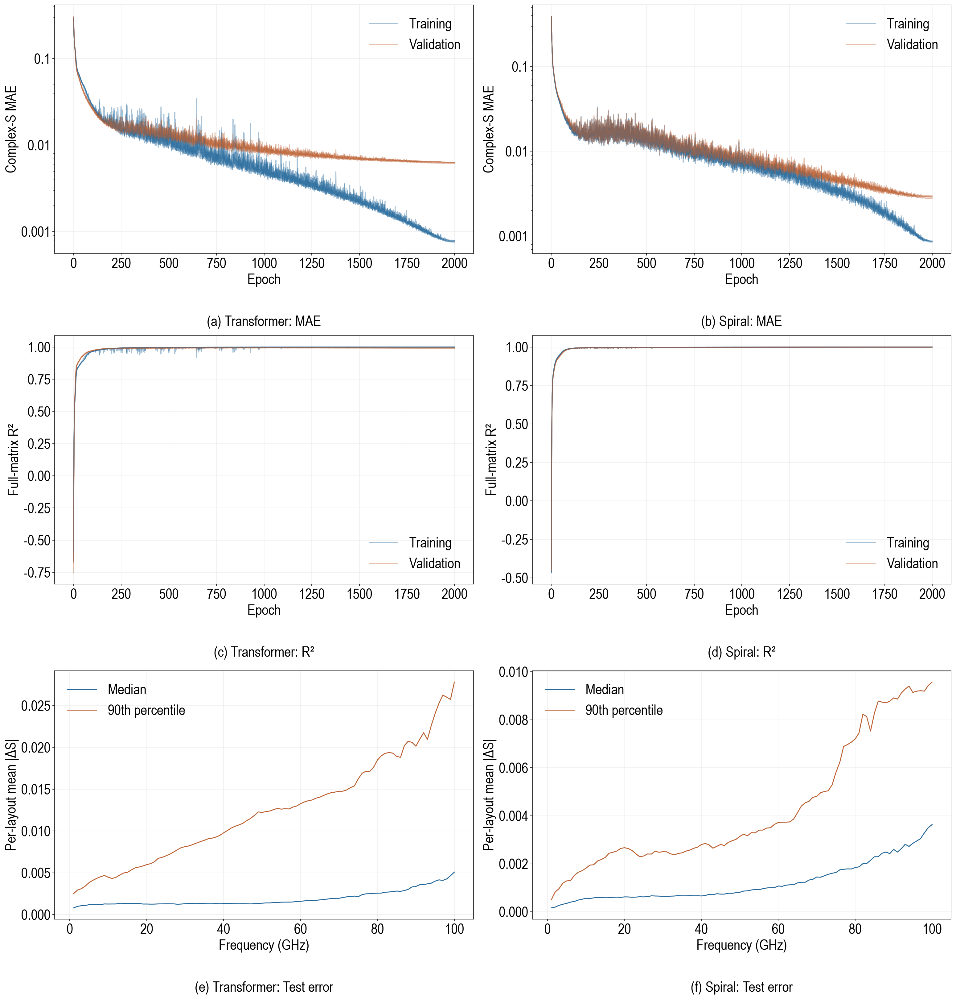

Figure 6. Transformer (left) and spiral (right) surrogates: training/validation complex-S MAE and $R^2$ versus epoch (top two rows), and median/90th-percentile test errors versus frequency (bottom). Learning curves show all five ensemble members.

| Surrogate | Full-matrix mean complex-S error | Median maximum error per layout | 90th-percentile maximum error per layout |
|:--|:--|:--|:--|
| Transformer | 7.62e-03 | 3.51e-02 | 9.19e-02 |
| Spiral | 1.96e-03 | 5.23e-03 | 1.73e-02 |



The results show that the generalized multi-port EM surrogate has high fidelity and accuracy.

### 5.3 Transformer and spiral test examples

Figures 7 and 8 show transformer and spiral examples from their respective test sets. The transformer examples use edge and broadside coupling. The spiral examples have different turn counts.

The first column shows each stored layout. Solid and dashed lines denote EM responses and surrogate predictions. The right-hand panels compare extracted inductances up to 30 GHz: primary and secondary inductances for transformers, and series-branch inductance for spirals.


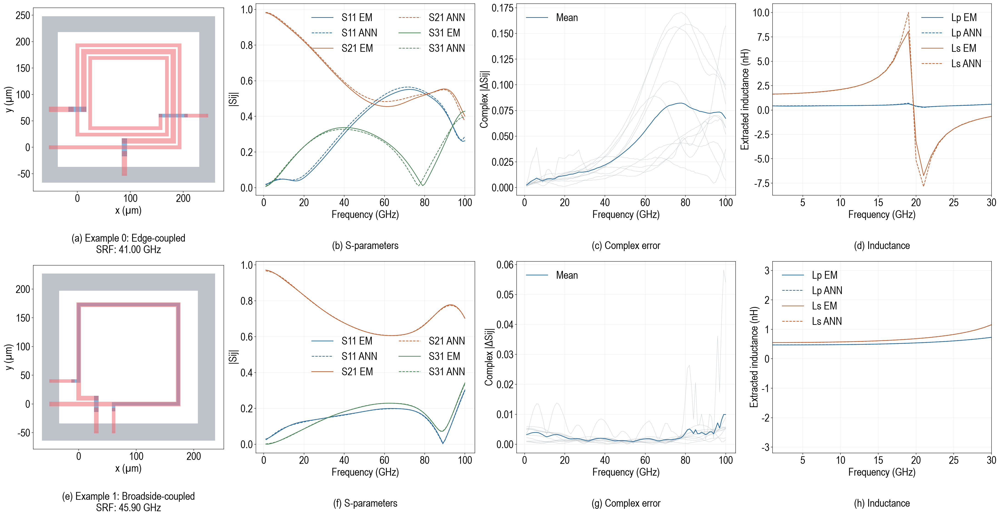

Figure 7. Transformer test layouts, S-parameter responses, complex errors and extracted inductances.

| Test GDS | Parameters [topology, sb, pb, ps, m, u, us, w, wp, s, ns, np, D, gap] | Complete-matrix MAE_S |
|:--|:--|:--|
| 0 | [0, 0, 1, 0, 1, 46, 31, 7.00, 10.00, 2.00, 2, 1, 193.00, 20.00] | 4.19e-02 |
| 1 | [0, 1, 1, 1, 1, 35, 18, 8.00, 6.00, 2.00, 1, 1, 173.00, 20.00] | 2.32e-03 |



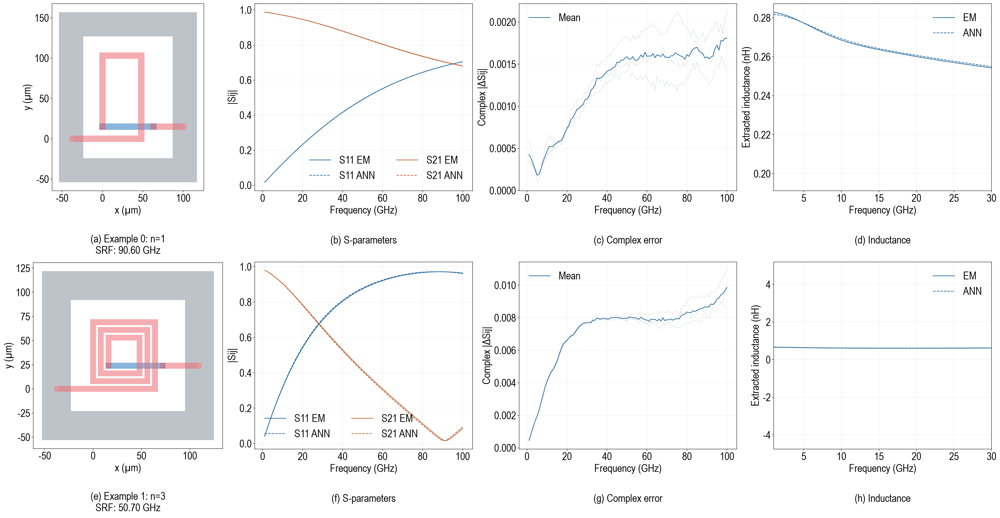

Figure 8. Spiral test layouts, S-parameter responses, complex errors and extracted series inductance.

| Test GDS | Parameters [w, s, n, Dx, Dy] | Complete-matrix MAE_S |
|:--|:--|:--|
| 0 | [8.00, 7.00, 1, 48.00, 103.00] | 1.33e-03 |
| 1 | [6.00, 2.00, 3, 64.00, 69.00] | 7.27e-03 |


## 6. SPICE co-simulation and bias

`tia_sim.py` generates netlists containing SG13G2 heterojunction bipolar transistors (HBTs), rppd resistors
and metal-insulator-metal (MIM) capacitors. Passive multiport responses are incorporated through XSPICE
`xfer` blocks. The common interface supports ideal passive models, surrogate predictions and EM-extracted
S-parameters. AC analysis provides transimpedance and group delay, while DC operating-point analysis
provides bias currents, power consumption and voltage headroom.

The HBT model header specifies an emitter mask area of Nx × (0.07 × 0.90) µm². Its le=0.96 µm and we=0.12 µm defaults use a different model geometry definition. The optimizer checks all four current densities and applies a 1.6 V collector-emitter limit with a 1 mV search margin. Independent circuit verification repeats the bias and voltage checks.

The S-parameter adapter uses controlled transfer blocks and noiseless auxiliary resistors.
It reproduces linear response, but does not automatically supply the physical noise correlation matrix of a lossy
multiport. The reported input-noise values are testbench estimates; physical passive-noise correlations require
additional modeling.

**`tia_sim.py`**

<details>
<summary>Reference source listing</summary>

```python
# tia_sim.py: 2.5 V SG13G2 transformer input, Q2 shunt-feedback gain and Q3/Q4 differential buffer.
# Ports P/Pbar/S/Sbar connect to e1/r2/b1/vb; opposite currents give k(P,Sbar)>0 and gm'=(1+n*k)*gm.
# Q4 uses Q3's low-pass base replica; outputs use Lb, 50-ohm back terminations and AC-coupled loads.
import os
import re
import shutil
import subprocess
import tempfile
import numpy as np

HERE = os.path.dirname(os.path.abspath(__file__))
NGSPICE = os.path.join(HERE, 'run_ngspice.sh')

VCC = 2.5
CPD = 220e-15                       # 150 fF photodiode + 70 fF pad
R_LOAD = 50.0                       # buffer back-termination resistor
RPPD_RSH = 260.0
CMIM_AREA = 1.5e-15                 # F/um^2 (cornerCAP.lib cap_carea)
F_REF = 1e9
LE = 0.9                            # Single npn13G2 emitter length (um).
JC_WIN = (1.0, 3.0)                 # mA/um; bias_sweep.py keeps fT >=85% of peak up to the peak-fT current density.
BV_CE = 1.7                         # npn13G2 BVceo

# Differential Zt with single-ended input and two 50-ohm loads; noise and power.
SPEC = dict(zt_dbohm=59.0, bw_ghz=32.0, peak_db=1.0, gd_pp_ps=10.0, noise_pa=21.3, power_mw=28.2)
MARGIN = dict(zt_dbohm=0.1, peak_db=0.1, gd_pp_ps=0.5, noise_pa=0.3, power_mw=0.3)   # optimisation target margins


def rppd_wl(r_ohm):
	"""rppd width/length for r_ohm: R ~ rsh*L/W + 2*rzspec/W (rzspec = 35e-6 ohm*m); wider for small R (L >= ~2 um)."""
	w = float(np.clip(2e-6 * 300.0 / r_ohm, 2e-6, 20e-6))
	return w, max((r_ohm - 2 * 35e-6 / w) * w / RPPD_RSH, 0.5e-6)


def res(name, a, b, r_ohm):
	w, l = rppd_wl(r_ohm)
	return f'X{name} {a} {b} 0 rppd w={w:.4e} l={l:.4e}'


def cmim(name, a, b, c):
	side = np.sqrt(max(c, 10e-15) / CMIM_AREA)
	return f'X{name} {a} {b} cap_cmim w={side:.3f}u l={side:.3f}u'


def sp_subckt(name, f, s):
	"""N-port S-parameter table -> ngspice XSPICE xfer subckt (pins: p1..pN ref); helper resistors are noiseless."""
	n = s.shape[1]
	ref = f'n{n + 1}'
	out = [f'.subckt {name} ' + ' '.join(f'n{i + 1}' for i in range(n)) + f' {ref}']
	for i in range(n):
		out += [f'R{i+1}N n{i+1} a{i+1}_0 -50 noisy=0', f'R{i+1}P a{i+1}_0 a{i+1}_1 100 noisy=0']
	for i in range(n):
		for j in range(n):
			nxt = ref if j == n - 1 else f'a{i+1}_{j+2}'
			k = i * n + j + 1
			out.append(f'A{i+1}_{j+1} %vd(a{j+1}_0 {ref}) %vd(a{i+1}_{j+1} {nxt}) xfer{k}')
			out.append(f'.model xfer{k} xfer R_I=true table=[')
			out += [f'+ {fk:.6e}Hz {s[q, i, j].real:.6e} {s[q, i, j].imag:.6e}' for q, fk in enumerate(f)]
			out.append('+ ]')
	out.append('.ends')
	return '\n'.join(out)


def sp_instance(tag, subckt, nodes, dc_pairs):
	"""xfer blocks have no DC path -> DC through 1 mH between the winding ends, xfer AC-coupled via 1 uF."""
	out = [f'Ldc{tag}{k} {a} {b} 1m' for k, (a, b) in enumerate(dc_pairs)]
	for k, nd in enumerate(nodes, 1):
		out += [f'Cb{tag}{k} {nd} lp{tag}{k} 1u', f'Rg{tag}{k} lp{tag}{k} 0 1G noisy=0']
	out.append(f'X{tag} ' + ' '.join(f'lp{tag}{k}' for k in range(1, len(nodes) + 1)) + f' 0 {subckt}')
	return out


def inductor(tag, a, b, model):
	"""Two-terminal coil a -> b (a = spiral port 1 = outer end)."""
	if model is None:
		return [f'V{tag} {a} {b} dc 0']
	if model[0] == 'ideal':
		return [f'L{tag} {a} {b} {model[1]:.4e}']
	return sp_instance(tag, f'sp{tag}', (a, b), [(a, b)])


def stage_nodes(stages):
	return 'b2' if '2' in stages else 'c1'


def netlist(p, xf=None, l1=None, lb=None, stages='13'):
	"""p: dict(N1, R1, R2, VB, N3, IT [, N2, R4, RF, R3, C1]); xf: None | ('ideal', Lp, Ls, k) | ('sp', f, S4)."""
	bin_ = stage_nodes(stages)
	lines = ['* SG13G2 transformer-RGC TIA', '.LIB cornerRES.lib res_typ', '.LIB cornerHBT.lib hbt_typ',
			 '.LIB cornerCAP.lib cap_typ', '']
	if xf is not None and xf[0] == 'sp':
		lines += [sp_subckt('spXF', xf[1], xf[2]), '']
	for tag, mdl in (('L1', l1), ('LBn', lb), ('LBp', lb)):
		if mdl is not None and mdl[0] == 'sp':
			lines += [sp_subckt(f'sp{tag}', mdl[1], mdl[2]), '']
	lines += [f'VCC vcc 0 dc {VCC}', f'VB vb 0 dc {p["VB"]:.4f}', 'Iin 0 pd dc 0 ac 1', f'Cpd pd 0 {CPD}']
	# stage 1: L1, Q1 (CB), transformer, R1, R2
	lines += inductor('L1', 'pd', 'e1', l1)
	lines += ['VQ1 c1 c1q dc 0', f'XQ1 c1q b1 e1 0 npn13G2 Nx={int(p["N1"])}',
			  res('R1', 'vcc', 'c1', p['R1']), res('R2', 'r2', '0', p['R2'])]
	if xf is None:
		lines += ['VXP e1 r2 dc 0', 'VXS vb b1 dc 0']
	elif xf[0] == 'ideal':
		lines += [f'LXP e1 r2 {xf[1]:.4e}', f'LXS vb b1 {xf[2]:.4e}', f'KX LXP LXS {xf[3]:.4f}']
	else:
		lines += sp_instance('XF', 'spXF', ('e1', 'r2', 'b1', 'vb'), [('e1', 'r2'), ('b1', 'vb')])
	# stage 2: shunt-feedback CE gain stage
	if '2' in stages:
		lines += ['VQ2 b2 b2q dc 0', f'XQ2 b2q c1 e2 0 npn13G2 Nx={int(p["N2"])}',
				  res('R4', 'vcc', 'b2', p['R4']), res('RF', 'c1', 'b2', p['RF']), res('R3', 'e2', '0', p['R3']),
				  cmim('C1', 'e2', '0', p['C1'])]
	# Differential buffer: Q3 drives outn; Q4 uses a low-pass replica of Q3's base.
	lines += [f'Rlp {bin_} vlp 1k', 'Clp vlp 0 1u', 'Ebuf vbuf 0 vlp 0 1',
			  'VQ3 cn cnq dc 0', f'XQ3 cnq {bin_} t 0 npn13G2 Nx={int(p["N3"])}',
			  'VQ4 cp cpq dc 0', f'XQ4 cpq vbuf t 0 npn13G2 Nx={int(p["N3"])}',
			  f'IT t 0 dc {p["IT"]:.4e}',
			  res('RLn', 'vcc', 'rn', R_LOAD), res('RLp', 'vcc', 'rp', R_LOAD)]
	lines += inductor('LBn', 'rn', 'cn', lb) + inductor('LBp', 'rp', 'cp', lb)
	lines += ['Coutn cn outn 1n', 'RLDn outn 0 50', 'Coutp cp outp 1n', 'RLDp outp 0 50']
	nodes = ['pd', 'e1', 'b1', 'c1', 'r2', 't', 'cn', 'cp', 'vbuf'] + (['b2', 'e2'] if '2' in stages else [])
	currents = ['vcc', 'vb', 'vq1', 'vq3', 'vq4'] + (['vq2'] if '2' in stages else [])
	lines += ['', '.control', 'set filetype=ascii', 'op',
			  'print ' + ' '.join(f'v({n})' for n in nodes) + ' ' + ' '.join(f'i({c})' for c in currents),
			  'ac lin 199 1G 100G', 'wrdata tia_ac.txt v(outp,outn)',
			  'noise v(outp,outn) Iin lin 99 1G 50G', 'setplot noise1',
			  'wrdata tia_noise.txt inoise_spectrum', 'quit', '.endc', '.end']
	return '\n'.join(lines)


def run(p, xf=None, l1=None, lb=None, stages='13', keep=None):
	with tempfile.TemporaryDirectory(dir=os.environ.get('TIA_TMP', '/tmp')) as d:
		cir = os.path.join(d, 'tia.cir')
		shutil.copy(os.path.join(HERE, '.spiceinit'), d)
		txt = netlist(p, xf, l1, lb, stages)
		with open(cir, 'w') as fo:
			fo.write(txt)
		r = subprocess.run(['bash', NGSPICE, cir], cwd=d, capture_output=True, text=True, timeout=600)
		if keep:
			with open(keep, 'w') as fo:
				fo.write(txt + '\n\n* ---- log ----\n* ' + r.stdout.replace('\n', '\n* '))
		try:
			ac = np.loadtxt(os.path.join(d, 'tia_ac.txt'))
			nz = np.loadtxt(os.path.join(d, 'tia_noise.txt'))
		except (OSError, ValueError):
			return None
	op = {k: float(v) for k, v in re.findall(r'^((?:v|i)\(\w+\)) = ([-+0-9.eE]+)', r.stdout, re.M)}
	m = evaluate(ac[:, 0], ac[:, 1] + 1j * ac[:, 2], nz[:, 0], nz[:, 1], op)
	m['stages'] = stages
	return m


def evaluate(f, zt, fn, inoise, op):
	mag = np.abs(zt)
	z0 = np.interp(F_REF, f, mag)
	above = np.where((f > F_REF) & (mag < z0 / np.sqrt(2)))[0]
	if len(above):
		k = above[0]
		bw = np.interp(z0 / np.sqrt(2), [mag[k], mag[k - 1]], [f[k], f[k - 1]])
	else:
		bw = f[-1]
	peak = 20 * np.log10(mag[f <= bw].max() / z0)
	ph = np.unwrap(np.angle(zt))
	gd = -np.gradient(ph, 2 * np.pi * f)
	band = (f >= F_REF) & (f <= min(bw, 26.0e9))
	gd_pp = (gd[band].max() - gd[band].min()) if band.sum() > 2 else np.inf
	nb = (fn <= min(bw, fn[-1]))
	in_avg = np.sqrt(np.trapz(inoise[nb] ** 2, fn[nb]) / (fn[nb][-1] - fn[nb][0])) if nb.sum() > 2 else np.inf
	power = VCC * abs(op.get('i(vcc)', np.nan)) + abs(op.get('i(vb)', 0.0)) * op.get('v(b1)', 0.0)
	return dict(zt_dbohm=20 * np.log10(z0), bw_ghz=bw / 1e9, peak_db=peak, gd_pp_ps=gd_pp * 1e12,
				noise_pa=in_avg * 1e12, power_mw=power * 1e3, op=op, f=f, zt=zt, fn=fn, inoise=inoise)


def headroom(op):
	"""Bias violation [V]: no saturation (Vbc <= 0.2 V), Vce <= BVceo, tail current source headroom >= 0.5 V."""
	v = lambda n: op.get(f'v({n})', 0.0)
	two = 'v(b2)' in op
	bin_ = v('b2') if two else v('c1')
	viol = [v('b1') - v('c1') - 0.2, v('c1') - v('e1') - BV_CE,
			bin_ - v('cn') - 0.2, v('cn') - v('t') - BV_CE, v('cp') - v('t') - BV_CE, 0.5 - v('t')]
	if two:
		viol += [v('c1') - v('b2') - 0.2, v('b2') - v('e2') - BV_CE]
	return sum(max(0.0, x) for x in viol)


def jc_of(p, op):
	"""Collector current densities [mA/um] of Q1, (Q2), Q3, Q4 from the collector sense sources."""
	out = [abs(op.get('i(vq1)', 0.0)) * 1e3 / (p['N1'] * LE)]
	if 'i(vq2)' in op:
		out.append(abs(op['i(vq2)']) * 1e3 / (p['N2'] * LE))
	out += [abs(op.get(f'i({q})', 0.0)) * 1e3 / (p['N3'] * LE) for q in ('vq3', 'vq4')]
	return [max(j, 1e-6) for j in out]


def bias_penalty(p, op):
	"""Log-distance of the current densities outside JC_WIN (0 inside)."""
	return sum(max(0.0, np.log(JC_WIN[0] / j), np.log(j / JC_WIN[1])) for j in jc_of(p, op))


def violations(m):
	"""Spec violations with optimisation margins (all >= 0, 0 = met)."""
	t = {k: SPEC[k] + (MARGIN.get(k, 0) if k == 'zt_dbohm' else -MARGIN.get(k, 0)) for k in SPEC}
	return dict(zt=max(0, t['zt_dbohm'] - m['zt_dbohm']), peak=max(0, m['peak_db'] - t['peak_db']),
				gd=max(0, m['gd_pp_ps'] - t['gd_pp_ps']), noise=max(0, m['noise_pa'] - t['noise_pa']),
				power=max(0, m['power_mw'] - t['power_mw']), bw=max(0, SPEC['bw_ghz'] - m['bw_ghz']))


def cost(m):
	"""Maximize bandwidth subject to the spec constraints (lower is better)."""
	if m is None or not np.isfinite(m['gd_pp_ps']):
		return 1e3
	v = violations(m)
	pen = (20 * v['zt'] + 30 * v['peak'] + 3 * v['gd'] + 2 * v['noise'] + 5 * v['power'] + 50 * headroom(m['op']))
	return -m['bw_ghz'] - 0.5 * (m['zt_dbohm'] - SPEC['zt_dbohm']) + pen


def meets(m, tol=0.0):
	"""True if every spec (incl. BW) is met without the optimisation margins."""
	if m is None:
		return False
	return (m['zt_dbohm'] >= SPEC['zt_dbohm'] - tol and m['bw_ghz'] > SPEC['bw_ghz'] - tol
			and m['peak_db'] <= SPEC['peak_db'] + tol and m['gd_pp_ps'] <= SPEC['gd_pp_ps'] + tol
			and m['noise_pa'] <= SPEC['noise_pa'] + tol and m['power_mw'] <= SPEC['power_mw'] + tol
			and headroom(m['op']) < 1e-3)


def summary(m):
	return ' '.join(f'{k}={m[k]:.2f}' for k in SPEC) if m else 'FAILED'


if __name__ == '__main__':
	# Ideal-passive self-test for stages 13 and 123.
	p = dict(N1=2, R1=300, R2=500, VB=1.3, N3=4, IT=8e-3, N2=2, R4=300, RF=800, R3=200, C1=500e-15)
	for st in ('13', '123'):
		for xf in (None, ('ideal', 0.28e-9, 1.09e-9, 0.7)):
			m = run(p, xf, ('ideal', 0.3e-9), ('ideal', 0.4e-9), st)
			print(st, 'xfmr' if xf else 'none ', summary(m), 'headroom', round(headroom(m['op']), 3) if m else '-',
				  'Jc', np.round(jc_of(p, m['op']), 2) if m else '-')
```

</details>


**`code/run_ngspice.sh`**

```bash
#!/usr/bin/env bash
set -euo pipefail
CODE_DIR="$(cd -- "$(dirname -- "${BASH_SOURCE[0]}")" && pwd)"
export PDK_ROOT="${TIA_PDK_ROOT:?Install the PDK separately and set TIA_PDK_ROOT}"
export PDK=ihp-sg13g2
if [[ -n "${TIA_NGSPICE_BIN:-}" ]]; then
    exec "$TIA_NGSPICE_BIN" -b "$@"
elif [[ -x "$CODE_DIR/../tools/opt/bin/ngspice" ]]; then
    exec "$CODE_DIR/../tools/opt/bin/ngspice" -b "$@"
else
    exec ngspice -b "$@"
fi
```


**`.spiceinit`**

```spice
*  a custom spiceinit file for IHP-Open-PDK 

* export PDK_ROOT and PDK environmental variables first and add it to your .bashrc
* export PDK_ROOT= installation_specific_directory/IHP-Open-PDK
* export PDK=ihp-sg13g2 

setcs sourcepath = (  $sourcepath $PDK_ROOT/$PDK/libs.tech/ngspice/models $PDK_ROOT/ihp-sg13g2/libs.ref/sg13g2_stdcell/spice )
setcs sourcepath = (  $sourcepath $PDK_ROOT/$PDK/libs.tech/ngspice/models $PDK_ROOT/ihp-sg13g2/libs.ref/sg13g2_io/spice )
*echo $sourcepath

*option tnom=28
*option list

* KLU solver still do not work correctly for every simulation
*option klu

* Optional diagnostics: node, opts, warn=1, maxwarns=10, savecurrents.

*set ngbehavior=hsa
*set noinit

* add OSDI 
osdi  '$PDK_ROOT/$PDK/libs.tech/ngspice/osdi/psp103.osdi'
osdi  '$PDK_ROOT/$PDK/libs.tech/ngspice/osdi/psp103_nqs.osdi'
osdi  '$PDK_ROOT/$PDK/libs.tech/ngspice/osdi/r3_cmc.osdi'
osdi  '$PDK_ROOT/$PDK/libs.tech/ngspice/osdi/mosvar.osdi'
osdi  '$PDK_ROOT/$PDK/libs.tech/ngspice/osdi/cap_cmomi.osdi'
osdi  '$PDK_ROOT/$PDK/libs.tech/ngspice/osdi/cap_cmomf.osdi'
```

## 7. Passive-active co-optimization

Constrained multivariate tree-structured Parzen estimation (TPE) [7], implemented in Optuna [8], jointly searches transformer geometry, L1/Lb geometry, resistor and capacitor values, and bias settings. Transformer surrogates and the spiral surrogate provide the passive responses for circuit evaluation.

### 7.1 Design variables and initial domain

The coupling coefficient, quality factor and self-resonant frequency extracted in Section 4 provide physical guidance for setting a compact initial domain. The initial structure is a broadside-coupled transformer with a continuous-series primary and direct exit. It has one primary branch ($m=1$) and nominal winding counts $n_s=n_p=2$. The initial width constraint is $w_p=w$. Therefor, ten variables are fixed initially as $$[topology,sb,pb,ps,m,u,us,wp,ns,np]
=[1,1,3,0,1,0,50-50(w+s)/D,w,2,2].$$ Because this structure of transformer is learned to have better k and Q, we squeeze the parameter dimensions at first for efficient optimization. Four other transformer variables are initially independent and changable: $w$, $s$, $D$ and $gap$. 

| Transformer variable | Range (µm) | Sampling |
|:--|:--|:--|
| w = wp | 5.00 to 8.00 | Integer, step 1.00 µm |
| s | 2.00 to 4.00 | Integer, step 1.00 µm |
| D | 80.00, 90.00, 100.00, 110.00, 120.00 | Discrete choices; integer u/us required |
| gap | 20.00 to 35.00 | Integer, step 1.00 µm |

Active part sweeps 8 variables. The active ranges are specified in `data/active_search_domain.json`, with capacitance in F and current in A.

| Circuit variable | Range | Unit | Sampling | Role |
|:--|:--|:--|:--|:--|
| R1 | 500.00 to 1100.00 | Ω | Logarithmic | Q1 collector load |
| R2 | 25.00 to 80.00 | Ω | Logarithmic | Input-stage emitter feedback |
| R3 | 15.00 to 50.00 | Ω | Logarithmic | Q2 emitter network |
| R4 | 200.00 to 500.00 | Ω | Logarithmic | Q2 collector load |
| RF | 1800.00 to 3000.00 | Ω | Logarithmic | Shunt feedback |
| C1 | 150.00 to 650.00 | fF | Logarithmic | Q2 emitter bypass |
| VB | 0.90 to 1.10 | V | Linear | Input-stage bias voltage |
| IT | 5.45 to 9.00 | mA | Logarithmic | Output-buffer tail current |

L1 and Lb are also searched through their five geometry variables. Each candidate geometry is checked before the spiral surrogate predicts its two-port S-parameters. The same Lb geometry is used in both output-buffer branches, giving ten independent inductor variables in total.

| Spiral variable | L1 range | Lb range | Unit |
|:--|:--|:--|:--|
| w | 3.00 to 5.00 | 3.00 to 10.00 | µm |
| s | 2.00 to 4.00 | 2.00 to 8.00 | µm |
| n | 1 to 2 | 1 to 3 | turns |
| Dx | 20.00 to 45.00 | 21.00 to 150.00 | µm |
| Dy | 20.00 to 45.00 | 26.00 to 150.00 | µm |

The initial search therefore has $4+8+10=22$ variables. Each stage samples up to 6,000 joint proposals, in batches of eight. If first run in optimization cannot get target, then release new variables gradually:

| Stage | Transformer variables | Total independent variables |
|:--|:--|:--|
| Initial | w = wp, s, D, gap | 22 |
| Release primary width | w, wp, s, D, gap | 23 |
| Release winding counts | w, wp, s, D, gap, ns, np | 25 |

When released, $wp$ uses 5.00–8.00 µm and $ns,np$ use integer values 2–4. The active and spiral bounds remain the same across stages. Expanded stages retain the compatible coarse-grid observations collected earlier in the same search. Each stage adds 256 new random proposals, with the sampling seed incremented by one, before TPE continues using the accumulated observations. Routing descriptors continue to follow the direct-exit generator. The maximum budget is 18,000 proposals across three stages, plus candidate replays. The workflow allows up to five independent random starts, using seeds beginning at 1100.

### 7.2 Co-optimization loop

Startup sampling is uniform for integer geometry variables and bias voltage, and logarithmic for R/C values and tail current. The 256 startup proposals count toward each stage budget, including geometries rejected before circuit evaluation. TPE then uses the accumulated objective and constraint records, including compatible observations from earlier stages of the same search, to select subsequent proposals. Failed or geometrically invalid proposals remain in the record; only successfully evaluated coarse-grid observations are transferred.

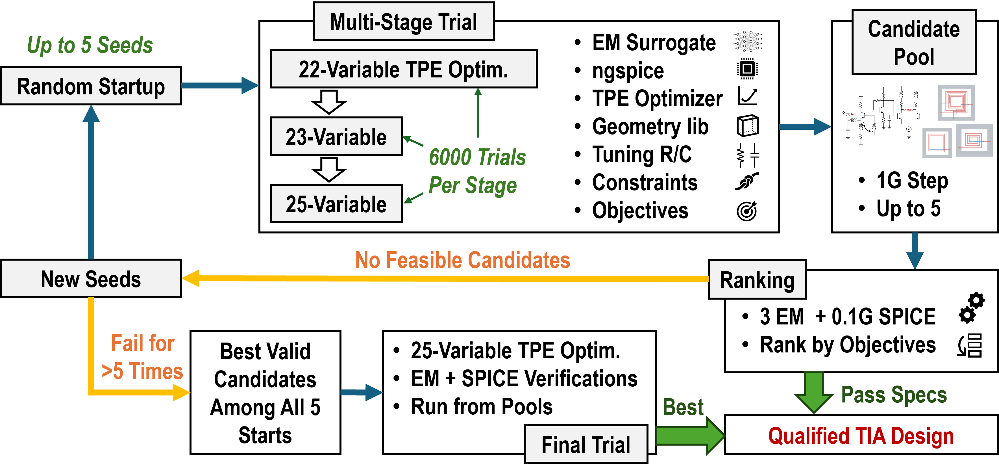

Figure 9. Joint random search, independent EM verification and active-parameter refinement.

Each TPE proposal supplies transformer geometry, two spiral geometries and the eight R/C or bias values. The generators check geometry, spacing, vias and connectivity; transformer and Lb inputs must remain within their trained feature ranges. The local L1 box permits surrogate extrapolation with unchanged weights and normalization; geometry and predicted-network screens remain mandatory. Transformer candidates remain separate from the model's training, validation and test geometries.


At each stage, up to five best feasible proposals are replayed on the 1.00 GHz circuit grid, matching the surrogate output frequencies. A feasible replay ends the surrogate search and is marked as awaiting independent EM verification. Otherwise, a normally completed search proceeds to the next variable set. Dependency failures, model errors and unsuccessful execution terminate the run. If all three stage budgets are exhausted, the workflow reports that no feasible proposal was found.

The feasible candidate pool contains at most five proposals, ranked by predicted bandwidth. Each receives new transformer, L1 and Lb GDS files and independent four-port, two-port and two-port EM simulations. Circuit qualification uses all three raw EM networks. If these networks pass their physical checks but the circuit fails a performance limit, constrained sequential least-squares programming (SLSQP) refines the eight R/C and bias variables while keeping the three layouts fixed. Each refinement point is evaluated with both surrogate and raw-EM networks. The original proposal and its failed assessment are retained separately from the refined design. A qualified design ends the search; an unsuccessful bounded refinement advances to the next proposal. Execution errors stop the workflow.

If all five random starts fail to produce an independently qualified design, up to five full 25-variable restarts use the best valid candidate from those searches. Each restart queues that parameter vector, followed by 255 random proposals within its 256-proposal startup period. All responses, objectives and constraints are evaluated again. Initialization mode and candidate provenance are retained in the run record.

### 7.3 Objective, bias and voltage constraints

The search minimizes negative bandwidth under signed constraints:

$$\min_{\mathbf{x}} -BW(\mathbf{x}),\qquad g_k(\mathbf{x})\leq 0\quad\text{for every constraint }k.$$

Here, $\mathbf{x}$ is the joint design vector in Section 7.1. Bandwidth is the single optimization objective. The index $k$ numbers the individual constraints associated with the requirements in the table. The function $g_k(\mathbf{x})$ is the signed residual for constraint $k$.

For example, let $G(\mathbf{x})$ denote transimpedance at 1 GHz in dBΩ and $P(\mathbf{x})$ denote peaking in dB. During the surrogate search,

$$g_{\mathrm{gain}}(\mathbf{x})=59.20-G(\mathbf{x}),\qquad g_{\mathrm{peak}}(\mathbf{x})=P(\mathbf{x})-1.00.$$

A peaking value of 1.10 dB gives $g_{\mathrm{peak}}=0.10$ and violates its limit. The implementation divides some residuals by positive scale factors, preserving their sign. In addition, bandwidth must also meet the surrogate minimum of 34.00 GHz.

The objective and constraint vector are stored separately. Invalid geometries and failed circuit evaluations are recorded as infeasible. Every transistor must satisfy the current-density and voltage checks.

| Quantity | Surrogate search requirement | Independent EM requirement |
|:--|:--|:--|
| Transimpedance at 1 GHz (dBΩ) | ≥ 59.20 | ≥ 59.00 |
| Bandwidth (GHz) | ≥ 34.00; maximize | > 32.00 |
| Peaking (dB) | ≤ 1.00 | ≤ 1.00 |
| Group-delay variation (ps) | ≤ 10.00 | ≤ 10.00 |
| Input-noise estimate (pA/√Hz) | ≤ 21.30 | ≤ 21.30 |
| Power (mW) | ≤ 28.20 | ≤ 28.20 |
| Each transistor current density (mA/µm) | 1.00 to 3.00 | 1.00 to 3.00 |
| Operating-region violation (mV) | < 1.00 | < 1.00 |
| Maximum collector-emitter voltage (mV) | ≤ 1599.00 | ≤ 1600.00 |

Current density is normalized by total emitter length, $J_c=|I_C|/(N_x\times0.90\,\mathrm{µm})$, with collector current expressed in mA. The voltage-policy wrapper installs the SG13G2 1.60 V limit and adds a 1 mV search margin to the explicit maximum-VCE constraint.

### 7.4 Optimization code

The portable driver `code/multistart_search.py` controls the five random starts and the conditional restart. Each random start runs the 22-, 23- and 25-variable domains through the voltage-policy wrapper in `code/staged_search.py`. The fixed-pool EM screening is implemented in `code/qualification_candidates.py`; `code/conditional_restart.py` checks five completed failures before selecting a restart vector. The controller uses 256 random startup proposals within each 6,000-proposal stage, eight parallel circuit workers and a 1.00 GHz search grid. The complete controller and preflight checks are in `code/staged_search.py`; passive checks are in `code/joint_passives.py`.

```python
from multistart_search import run

selection = run(ROOT / 'runs/joint_search', trials=6000, jobs=8,
                seed=1100, parallel=3, verify=True)
```

<details>
<summary>Staged search controller</summary>

```python
def run(output,trials=6000,jobs=4,seed=0,model=None,spiral_model=None):
    import workflow as W
    from joint_passives import proposal_binding
    if trials<1 or not 1<=jobs<=BUDGET or seed<0:raise ValueError('Invalid stage budget, worker count or seed')
    output=Path(output).resolve()
    if output.exists():raise FileExistsError('Use a fresh directory for a staged experiment')
    model=Path(model or ROOT/'models/transformer.pt').resolve()
    spiral_model=Path(spiral_model or ROOT/'models/spiral.pt').resolve()
    files=[model,spiral_model,ROOT/'data/base_geometry.json',ROOT/'data/active_search_domain.json',
           active_spiral_domain()]
    files += [ROOT/'data'/f'search_stage_{index:02d}.json' for index in range(len(STAGES))]
    files += [CODE/name for name in H.SOURCE_FILES]
    inputs={str(index):hashlib.sha256(path.read_bytes()).hexdigest() for index,path in enumerate(files)}
    initial_check=preflight(model,spiral_model)
    import expanded_direct_surrogate_flow as F
    from joint_passives import SpiralModels
    spirals=SpiralModels(spiral_model,active_spiral_domain())
    active=F.active_space('123',ROOT/'data/active_search_domain.json')
    active_count=sum(low!=high for _,low,high in active.values())
    for index,(expected,_) in enumerate(STAGES):
        domain=F.normalize_domain(W.read(ROOT/'data'/f'search_stage_{index:02d}.json'))
        if len(F.domain_bounds(domain))+len(spirals.bounds())+active_count!=expected:
            raise ValueError('Configured stage variable count disagrees with its contract')
    binding=hashlib.sha256(json.dumps(dict(inputs=inputs,trials=trials,jobs=jobs,seed=seed),sort_keys=True).encode()).hexdigest()
    output.mkdir(parents=True,exist_ok=False)
    import vce_policy as V
    campaign=dict(schema_version=1,campaign_id=uuid.uuid4().hex,plan_sha256=binding,seed=seed,jobs=jobs,
        trials_per_stage=trials,source_sha256={name:hashlib.sha256((CODE/name).read_bytes()).hexdigest() for name in H.SOURCE_FILES},
        model_sha256=dict(transformer=hashlib.sha256(model.read_bytes()).hexdigest(),spiral=hashlib.sha256(spiral_model.read_bytes()).hexdigest()),
        active_domain_sha256=hashlib.sha256((ROOT/'data/active_search_domain.json').read_bytes()).hexdigest(),
        spiral_domain_sha256=hashlib.sha256((active_spiral_domain()).read_bytes()).hexdigest(),
        base_geometry_sha256=hashlib.sha256((ROOT/'data/base_geometry.json').read_bytes()).hexdigest(),
        pdk_model_card_sha256=V.policy_from_pdk(CODE,search_buffer_v=.001)['model_card_sha256'])
    W.write(output/'campaign.json',campaign)
    W.write(output/'preflight.json',initial_check)
    progress=dict(schema_version=1,status='searching',initialization='random',startup_trials=STARTUP_TRIALS,
                  campaign_id=campaign['campaign_id'],shared_observations=True,
                  plan_sha256=binding,trials_per_stage=trials,
                  maximum_trials=len(STAGES)*trials,stages=[])
    W.write(output/'staged_search.json',progress)
    for index,(variables,description) in enumerate(STAGES):
        if any(hashlib.sha256(path.read_bytes()).hexdigest()!=inputs[str(i)] for i,path in enumerate(files)):
            raise RuntimeError('Staged-search inputs or source files changed')
        domain=ROOT/'data'/f'search_stage_{index:02d}.json'
        try:
            report=W.optimize(output/f'stage_{index:02d}',model,trials,jobs,seed+index,
                domain=domain,spiral_model=spiral_model,spiral_domain=active_spiral_domain(),
                active_domain=ROOT/'data/active_search_domain.json',startup_trials=STARTUP_TRIALS,
                campaign_record=output/'campaign.json',stage_index=index,allow_no_candidate=True)
            feasible=healthy_search(report,trials)
        except Exception as error:
            progress.update(status='execution_failed',failed_stage=index,error=f'{type(error).__name__}: {error}')
            W.write(output/'staged_search.json',progress)
            raise
        progress['stages'].append(dict(stage=index,variables=variables,description=description,
            trials=trials,status='feasible_proposal' if feasible else 'healthy_no_candidate'))
        W.write(output/'staged_search.json',progress)
        if feasible:
            best=W.read(output/f'stage_{index:02d}/best.json')
            best['stage_contract']=dict(stage=index,variables=variables,plan_sha256=binding,
                domain_file=f'data/search_stage_{index:02d}.json',trials=trials,campaign_id=campaign['campaign_id'],
                inherited_evaluations=report['within_campaign']['count'],**TP.markers())
            best['joint_binding_sha256']=proposal_binding(best)
            W.write(output/'best.json',best)
            progress.update(status='awaiting_independent_em',selected_stage=index)
            W.write(output/'staged_search.json',progress)
            print(f'Stage {index}: feasible proposal; independent EM qualification is required')
            return progress
        # Active and spiral bounds stay unchanged when transformer variables are released.
    progress['status']='no_feasible_proposal'
    W.write(output/'staged_search.json',progress)
    print('All stage budgets completed without a feasible candidate proposal')
    return progress
```

</details>

TPE receives the constraint vector separately from the bandwidth objective:

```python
sampler = optuna.samplers.TPESampler(seed=args.seed, multivariate=True, n_startup_trials=inherited_count + 256,
    constraints_func=lambda t: t.user_attrs.get('constraints', [1e6]))
study = optuna.create_study(direction='minimize', sampler=sampler)
```

The worker evaluates one joint proposal and returns its objective, constraints and failure status. The wrapper installs the voltage-policy hooks before candidate evaluation and candidate replay.

```python
def run_candidate(job):
    """Public worker; custom module:function runners support additive active connections."""
    params, geometry, models, stages, step, runner_name, gain_margin = job
    try:
        module_name, function_name = runner_name.rsplit(':', 1)
        runner = getattr(importlib.import_module(module_name), function_name)
        with circuit_grid(step):
            metrics = runner(params, *models, stages=stages)
        values = constraint_values(params, metrics, gain_margin)
        compact = summarize(params, metrics)
        if compact is None:
            values = constraint_values(params, None, gain_margin)
        feasible = compact is not None and all(v <= 0 for v in values)
        violation = sum(max(0., v) for v in values)
        objective = -compact['bw_ghz'] if compact else 1e6
        return dict(params=params, geometry=geometry, metrics_surrogate=compact,
                    constraints=values, feasible=feasible, objective=objective,
                    violation=violation, source='surrogate', status='complete' if compact else 'failed')
    except Exception as exc:
        return dict(params=params, geometry=geometry, metrics_surrogate=None,
                    constraints=constraint_values(params, None, gain_margin), feasible=False,
                    objective=1e6, violation=1e6, source='surrogate', status='failed',
                    error=f'{type(exc).__name__}: {exc}')
```

<details>
<summary>Voltage-policy hooks</summary>

```python
def install_policy_hooks(flow, policy):
    """Apply before every constraint and summary, including parent candidate replay."""
    import tia_sim as T
    V.apply_voltage_policy(T, policy)
    original_constraints, original_summary = flow.constraint_values, flow.summarize
    def constraints(params, metrics, gain_margin_db=.2):
        # Custom circuit runners may reload tia_sim before returning their raw OP.
        V.apply_voltage_policy(importlib.import_module('tia_sim'), policy)
        values = list(original_constraints(params, metrics, gain_margin_db))
        values.append(V.search_constraint((metrics or {}).get('op'), policy))
        return values
    def summarize(params, metrics):
        V.apply_voltage_policy(importlib.import_module('tia_sim'), policy)
        result = original_summary(params, metrics)
        if result is not None:
            result['voltage_policy_sha256'] = policy['policy_sha256']
            result['voltage_audit'] = V.audit_op(result.get('op'), policy)
        return result
    flow.constraint_values, flow.summarize = constraints, summarize
    def restore():
        flow.constraint_values, flow.summarize = original_constraints, original_summary
    return restore
```

</details>

The complete sampler and refinement code is in `code/expanded_direct_surrogate_flow.py`. `code/workflow.py qualify` generates and independently EM-evaluates all three selected passives for a joint-search proposal.

The EM-guided step is implemented in `code/em_active_refinement.py`. It uses normalized coordinates for the same eight active-variable bounds. Its coarse raw-EM search uses BW ≥ 32.20 GHz and peaking ≤ 0.99 dB, while the paired surrogate check retains BW ≥ 34.00 GHz, the 0.20 dB gain margin and the 1 mV voltage margin. Final acceptance uses the requirements in Section 7.3 on a fresh 0.10 GHz circuit grid.

```python
result = minimize(objective, x0, method='SLSQP', bounds=[(0.0, 1.0)] * 8,
                  constraints=[{'type': 'ineq', 'fun': constraints}],
                  options={'maxiter': 20, 'eps': 1e-3, 'ftol': 1e-8})
```

The refinement budget is 300 total SPICE calls and 600 s. Each paired point counts as two calls, and the budget reserves a final dense replay. No design is accepted without passing both the surrogate check and independent raw-EM circuit verification.

### 7.5 Recorded optimization progress

The recorded random search used seed 1100 and 256 startup proposals per stage. The 22- and 23-variable stages each evaluated 6,000 proposals with a 35 GHz bandwidth screen. Five proposals were subsequently replayed against the 34 GHz surrogate requirement; the selected geometry came from the 23-variable stage. EM-guided active refinement then used 70 paired evaluations and one dense replay, totaling 141 SPICE calls.

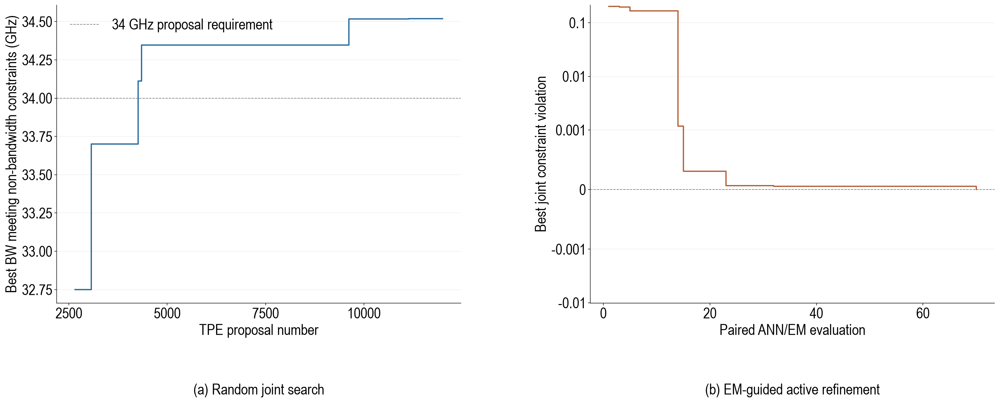

Figure 9b. Recorded TPE bandwidth progress and paired ANN/EM refinement feasibility. The TPE curve includes designs satisfying all non-bandwidth constraints.


In [5]:
PROPOSAL_PATH = ROOT / 'data/selected_proposal.json'
SEARCH_RECORD_PATH = None
RESULT_ROOT = ROOT / 'runs/final_results' if RUN_VERIFICATION else None
if RUN_OPTIMIZATION:
    search_directory = ROOT / 'runs/joint_search'
    PROPOSAL_PATH = search_directory / 'best.json'
    SEARCH_RECORD_PATH = search_directory / 'staged_search.json'
    RESULT_ROOT = None
    command = [
        sys.executable, 'code/multistart_search.py', '--output', str(search_directory),
        '--trials', '6000', '--jobs', str(min(8, CPU_BUDGET)), '--seed', '1100', '--parallel', '3',
        '--model', str(MODEL_PATHS['transformer']),
        '--spiral-model', str(MODEL_PATHS['spiral']),
    ]
    if RUN_VERIFICATION:
        command.append('--verify')
    subprocess.run(command, cwd=ROOT, check=True)
    selection = json.loads((search_directory / 'selection.json').read_text())
    if RUN_VERIFICATION:
        if selection['status'] != 'qualified' or not selection.get('result_root'):
            raise ValueError('The new search has no independently qualified result.')
        RESULT_ROOT = (search_directory / selection['result_root']).resolve()
        if not RESULT_ROOT.is_relative_to(search_directory.resolve()):
            raise ValueError('The selected result directory escapes the new search.')


In [6]:
# Read the selected proposal and its circuit/model inputs.
import json
from features14 import FEATURE_KEYS, physical14_features

selected_proposal = json.loads(PROPOSAL_PATH.read_text())
inputs = physical14_features(selected_proposal['geometry'])[0]
integer_inputs = {'topology', 'sb', 'pb', 'ps', 'm', 'u', 'us', 'ns', 'np'}
active_keys = ('N1', 'R1', 'R2', 'VB', 'N2', 'R4', 'RF', 'R3', 'C1', 'N3', 'IT')
metric_keys = ('zt_dbohm', 'bw_ghz', 'peak_db', 'gd_pp_ps', 'noise_pa', 'power_mw')
proposal_view = {
    'initialization': json.loads(SEARCH_RECORD_PATH.read_text())['initialization'] if RUN_OPTIMIZATION else selected_proposal['initialization'],
    'final_refinement': 'EM-guided active refinement' if selected_proposal.get('proposal_role') == 'submitted_final_design' or 'em_refinement' in selected_proposal else None,
    'transformer_inputs': {key: int(round(v)) if key in integer_inputs else float(v)
                           for key, v in zip(FEATURE_KEYS, inputs)},
    'spiral_geometries': selected_proposal['spiral_geometries'],
    'active_parameters_SI': {key: selected_proposal['params'][key] for key in active_keys},
    'predicted_circuit_metrics': {key: selected_proposal['metrics_surrogate'][key]
                                  for key in metric_keys},
    'predicted_bias': {
        'current_densities_mA_per_um': selected_proposal['metrics_surrogate']['jc'],
        'max_vce_V': selected_proposal['voltage_audit']['max_vce_v'],
    },
    'surrogate_constraints_pass': selected_proposal['feasible'],
    'requires_independent_em': selected_proposal['requires_independent_em'],
}
print(json.dumps(proposal_view, indent=2))


{
  "initialization": "random_joint_search_then_EM_guided_active_refinement",
  "final_refinement": "EM-guided active refinement",
  "transformer_inputs": {
    "topology": 1,
    "sb": 1,
    "pb": 3,
    "ps": 0,
    "m": 1,
    "u": 0,
    "us": 45,
    "w": 5.0,
    "wp": 5.0,
    "s": 3.0,
    "ns": 2,
    "np": 2,
    "D": 80.0,
    "gap": 30.0
  },
  "spiral_geometries": {
    "L1": [
      4,
      4,
      1,
      24,
      25
    ],
    "LB": [
      10,
      2,
      1,
      70,
      128
    ]
  },
  "active_parameters_SI": {
    "N1": 2,
    "R1": 920.5615968334077,
    "R2": 79.11635843734828,
    "VB": 1.0138915281852146,
    "N2": 2,
    "R4": 200.00000000000026,
    "RF": 3000.0,
    "R3": 29.492616575281854,
    "C1": 2.9862651604447217e-13,
    "N3": 3,
    "IT": 0.0054500000000000035
  },
  "predicted_circuit_metrics": {
    "zt_dbohm": 59.44657763177182,
    "bw_ghz": 34.427785499543916,
    "peak_db": 0.49221687080774434,
    "gd_pp_ps": 9.443232555383219,
    

## 8.  End-to-end inverse-design results with EM verification

**This section presents two case studies. Case 1 follows the optimization flow above, with an initial 35 GHz bandwidth screen, a final surrogate bandwidth requirement of at least 34 GHz and an independent EM bandwidth requirement above 32 GHz. Case 2 was obtained with a 26 GHz bandwidth requirement and has larger eye heights under the same reconstruction settings.**

The selected transformer, L1 and Lb geometries are generated and evaluated with new four-port,
two-port and two-port EM simulations.
After EM-guided active refinement, a fresh ngspice replay uses all three raw EM networks and the final R/C and bias values on a 0.10 GHz circuit grid, matching the available raw EM data.
Physical-network quality, circuit specifications, bias and collector-emitter voltages must pass
before the design is qualified. The command below performs this verification when enabled.


In [7]:
qualification_command = [
    sys.executable, 'code/workflow.py', 'qualify',
    '--proposal', str(PROPOSAL_PATH), '--output', 'runs/independent_qualification',
    '--threads', str(CPU_BUDGET),
    '--model', str(MODEL_PATHS['transformer']),
    '--spiral-model', str(MODEL_PATHS['spiral']),
]
if RUN_OPTIMIZATION and RUN_VERIFICATION:
    final_record = json.loads((RESULT_ROOT / 'data/final_design.json').read_text())
    if not final_record['strict_feasible']:
        raise ValueError('The new multistart search has no independently qualified result.')
elif RUN_VERIFICATION:
    subprocess.run(qualification_command, cwd=ROOT, check=True)
    subprocess.run([
        sys.executable, 'code/qualified_results.py',
        '--proposal', str(PROPOSAL_PATH),
        '--qualification', 'runs/independent_qualification', '--output', str(RESULT_ROOT),
    ], cwd=ROOT, check=True)
elif RUN_OPTIMIZATION:
    print('The new proposal requires independent EM qualification before new performance is available.')
else:
    print('Recorded independently qualified results are shown below.')


Recorded independently qualified results are shown below.


### 8.1 Case study 1 with wider bandwidth

#### 8.1.1 Final TIA performance 

| Metric | With transformer: EM-evaluated circuit | Without transformer |
|:--|:--|:--|
| Zt at 1 GHz (dBΩ) | 59.45 | 59.32 |
| −3 dB bandwidth (GHz) | 35.75 | 22.11 |
| Peaking (dB) | 1.00 | 0.00 |
| Group-delay variation (ps) | 8.66 | 2.00 |
| Input-noise estimate (pA/√Hz) | 21.13 | 26.96 |
| Power (mW) | 28.19 | 28.19 |

The optimized TIA passes the circuit, bias, voltage and physical-network checks. Its maximum transistor VCE is 1.57 V, below the SG13G2 limit of 1.60 V.

The no-transformer comparison replaces the windings with ideal direct connections e1–r2 and vb–b1. HBT sizes, R/C values, bias settings and the newly EM-evaluated L1/Lb networks are identical. Bandwidth is 35.75 GHz with the transformer and 22.11 GHz with the winding bypasses. Group-delay variation is evaluated from 1 GHz to min(BW, 26 GHz), giving upper limits of 26.00 and 22.11 GHz, respectively. Transformer feedback increases bandwidth under this fixed-parameter comparison.

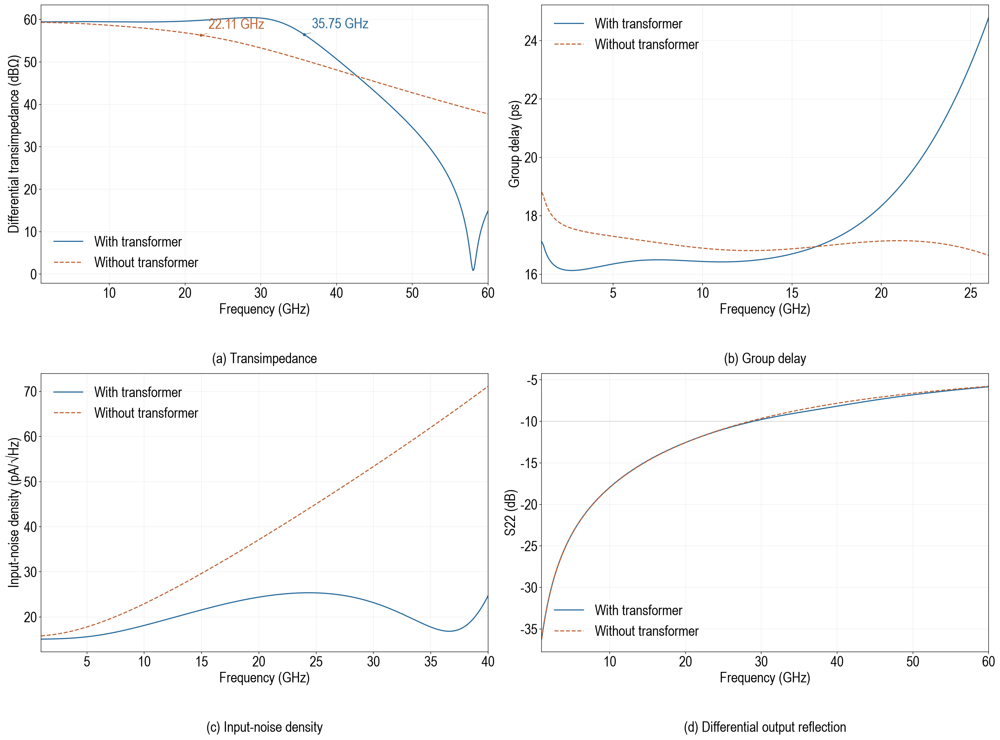

Figure 10. TIA transimpedance, group delay, input-noise estimate and differential S22 with the transformer (solid) and ideal winding bypasses (dashed).

##### NRZ and PAM4 eyes

The eye diagram setup is shown below.

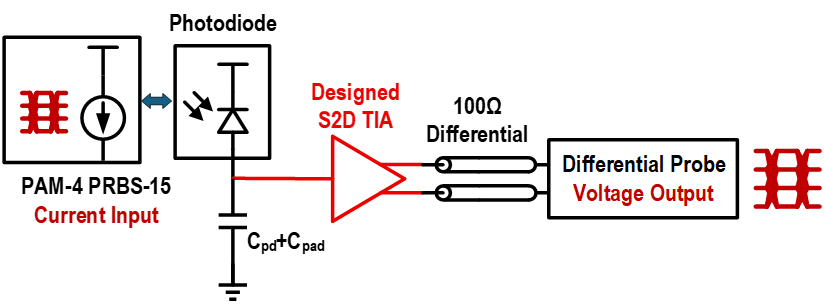

NRZ (PAM2) carries one bit per symbol, and Gray-coded PAM4 carries two. The two 50 Gb/s cases use 50 GBd NRZ and 25 GBd PAM4. The original 106.25 Gb/s PAM4 case at 53.125 GBd is retained as a higher-rate reference.

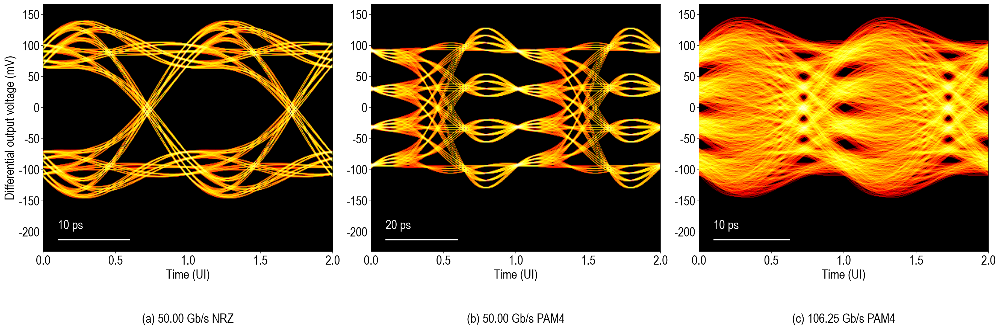

Figure 11. Noise-free linear eyes from the verified TIA response: (a) 50 Gb/s NRZ, (b) 50 Gb/s PAM4 and (c) 106.25 Gb/s PAM4, with 200 µA peak-to-peak input current. Colors show log trace density, scaled per panel; bars indicate time.

| Modulation | Bit rate (Gb/s) | Symbol rate (GBd) | Minimum eye height (mV) | Common width (UI / ps) |
|:--|:--|:--|:--|:--|
| NRZ | 50.00 | 50.00 | 133.92 | 0.72 / 14.43 |
| PAM4 | 50.00 | 25.00 | 53.90 | 0.69 / 27.43 |
| PAM4 | 106.25 | 53.12 | 13.64 | 0.08 / 1.53 |

Eye heights and common timing windows are evaluated from the same verified response for each modulation and rate. The rate sweep retains all evaluated cases.

Below the first saved AC sample, the real gain is held constant and the imaginary part approaches zero at DC. A raised-cosine taper removes the final 20% of the saved frequency band; the response is zero above it. Eye heights are finite-pattern level-envelope gaps. Width uses one fixed threshold for NRZ or three fixed thresholds at one common phase for PAM4. Display polarity may be reversed. This linear reconstruction excludes random noise, nonlinear swing, jitter and equalization and does not establish BER.

The reconstruction is provided below and in `code/eye.py`. `code/wireline_eyes.py` reproduces the figure and the complete NRZ/PAM4 rate sweep from the same response.

<details>
<summary>NRZ and PAM4 reconstruction code</summary>

```python
"""Deterministic linear NRZ and PAM4 reconstruction from complex TIA responses."""
import numpy as np


def prbs15_bits(count, seed=1):
    """Return count bits of b[n+15] = b[n+14] XOR b[n], with period 32767.
    Initial b[0:15] contains seed bits in least-significant-bit-first order."""
    count, seed = int(count), int(seed)
    if count < 1 or not 0 < seed < 2**15:
        raise ValueError('Use a positive bit count and a nonzero 15-bit seed')
    bits = np.empty(count + 15, dtype=np.uint8)
    bits[:15] = [(seed >> i) & 1 for i in range(15)]
    for i in range(count):
        bits[i + 15] = bits[i + 14] ^ bits[i]
    return bits[:count]


def pam4_word(nsym=2048, input_pp=200e-6, seed=1):
    """Gray mapping: 00/01/11/10 -> levels 0/1/2/3, rectangular NRZ pulses."""
    if int(nsym) < 64 or not np.isfinite(input_pp) or input_pp <= 0:
        raise ValueError('Use at least 64 symbols and a positive current swing')
    bits = prbs15_bits(2 * int(nsym), seed)
    levels = np.array([0, 1, 3, 2], dtype=np.uint8)[2 * bits[::2] + bits[1::2]]
    if len(np.unique(levels)) != 4:
        raise ValueError('The selected PRBS word does not contain all PAM4 levels')
    return levels, (levels.astype(float) / 3 - .5) * float(input_pp)


def nrz_word(nsym=2048, input_pp=200e-6, seed=1):
    """Binary NRZ/PAM2 current levels with the same peak-to-peak swing as PAM4."""
    if int(nsym) < 64 or not np.isfinite(input_pp) or input_pp <= 0:
        raise ValueError('Use at least 64 symbols and a positive current swing')
    levels = prbs15_bits(int(nsym), seed)
    if len(np.unique(levels)) != 2:
        raise ValueError('The selected PRBS word does not contain both NRZ levels')
    return levels, (levels.astype(float) - .5) * float(input_pp)


def _checked_response(response):
    f, zt = np.asarray(response['f'], float), np.asarray(response['zt'], complex)
    if (f.ndim != 1 or zt.shape != f.shape or len(f) < 3
            or not np.all(np.isfinite(f)) or not np.all(np.isfinite(zt))
            or f[0] < 0 or np.any(np.diff(f) <= 0) or abs(zt[0]) == 0):
        raise ValueError('Response needs finite complex Zt on an increasing frequency grid')
    return f, zt


def _gaps(samples, levels, nlevels=4):
    groups = [samples[levels == k] for k in range(nlevels)]
    lower = np.array([np.min(x, axis=0) for x in groups])
    upper = np.array([np.max(x, axis=0) for x in groups])
    return lower[1:] - upper[:-1], lower, upper


def _positive_window(margin, centre):
    """Width of the positive interval containing centre, interpolated in samples."""
    if margin[centre] <= 0:
        return 0.0
    left = right = int(centre)
    while left > 0 and margin[left - 1] > 0:
        left -= 1
    while right + 1 < len(margin) and margin[right + 1] > 0:
        right += 1
    lo, hi = float(left), float(right)
    if left > 0:
        lo -= margin[left] / (margin[left] - margin[left - 1])
    if right + 1 < len(margin):
        hi += margin[right] / (margin[right] - margin[right + 1])
    return max(0.0, hi - lo)


def reconstruct_eye(response, baud=53.125e9, nsym=2048, osr=32,
                    input_pp=200e-6, seed=1, taper_fraction=.8, modulation='PAM4'):
    """Reconstruct a finite-word, periodic, noiseless linear NRZ/PAM4 eye with Cartesian Zt interpolation.
    Below band, hold Re(Zt) and ramp Im(Zt) to zero at DC; this is an assumed completion.
    Remove the input mean, apply a raised-cosine taper to the final 20% of the band by default, and zero the response above band."""
    f, zt = _checked_response(response)
    osr, nsym = int(osr), int(nsym)
    if (not np.isfinite(baud) or baud <= 0 or osr < 8 or osr % 2
            or not 0 < taper_fraction <= 1):
        raise ValueError('Use positive baud, an even OSR >=8, and taper_fraction in (0,1]')
    if modulation not in ('NRZ', 'PAM4'):
        raise ValueError('Choose NRZ (PAM2) or PAM4')
    nlevels = 4 if modulation == 'PAM4' else 2
    bits_per_symbol = 2 if modulation == 'PAM4' else 1
    levels, symbols = (pam4_word if modulation == 'PAM4' else nrz_word)(nsym, input_pp, seed)
    fs = float(baud) * osr
    x = np.repeat(symbols - symbols.mean(), osr)
    fk = np.fft.rfftfreq(len(x), 1 / fs)
    h = np.interp(fk, f, zt.real) + 1j * np.interp(fk, f, zt.imag)
    if f[0] > 0:
        low = fk < f[0]
        h[low] = zt[0].real + 1j * zt[0].imag * fk[low] / f[0]
    start, stop = float(f[-1]) * taper_fraction, float(f[-1])
    taper = np.ones_like(fk)
    if start < stop:
        band = (fk > start) & (fk < stop)
        taper[band] = .5 * (1 + np.cos(np.pi * (fk[band] - start) / (stop - start)))
    taper[fk >= stop] = 0
    # A polarity flip is only for display; the recorded complex phase is retained.
    polarity = 1.0 if zt[0].real >= 0 else -1.0
    y = polarity * np.fft.irfft(np.fft.rfft(x) * h * taper, len(x))

    # Estimate whole-symbol propagation delay, then optimize one common sampling
    # phase for every eye.  PAM4 uses one phase for all three eyes.
    lowband = f <= min(f[-1], max(f[0] + 2 * (f[1] - f[0]), baud / 4))
    delay = -np.polyfit(2 * np.pi * f[lowband], np.unwrap(np.angle(zt[lowband])), 1)[0]
    delay_samples = int(round(delay * fs))
    guard = min(32, nsym // 8)
    ids = np.arange(guard, nsym - guard)
    centres = ids * osr + osr // 2
    shifts = np.arange(delay_samples - 2 * osr, delay_samples + 2 * osr + 1)
    scores = []
    for shift in shifts:
        gaps, _, _ = _gaps(y[(centres + shift) % len(y)], levels[ids], nlevels)
        scores.append(float(np.min(gaps)))
    scores = np.asarray(scores)
    tolerance = max(1e-15, np.max(abs(y)) * 1e-12)
    # A flat-gain channel has many equally open phases.  Resolve numerical ties
    # toward the estimated propagation delay, keeping its sampling point central.
    tied = shifts[scores >= scores.max() - tolerance]
    shift = int(min(tied, key=lambda value: abs(value - delay_samples)))
    y = np.roll(y, -shift)
    sample_matrix = y.reshape(nsym, osr)[ids]
    gaps, lower, upper = _gaps(sample_matrix, levels[ids], nlevels)
    centre = osr // 2
    heights = gaps[:, centre]
    thresholds = (lower[1:, centre] + upper[:-1, centre]) / 2
    margins = np.minimum(lower[1:] - thresholds[:, None], thresholds[:, None] - upper[:-1])
    # Include the next phase endpoint to give an unambiguous 0..1 UI interval.
    widths = [_positive_window(np.r_[m, m[0]], centre) / osr for m in margins]
    common_width = _positive_window(np.r_[margins.min(axis=0), margins[:, 0].min()], centre) / osr
    ideal_spacing = abs(zt[0]) * float(input_pp) / (nlevels - 1)
    minimum_height = min(heights)
    metrics = dict(eye_heights_mv=(heights * 1e3).tolist(), min_eye_mv=float(minimum_height * 1e3),
                   eye_width_ui=[float(w) for w in widths], common_width_ui=float(common_width),
                   common_width_ps=float(common_width / baud * 1e12),
                   phase_ui=float(((centre + shift) % osr) / osr),
                   deskew_ps=float(shift / fs * 1e12), polarity_flipped=polarity < 0,
                   ideal_spacing_1ghz_mv=float(ideal_spacing * 1e3),
                   opening_pct=float(100 * minimum_height / ideal_spacing),
                   output_pp_mv=float(np.ptp(y) * 1e3), response_points=len(f),
                   response_min_ghz=float(f[0] / 1e9), response_max_ghz=float(f[-1] / 1e9),
                   response_step_max_ghz=float(np.max(np.diff(f)) / 1e9),
                   taper_start_ghz=start / 1e9, taper_stop_ghz=stop / 1e9)
    if modulation == 'PAM4':
        metrics.update(lower_eye_mv=float(heights[0] * 1e3), middle_eye_mv=float(heights[1] * 1e3),
                       upper_eye_mv=float(heights[2] * 1e3))
    if 'fn' in response and 'inoise' in response:
        fn, ni = np.asarray(response['fn'], float), np.asarray(response['inoise'], float)
        good = ((fn >= f[0]) & (fn <= f[-1]) & np.isfinite(fn)
                & np.isfinite(ni) & (ni >= 0)) if fn.shape == ni.shape else np.zeros(0, bool)
        if np.count_nonzero(good) >= 3 and np.all(np.diff(fn[good]) > 0):
            nf = fn[good]
            zn = np.interp(nf, f, zt.real) + 1j * np.interp(nf, f, zt.imag)
            integrate = np.trapezoid if hasattr(np, 'trapezoid') else np.trapz
            rms = np.sqrt(integrate((ni[good] * abs(zn))**2, nf))
            metrics.update(output_noise_rms_mv=float(rms * 1e3),
                           noise_band_ghz=[float(nf[0]/1e9), float(nf[-1]/1e9)])
    return dict(metrics=metrics, waveform=y, levels=levels, osr=osr, guard=guard,
                settings=dict(baud=float(baud), nsym=nsym, osr=osr, input_pp=float(input_pp), seed=int(seed),
                              modulation=modulation, bits_per_symbol=bits_per_symbol, bit_rate=float(baud) * bits_per_symbol))


def _eye_density(eye, voltage_edges, samples_per_ui=256, centered=False):
    """Count all retained eye traces; finer linear interpolation is display-only."""
    y, osr, guard = eye['waveform'], eye['osr'], eye['guard']
    nsym = len(y) // osr
    starts = np.arange(guard, nsym - guard - 1)
    offsets = np.arange(2 * osr + 1)
    first = starts * osr - (osr // 2 if centered else 0)
    traces = y[first[:, None] + offsets] * 1e3
    original_t = offsets / osr
    fine_t = (np.arange(2 * samples_per_ui) + .5) / samples_per_ui
    dense = np.array([np.interp(fine_t, original_t, trace) for trace in traces])
    time_edges = np.linspace(0, 2, 2 * samples_per_ui + 1)
    density, _, _ = np.histogram2d(np.broadcast_to(fine_t, dense.shape).ravel(), dense.ravel(),
                                    bins=(time_edges, voltage_edges))
    return density.T
```

</details>


In [8]:
if not RUN_VERIFICATION or RESULT_ROOT is None:
    final_eye = None
    final_eye_cases = []
    print('Eye reconstruction runs after RUN_VERIFICATION generates the circuit response; recorded eyes remain embedded below.')
else:
    # Reconstruct the documented NRZ/PAM4 cases from the newly verified circuit response.
    import numpy as np
    from wireline_eyes import FIGURE_CASES, evaluate

    with np.load(RESULT_ROOT / 'results/with_transformer.npz', allow_pickle=False) as response:
        final_eye_cases = [evaluate(response, *case) for case in FIGURE_CASES]
    final_eye = final_eye_cases[-1][0]
    for eye, record in final_eye_cases:
        metrics = eye['metrics']
        print(f"{record['modulation']}: {record['bit_rate_gbps']:.2f} Gb/s, "
              f"{record['baud_gbd']:.2f} GBd; minimum height {metrics['min_eye_mv']:.2f} mV; "
              f"width {metrics['common_width_ui']:.2f} UI / {metrics['common_width_ps']:.2f} ps")


Eye reconstruction runs after RUN_VERIFICATION generates the circuit response; recorded eyes remain embedded below.


#### 8.1.2 Passive and active design parameters

Circuit topology and device symbols follow the schematic in Section 1.1. Node names in the operating-point table follow the SPICE testbench. Tables display rounded values, with terminal percentages shown as integers; `data/final_design.json` retains full precision for circuit replay.

##### Passive layouts and geometry

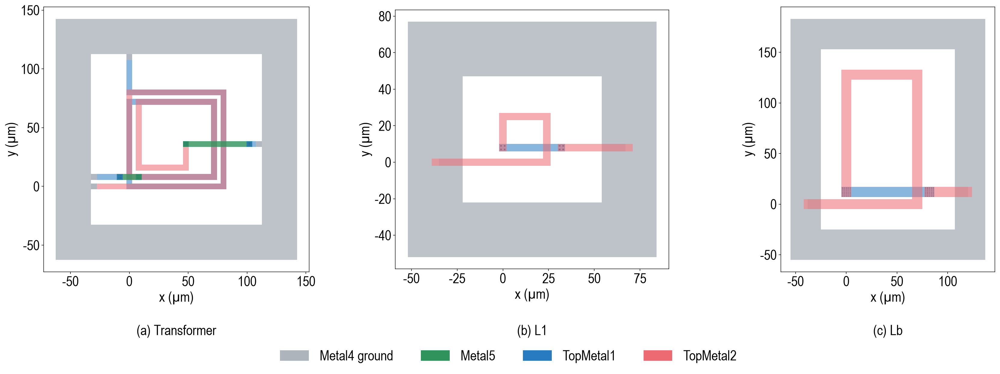

Figure 12. Final transformer and peaking-inductor layouts.

| Transformer parameter | Value | Unit |
|:--|:--|:--|
| topology | 1 | — |
| sb | 1 | — |
| pb | 3 | — |
| ps | 0 | — |
| m | 1 | — |
| u | 0 | % |
| us | 45 | % |
| w | 5.00 | µm |
| wp | 5.00 | µm |
| s | 3.00 | µm |
| ns | 2 | — |
| np | 2 | — |
| D | 80.00 | µm |
| gap | 30.00 | µm |

| Spiral parameter | L1 | Lb | Unit |
|:--|:--|:--|:--|
| w | 4.00 | 10.00 | µm |
| s | 4.00 | 2.00 | µm |
| n | 1 | 1 | turns |
| Dx | 24.00 | 70.00 | µm |
| Dy | 25.00 | 128.00 | µm |


##### HBT sizes

`N1` is the parallel unit-emitter multiplicity of Q1, `N2` is that of Q2, and `N3` is the multiplicity of each of Q3 and Q4. All four transistors use the `npn13G2` PDK subcircuit; these multiplicities set its `Nx` parameter. Each unit emitter has mask width 0.07 µm and mask length 0.90 µm. The PDK's effective-model defaults, `we=0.12 µm` and `le=0.96 µm`, are retained separately.

| Transistor | Size parameter | Parallel unit emitters Nx | Mask W × L per emitter (µm × µm) | Total emitter length (µm) |
|:--|:--|:--|:--|:--|
| Q1 | N1 | 2 | 0.07 × 0.90 | 1.80 |
| Q2 | N2 | 2 | 0.07 × 0.90 | 1.80 |
| Q3 | N3 | 3 | 0.07 × 0.90 | 2.70 |
| Q4 | N3 | 3 | 0.07 × 0.90 | 2.70 |

##### Resistors, capacitor and bias

| Device | Nominal value | Unit | PDK model | W (µm) | L (µm) | Role |
|:--|:--|:--|:--|:--|:--|:--|
| R1 | 920.56 | Ω | rppd | 2.00 | 6.81 | Q1 collector load |
| R2 | 79.12 | Ω | rppd | 7.58 | 2.04 | Q1 emitter feedback path |
| R3 | 29.49 | Ω | rppd | 20.00 | 2.00 | Q2 emitter degeneration |
| R4 | 200.00 | Ω | rppd | 3.00 | 2.04 | Q2 collector load |
| RF | 3000.00 | Ω | rppd | 2.00 | 22.81 | Shunt feedback around Q2 |
| RLn / RLp, each | 50.00 | Ω | rppd | 12.00 | 2.04 | Output back termination |
| C1 | 298.63 | fF | cap_cmim | 14.11 | 14.11 | Q2 emitter bypass |


| Bias or fixed testbench quantity | Value | Unit |
|:--|:--|:--|
| VCC (shared supply for Q1–Q4) | 2.50 | V |
| VB (Q1 base-bias supply) | 1.01 | V |
| IT | 5.45 | mA |
| Input capacitance Cpd | 220.00 | fF |
| External load, each output | 50.00 | Ω |
| Output coupling capacitor, each output | 1.00 | nF |
| Q4 bias-reference Rlp | 1.00 | kΩ |
| Q4 bias-reference Clp | 1.00 | µF |

Rlp and Clp form the testbench low-pass filter that provides Q4's base-bias reference through an ideal unity-gain buffer.

##### DC operating point

| Operating-point quantity | Value | Unit | Description |
|:--|:--|:--|:--|
| v(pd) | 0.14 | V | Photocurrent input node |
| v(e1) | 0.14 | V | Q1 emitter |
| v(b1) | 1.01 | V | Q1 base |
| v(c1) | 1.03 | V | Q1 collector and Q2 base |
| v(r2) | 0.14 | V | Transformer primary return / R2 node |
| v(t) | 0.79 | V | Q3/Q4 common emitter node |
| v(cn) | 2.36 | V | Q3 collector |
| v(cp) | 2.36 | V | Q4 collector |
| v(vbuf) | 1.65 | V | Q4 base |
| v(b2) | 1.65 | V | Q2 collector and Q3 base |
| v(e2) | 0.12 | V | Q2 emitter |
| i(vcc) | -1.13e-02 | A | VCC supply current |
| i(vb) | -2.81e-06 | A | VB source current for Q1 base bias |
| i(vq1) | 1.80e-03 | A | Q1 collector current |
| i(vq3) | 2.72e-03 | A | Q3 collector current |
| i(vq4) | 2.72e-03 | A | Q4 collector current |
| i(vq2) | 4.02e-03 | A | Q2 collector current |


In [9]:
if RUN_VERIFICATION:
    from IPython.display import display, Image
    final_result = json.loads((RESULT_ROOT / 'data/final_design.json').read_text())
    print(json.dumps({key: final_result[key] for key in
                      ('physical_inputs', 'spiral_geometries', 'params', 'metrics_em')}, indent=2))
    for name in ('figure-10.png', 'figure-11.png', 'figure-12.png'):
        display(Image(filename=str(RESULT_ROOT / 'figures' / name)))


The full-chain layout below illustrates device placement and routing. The independently EM-verified passive layouts and the final circuit parameters are reported in Section 8.2.


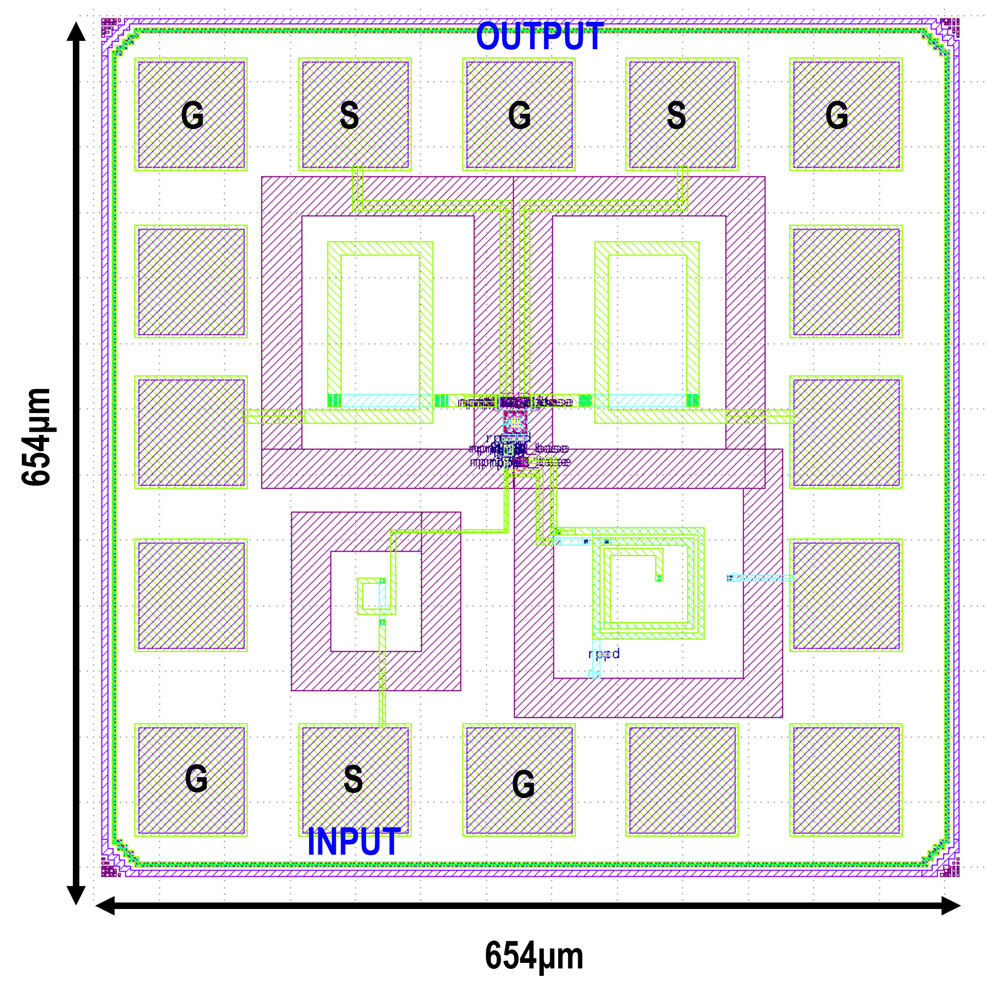

### 8.2 Case study 2 with better eye diagram

#### 8.2.1 Final TIA performance

| Metric | With transformer: EM-evaluated circuit | Without transformer |
|:--|:--|:--|
| Zt at 1 GHz (dBΩ) | 63.16 | 63.03 |
| −3 dB bandwidth (GHz) | 27.83 | 16.60 |
| Peaking (dB) | 0.00 | 0.00 |
| Group-delay variation (ps) | 9.38 | 3.20 |
| Input-noise estimate (pA/√Hz) | 21.14 | 23.13 |
| Power (mW) | 26.66 | 26.66 |

The optimized TIA passes the circuit, bias, voltage and physical-network checks. Its maximum transistor VCE is 1.59 V, below the SG13G2 limit of 1.60 V.

The no-transformer comparison replaces the windings with ideal direct connections e1–r2 and vb–b1. HBT sizes, R/C values, bias settings and the newly EM-evaluated L1/Lb networks are identical. Bandwidth is 27.83 GHz with the transformer and 16.60 GHz with the winding bypasses. Group-delay variation is evaluated from 1 GHz to min(BW, 26 GHz), giving upper limits of 26.00 and 16.60 GHz, respectively. It is proved that transformer is able to improve bandwidth significantly in TIA and EM surrogate for passives is valuable.

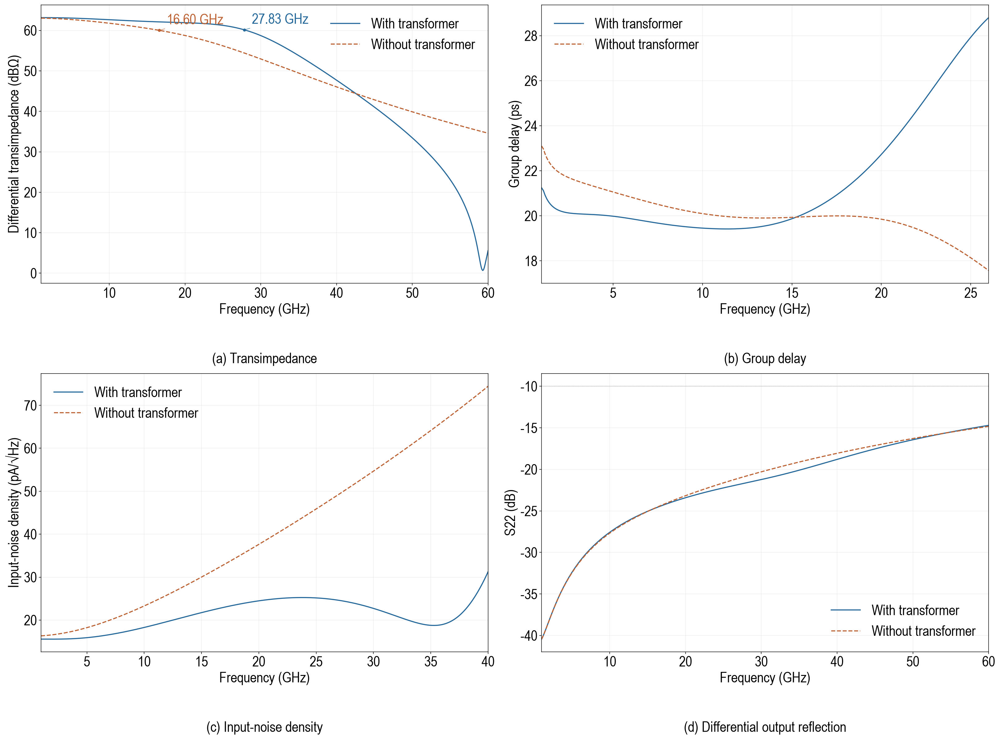

Figure 13. TIA transimpedance, group delay, input-noise estimate and differential S22 with the transformer (solid) and ideal winding bypasses (dashed).

##### NRZ and PAM4 eyes

The eye diagram setup is shown below.

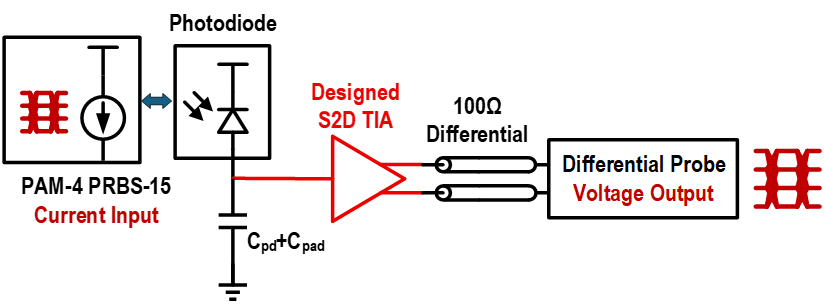

NRZ (PAM2) carries one bit per symbol, and Gray-coded PAM4 carries two. The two 50 Gb/s cases use 50 GBd NRZ and 25 GBd PAM4. The original 106.25 Gb/s PAM4 case at 53.125 GBd is retained as a higher-rate reference.

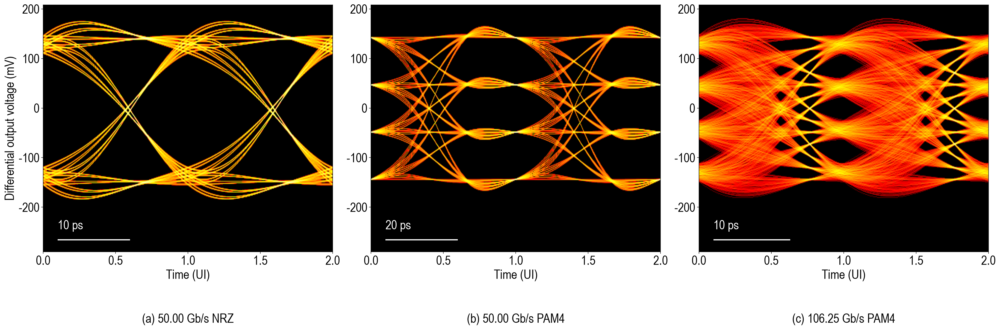

Figure 14. Noise-free linear eyes from the verified TIA response: (a) 50 Gb/s NRZ, (b) 50 Gb/s PAM4 and (c) 106.25 Gb/s PAM4, with 200 µA peak-to-peak input current. Colors show log trace density, scaled per panel; bars indicate time.

| Modulation | Bit rate (Gb/s) | Symbol rate (GBd) | Minimum eye height (mV) | Common width (UI / ps) |
|:--|:--|:--|:--|:--|
| NRZ | 50.00 | 50.00 | 228.51 | 0.87 / 17.50 |
| PAM4 | 50.00 | 25.00 | 93.45 | 0.66 / 26.33 |
| PAM4 | 106.25 | 53.12 | 46.63 | 0.30 / 5.73 |

Eye heights and common timing windows are evaluated from the same verified response for each modulation and rate. The rate sweep retains all evaluated cases.

Below the first saved AC sample, the real gain is held constant and the imaginary part approaches zero at DC. A raised-cosine taper removes the final 20% of the saved frequency band; the response is zero above it. Eye heights are finite-pattern level-envelope gaps. Width uses one fixed threshold for NRZ or three fixed thresholds at one common phase for PAM4. Display polarity may be reversed. This linear reconstruction excludes random noise, nonlinear swing, jitter and equalization and does not establish BER.

The eye reconstruction follows the procedure in Section 8.1.1, applied to the Case 2 frequency response.


#### 8.2.2 Passive and active design parameters

Circuit topology and device symbols follow the schematic in Section 1.1. Node names in the operating-point table follow the SPICE testbench. Tables display rounded values, with terminal percentages shown as integers. Case 2 parameter values are listed in this section.

##### Passive layouts and geometry

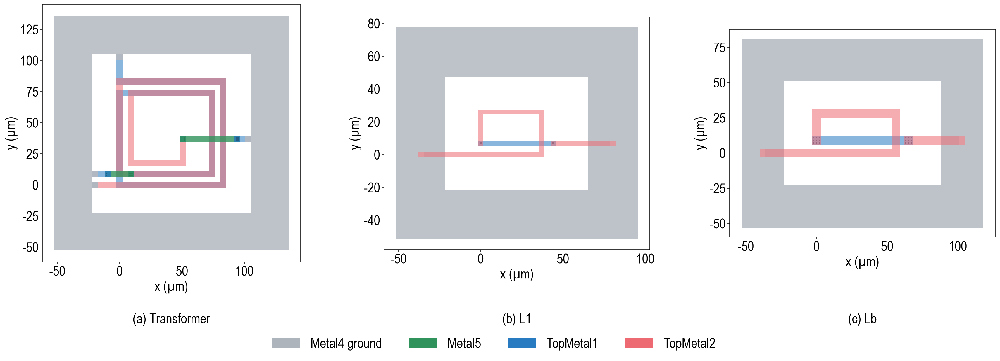

Figure 15. Final transformer and peaking-inductor layouts.

| Transformer parameter | Value | Unit |
|:--|:--|:--|
| topology | 1 | — |
| sb | 1 | — |
| pb | 3 | — |
| ps | 0 | — |
| m | 1 | — |
| u | 0 | % |
| us | 45 | % |
| w | 5.00 | µm |
| wp | 5.00 | µm |
| s | 4.00 | µm |
| ns | 2 | — |
| np | 2 | — |
| D | 83.00 | µm |
| gap | 20.00 | µm |

| Spiral parameter | L1 | Lb | Unit |
|:--|:--|:--|:--|
| w | 3.00 | 6.00 | µm |
| s | 4.00 | 3.00 | µm |
| n | 1 | 1 | turns |
| Dx | 37.00 | 56.00 | µm |
| Dy | 26.00 | 28.00 | µm |


##### HBT sizes

`N1` is the parallel unit-emitter multiplicity of Q1, `N2` is that of Q2, and `N3` is the multiplicity of each of Q3 and Q4. All four transistors use the `npn13G2` PDK subcircuit; these multiplicities set its `Nx` parameter. Each unit emitter has mask width 0.07 µm and mask length 0.90 µm. The PDK's effective-model defaults, `we=0.12 µm` and `le=0.96 µm`, are retained separately.

| Transistor | Size parameter | Parallel unit emitters Nx | Mask W × L per emitter (µm × µm) | Total emitter length (µm) |
|:--|:--|:--|:--|:--|
| Q1 | N1 | 2 | 0.07 × 0.90 | 1.80 |
| Q2 | N2 | 2 | 0.07 × 0.90 | 1.80 |
| Q3 | N3 | 3 | 0.07 × 0.90 | 2.70 |
| Q4 | N3 | 3 | 0.07 × 0.90 | 2.70 |

##### Resistors, capacitor and bias

| Device | Nominal value | Unit | PDK model | W (µm) | L (µm) | Role |
|:--|:--|:--|:--|:--|:--|:--|
| R1 | 1019.92 | Ω | rppd | 2.00 | 7.58 | Q1 collector load |
| R2 | 75.25 | Ω | rppd | 7.97 | 2.04 | Q1 emitter feedback path |
| R3 | 16.01 | Ω | rppd | 20.00 | 0.96 | Q2 emitter degeneration |
| R4 | 405.89 | Ω | rppd | 2.00 | 2.85 | Q2 collector load |
| RF | 2902.22 | Ω | rppd | 2.00 | 22.06 | Shunt feedback around Q2 |
| RLn / RLp, each | 50.00 | Ω | rppd | 12.00 | 2.04 | Output back termination |
| C1 | 425.55 | fF | cap_cmim | 16.84 | 16.84 | Q2 emitter bypass |


| Bias or fixed testbench quantity | Value | Unit |
|:--|:--|:--|
| VCC (shared supply for Q1–Q4) | 2.50 | V |
| VB (Q1 base-bias supply) | 1.01 | V |
| IT | 6.93 | mA |
| Input capacitance Cpd | 220.00 | fF |
| External load, each output | 50.00 | Ω |
| Output coupling capacitor, each output | 1.00 | nF |
| Q4 bias-reference Rlp | 1.00 | kΩ |
| Q4 bias-reference Clp | 1.00 | µF |

Rlp and Clp form the testbench low-pass filter that provides Q4's base-bias reference through an ideal unity-gain buffer.

##### DC operating point

| Operating-point quantity | Value | Unit | Description |
|:--|:--|:--|:--|
| v(pd) | 0.14 | V | Photocurrent input node |
| v(e1) | 0.14 | V | Q1 emitter |
| v(b1) | 1.01 | V | Q1 base |
| v(c1) | 0.90 | V | Q1 collector and Q2 base |
| v(r2) | 0.14 | V | Transformer primary return / R2 node |
| v(t) | 0.74 | V | Q3/Q4 common emitter node |
| v(cn) | 2.33 | V | Q3 collector |
| v(cp) | 2.33 | V | Q4 collector |
| v(vbuf) | 1.62 | V | Q4 base |
| v(b2) | 1.62 | V | Q2 collector and Q3 base |
| v(e2) | 0.03 | V | Q2 emitter |
| i(vcc) | -1.07e-02 | A | VCC supply current |
| i(vb) | -2.82e-06 | A | VB source current for Q1 base bias |
| i(vq1) | 1.82e-03 | A | Q1 collector current |
| i(vq3) | 3.46e-03 | A | Q3 collector current |
| i(vq4) | 3.46e-03 | A | Q4 collector current |
| i(vq2) | 1.92e-03 | A | Q2 collector current |


Based on the end-to-end co-design results, the complete physical layout of the full-chain TIA is assembled as shown below, with all EM-verified passive structures (feedback transformer, $L_1$, and $L_b$), active HBT sizes, R/C device dimensions, and DC biasing conditions fully determined. For future tape-out preparation, the parasitic effects of inter-stage interconnect routing remain to be EM-extracted, and the on-chip DC bypass network and supply distribution will be further refined.

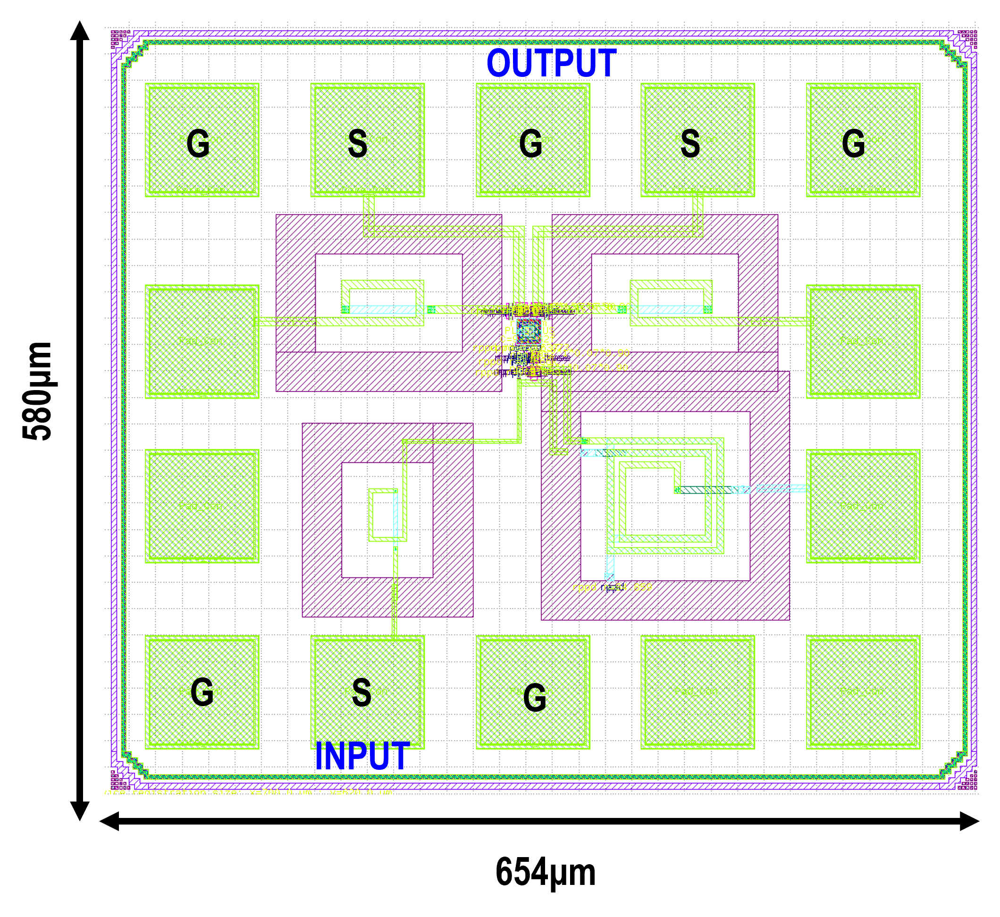

Figure 16. Full-chain TIA layout for Case 2.


## Conclusion

This work demonstrates an end-to-end, open-source passive–active co-design workflow for a full-chain, three-stage transformer-feedback SiGe TIA in IHP SG13G2 technology. Rather than optimizing an isolated passive component, the flow jointly addresses heterogeneous multi-port and two-port passives—combining a 14-parameter, 4-port feedback transformer (supporting selectable edge/broadside coupling, multilayer windings and variable terminal routing) with parameterized 2-port peaking spirals ($L_1$, $L_b$).

Trained on openEMS full-wave datasets, the residual MLP surrogate ensembles accurately capture the underlying physical dependencies ($L$, $Q$, $k$ and $\mathrm{SRF}$) and replace costly EM evaluations inside the ngspice loop. Using constrained multivariate TPE from random initialization followed by EM-guided active-parameter refinement, the optimizer simultaneously tunes passive layout geometries, active HBT bias operating points and R/C network values while enforcing collector current-density ($1.00\text{–}3.00\,\mathrm{mA/\mu m}$) and reliability ($V_{\mathrm{CE}} \le 1.60\,\mathrm{V}$) limits.

Independent full-wave EM re-verification of the synthesized GDSII layouts and circuit replay confirm a $59.45\,\mathrm{dB\Omega}$ transimpedance gain at $1\,\mathrm{GHz}$, $8.66\,\mathrm{ps}$ group-delay variation, a $21.13\,\mathrm{pA/\sqrt{Hz}}$ testbench input-noise estimate and $28.19\,\mathrm{mW}$ DC power consumption. Compared with an identical baseline without transformer feedback, the co-designed transformer extends the $-3\,\mathrm{dB}$ bandwidth from $22.11\,\mathrm{GHz}$ to $35.75\,\mathrm{GHz}$. In additional, second study case is demonstrated for better eye diagram, proving our work flow is generalized and feasible for different applications. Finally, deterministic linear time-domain reconstructions from the EM-verified frequency response quantify finite-pattern intersymbol interference for $50\,\mathrm{Gb/s}$ NRZ, $50\,\mathrm{Gb/s}$ PAM4 and $106.25\,\mathrm{Gb/s}$ PAM4 modulation.


## Acknowledgement

The authors acknowledge support from the Swiss State Secretariat for Education, Research and Innovation (SERI) through the SwissChips initiative. The authors thank CSEM for providing computational infrastructure and support.

## References

[1] E. Säckinger, *Analysis and Design of Transimpedance Amplifiers for Optical Receivers*. Wiley, 2017. doi: 10.1002/9781119264422.

[2] IHP, *IHP Open Source PDK: SG13G2 Process Specifications and Device Models*, source revision 5e6d592e4002.

[3] T. Liebig, A. Rennings, S. Held, and D. Erni, “openEMS – a free and open source equivalent-circuit (EC) FDTD simulation platform supporting cylindrical coordinates suitable for the analysis of traveling wave MRI applications,” *Int. J. Numer. Model.*, vol. 26, no. 6, pp. 680–696, 2013. doi: 10.1002/jnm.1875.

[4] ngspice Development Team, *Ngspice User’s Manual*, version 47, 2026.

[5] A. Paszke et al., “PyTorch: An imperative style, high-performance deep learning library,” in *Advances in Neural Information Processing Systems*, vol. 32, 2019.

[6] I. Loshchilov and F. Hutter, “Decoupled weight decay regularization,” in *Proc. Int. Conf. Learning Representations (ICLR)*, 2019.

[7] J. S. Bergstra, R. Bardenet, Y. Bengio, and B. Kégl, “Algorithms for hyper-parameter optimization,” in *Advances in Neural Information Processing Systems*, vol. 24, 2011.

[8] T. Akiba, S. Sano, T. Yanase, T. Ohta, and M. Koyama, “Optuna: A next-generation hyperparameter optimization framework,” in *Proc. ACM SIGKDD Int. Conf. Knowledge Discovery and Data Mining*, 2019. arXiv:1907.10902.
